# Generating images of British and Irish butterfly specimens with a deep convolutional GAN

**Patrick Gilliland**, AI Mastery Capstone: Generative AI Applications

This notebook trains a generative adversarial network (GAN) to make new 64 by 64 colour images of butterfly specimens, as the Natural History Museum (NHM) photographs them in its iCollections unit trays. `generative_model.ipynb` and `generative_ai.ipynb` are the same notebook under the two names the brief uses. The report ships as `Generative_AI_Analysis_Report.pdf` and, with the same content, as `module_summary.pdf`. The works cited here are listed in the report's References.

**Run notes.** The notebook trains on a graphics processing unit (GPU) when one is visible, and otherwise on the central processing unit (CPU).

| Item | This notebook |
|---|---|
| Rig | NVIDIA GeForce RTX 5090 graphics card, Intel Core Ultra 9 285K processor, Linux under Windows Subsystem for Linux (WSL2) |
| Python | 3.12.3 |
| PyTorch | 2.14.1 from the Python Package Index (PyPI) |
| Compute Unified Device Architecture (CUDA) | 13.0 (the runtime PyTorch ships with), with the CUDA Deep Neural Network library (cuDNN) 9.24.0 |

The measured GPU training time and the estimated CPU training time, both from the last full run, are in Task 4's run-summary table.

## Task 1: Define the Generative Task and Select Your Approach

**Goal.** I train a generative model that makes new 64 by 64 colour images of British and Irish butterfly specimens, pinned and photographed as the Museum photographs them. The content it produces is images, generated from random noise. There is no prompt and no class label: the generator turns a vector of 100 random numbers into one image.

**Approach.** From the brief's list, "Generative Adversarial Network (GAN) for image generation". The model is an unconditional deep convolutional GAN (DCGAN) at 64 by 64 pixels, written and trained in this notebook with no pre-trained network. Task 3 explains each design choice.

**Data.**
- **Publisher.** The Natural History Museum, London, on its Data Portal (https://data.nhm.ac.uk), Specimens resource `05ff2255-c38a-40c9-b657-4ccb55ab2feb`.
- **Selection.** The iCollections British and Irish butterflies (Paterson et al., 2016): order Lepidoptera, project iCollections, the six butterfly families one query at a time. Each record has one specimen photograph under Creative Commons Attribution 4.0 (CC BY 4.0). Records with more than one specimen photograph were left out, and Task 2 counts them above its anomaly table.
- **Licence.** CC BY 4.0, checked on each image's own licence field. I credit the Museum in the form it asks for. Its terms say it cannot warrant the data, and nothing here suggests that it endorses this work.
- **Size and download.** 22,000 photographs, one per specimen, downloaded on 13 October 2026 in a seed-2026 random order by `scripts/download_nhm_images.py`. That script runs once, outside this notebook. The fixed manifest, `data/manifest_fixed_20261013.csv`, lists every photograph with its Secure Hash Algorithm 256 (SHA-256) hash, and the cell after the environment check prints the manifest's own hash.
- **How it is used.** `scripts/build_working_set.py` crops each photograph to the specimen, set to leave out the ruler and the labels, and resizes it to 64 by 64. A seeded 10 per cent of the specimens is held out, and the held-out images never train the model or choose a model setting. All crops are used, in training and in the evaluation. The crop flag, the crop rule's automatic check for failed crops, is reported in Task 2 as a finding about the data preparation, and never used to leave a crop out.

**The brief's dataset rules.**

| Rule (brief) | How this dataset meets it |
|---|---|
| Be appropriate for the chosen generative task | Thousands of photographs of one kind of object, taken to one protocol (Paterson et al., 2016, p. 4), which suits an image GAN |
| Be publicly available or clearly documented | Public on the NHM Data Portal under CC BY 4.0. The manifest and the download script document every photograph |
| Be appropriate for academic use | CC BY 4.0 allows reuse with attribution. The crop is set to leave out the labels, which carry collectors' handwriting and names. Of the 600 crops scored by eye before training, 21 kept part of a label or card (Tasks 2 and 4). The manifest keeps no field that names a person |
| Not be synthetic or AI-generated as a dataset | Photographs of real museum specimens |
| Not be reused from any previous capstone project | No earlier capstone project of mine used it. The prior-use search made before the dataset was chosen found none |

**How this could be used in the real world.** Three uses, ranked by the evidence. Each is my proposal. The first two are untested here, and the third is the idea I tested in Task 4, where it failed.
1. **Images of rare species for identification tools.** Species photographs are uneven: "the natural world is heavily imbalanced, as some species are more abundant and easier to photograph than others" (Van Horn et al., 2018, p. 8769). A GAN can be conditioned on a class label (Odena et al., 2017, p. 2642). My proposal, as a next step: a conditional version of this GAN could add images of rare species to a training set. This notebook's GAN is unconditional and cannot choose a species.
2. **Material for spotting forged specimens.** The butterfly trade is regulated, and a guide for border officers notes that "Commercial shipments routinely use false declarations on import" (Environment Canada, 2000, "Why Are Butterflies Imported?" section). My proposal: generated fakes could help train people or tools to tell a real specimen photograph from a made one. No source I hold shows this done.
3. **A quality flag for museum digitisation, tested here.** Museums photograph specimens in bulk and check the images afterwards. A European report on digitisation describes "the quality control activities that are performed after digitisation" (Nieva de la Hidalga et al., 2019, p. 3). The Museum and the Royal Botanic Garden Edinburgh describe a tool for "detecting missing objects (such as colour reference cards or barcodes), identifying cropping errors" on herbarium sheets (Zhang et al., 2026). In factory inspection, models learn from defect-free images alone, because "only a very limited amount of images with defects is available" (Bergmann et al., 2019, p. 9593). My proposal: a discriminator trained on normal specimen photographs could score new ones and pass the oddest to a person. Task 4 tests this once, in an exploratory comparison where this discriminator showed no useful separation, so the use needs a model trained for it, as Task 4 sets out.

**Setup.** The first code cell sets two environment variables before PyTorch loads, seeds every random number generator and prints each seed. It fixes the settings that make a rerun repeat its numbers. When a GPU is visible, it prints the device, caps PyTorch at half the card's memory and prints how much of the 5090's memory is in use. That reading is for the record and never stops the notebook.

The cell also defines the training watchdog that Task 3 uses. A loss that is not a number stops a run anywhere. This rig means this machine: an NVIDIA GeForce RTX 5090 with 32,607 mebibytes (MiB) of memory, in a machine with 93.9 gibibytes (GiB) of random access memory (RAM). The cell checks all three before any training. On this rig the watchdog also stops a run on an epoch over three times the median epoch before it, on more than 20,000 MiB in use on the 5090, or past 30 minutes. On any other machine, those three lines only print a warning, so a slower or shared machine still runs the notebook to the end.

In [1]:
import math
import os
import platform
import random
import statistics
import subprocess
import sys
import time
from pathlib import Path

# I pin the RTX 5090 (device 0) whatever the shell sets, because the rig's
# shell can show both its cards. The empty string is left alone: it hides
# every GPU for a CPU run. Deterministic cuBLAS needs its workspace set
# before torch loads.
if os.environ.get("CUDA_VISIBLE_DEVICES") != "":
    os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import numpy as np  # noqa: E402
import torch  # noqa: E402

SEED_DATA = 2026  # the download order, the split, the audit's 400 crops
SEED_TRAIN = 42  # training, the fixed noise and 64 training images
SEED_SAMPLES = 7  # the 64 numbered samples and the held-out grid
random.seed(SEED_TRAIN)
np.random.seed(SEED_TRAIN)
torch.manual_seed(SEED_TRAIN)
torch.cuda.manual_seed_all(SEED_TRAIN)

# Deterministic cuDNN kernels, no autotuning and no TF32, so a rerun gives
# the same numbers and the arithmetic stays float32.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

# This rig, read on 14 Oct 2026: the card's full name, its memory as
# nvidia-smi gives it (PyTorch reads 28 MiB less) and the RAM WSL gives the
# machine.
RIG_GPU = "NVIDIA GeForce RTX 5090"
RIG_GPU_MIB = 32607
RIG_RAM_GIB = 93.9
MEMORY_LINE_MIB = 20000
BUDGET_SECONDS = 1800.0


def smi_used_mib(text, name=RIG_GPU):
    """The memory in use, in MiB, on the first nvidia-smi row naming name.

    text is nvidia-smi's CSV output, with or without an index column and
    units. Returns None when no row names the card, or when its reading is
    not a number, such as "[N/A]"."""
    for line in text.splitlines():
        fields = [f.strip() for f in line.split(",")]
        for k, field in enumerate(fields[:-1]):
            if name in field:
                try:
                    return int(fields[k + 1].split()[0])
                except (ValueError, IndexError):
                    return None
    return None


def used_mib():
    """The 5090's memory in use, in MiB, or None with no GPU visible.

    Under WSL, torch.cuda.mem_get_info leaves out the Windows apps' share,
    so the reading is the larger of it and the card's nvidia-smi row, or
    mem_get_info alone where nvidia-smi is missing or has no 5090 row."""
    if not torch.cuda.is_available():
        return None
    free, total = torch.cuda.mem_get_info()
    readings = [(total - free) // 2**20]
    try:
        smi = subprocess.run(
            [
                "nvidia-smi",
                "--query-gpu=name,memory.used",
                "--format=csv,noheader,nounits",
            ],
            capture_output=True,
            text=True,
            timeout=10,
            check=False,
        ).stdout
    except (OSError, subprocess.TimeoutExpired):
        smi = ""
    row = smi_used_mib(smi)
    if row is not None:
        readings.append(row)
    return max(readings)


def host_ram_gib():
    """The RAM visible to this process, in GiB, or None where the system
    does not report it."""
    try:
        return os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30
    except (AttributeError, ValueError, OSError):
        return None


def is_this_rig(gpu_name, gpu_mib, ram_gib, mib_slack=128, gib_slack=1.0):
    """True when the GPU and RAM are this rig's, as a bool: the card's full
    name, its memory within mib_slack MiB and the RAM within gib_slack GiB.
    A reading of None is never the rig, so an unknown machine only warns."""
    if gpu_mib is None or ram_gib is None:
        return False
    return (
        gpu_name == RIG_GPU
        and abs(gpu_mib - RIG_GPU_MIB) <= mib_slack
        and abs(ram_gib - RIG_RAM_GIB) <= gib_slack
    )


def watchdog(
    loss,
    epoch_seconds,
    elapsed_seconds,
    used,
    on_rig,
    factor=3.0,
    budget_seconds=BUDGET_SECONDS,
    line_mib=MEMORY_LINE_MIB,
):
    """Why a training run should stop, and any warning, as (stop, warning).

    Either is None when it does not apply. A loss that is not finite stops
    a run anywhere. On the rig, used MiB above line_mib, an epoch slower
    than factor times the median of the epochs before it, or a run past
    budget_seconds stops it too. Elsewhere each of those only warns,
    because a slower or shared machine can pause or hold memory with
    nothing wrong in training, so the notebook still runs to the end. Every
    line is strict."""
    if not math.isfinite(loss):
        return f"the loss is {loss}", None
    if used is not None and used > line_mib:
        if on_rig:
            return f"the 5090 has {used} MiB in use, over {line_mib} MiB", None
        return None, (
            f"more than {line_mib} MiB is in use on this GPU, so I carry on "
            "off the rig"
        )
    if len(epoch_seconds) > 1:
        line = factor * statistics.median(epoch_seconds[:-1])
        if epoch_seconds[-1] > line:
            slow = (
                f"the epoch took {epoch_seconds[-1]:.1f} s, "
                f"over {line:.1f} s"
            )
            if on_rig:
                return slow, None
            return None, f"{slow}, so I carry on off the rig"
    if elapsed_seconds > budget_seconds:
        minutes = f"{budget_seconds / 60:g} minutes"
        if on_rig:
            return f"the run passed {minutes}", None
        return None, f"the run passed {minutes}, so I carry on off the rig"
    return None, None


print(
    f"Python {platform.python_version()}, PyTorch {torch.__version__}, "
    f"NumPy {np.__version__}"
)
print(
    f"Seeds: data {SEED_DATA}, training {SEED_TRAIN}, samples {SEED_SAMPLES}"
)
print(
    f"CUDA_VISIBLE_DEVICES={os.environ['CUDA_VISIBLE_DEVICES']!r}, "
    f"CUBLAS_WORKSPACE_CONFIG={os.environ['CUBLAS_WORKSPACE_CONFIG']!r}"
)
on_gpu = torch.cuda.is_available()
if on_gpu:
    name = torch.cuda.get_device_name(0)
    gpu_mib = torch.cuda.get_device_properties(0).total_memory // 2**20
    on_rig = is_this_rig(name, gpu_mib, host_ram_gib())
    cudnn = torch.backends.cudnn.version()
    print(
        f"Device: cuda, {name}, CUDA {torch.version.cuda}, "
        f"cuDNN {cudnn // 10000}.{cudnn % 10000 // 100}.{cudnn % 100}"
    )
    if not on_rig:
        print(
            f"Warning: not this rig, the {RIG_GPU} with {RIG_GPU_MIB} MiB "
            f"and {RIG_RAM_GIB} GiB of RAM, so the watchdog only warns"
        )
    # Half the card at most, by this rig's GPU rules.
    torch.cuda.set_per_process_memory_fraction(0.5)
    print(f"GPU memory cap: half the card. In use on it now: {used_mib()} MiB")
else:
    on_rig = False
    print("Device: cpu, no GPU visible, so the watchdog only warns")

Python 3.12.3, PyTorch 2.14.1+cu130, NumPy 2.5.4
Seeds: data 2026, training 42, samples 7
CUDA_VISIBLE_DEVICES='0', CUBLAS_WORKSPACE_CONFIG=':4096:8'
Device: cuda, NVIDIA GeForce RTX 5090, CUDA 13.0, cuDNN 9.24.0


GPU memory cap: half the card. In use on it now: 5470 MiB


**What the setup shows.** The run used the RTX 5090 with the versions in the title table, and fixed seeds for the data, the training and the samples. PyTorch is capped at half the card, and the memory already in use is printed for the record only.

**Environment check.** The brief's own validation code, as given, reading this project's data file, the fixed manifest. In one cell only the last line's value is shown, so `device` on its own line prints nothing here. The setup cell above prints the device.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
device
df = pd.read_csv("data/manifest_fixed_20261013.csv")
df.head()

,occurrence_id,catalog_number,family,genus,species,country,image_url,rendition,download_url,licence,file_name,sha256,bytes,width,height,download_utc
0,d3a4acf9-13dc-42bf-b13a-85e20cd62514,BMNH(E)1038104,Nymphalidae,Aphantopus,hyperantus,United Kingdom,https://data.nhm.ac.uk/media/b9470c19-d4cf-439...,original,https://data.nhm.ac.uk/media/b9470c19-d4cf-439...,http://creativecommons.org/licenses/by/4.0/,BMNH-E-1038104_d3a4acf913dc42bfb13a85e20cd6251...,7cb05980550f9c5c321265dbcd93b33292f73df686da37...,139014,1440,960,2026-10-13T17:40:00Z
1,1403dc68-1fbf-4f26-964f-e0ece3da28b9,BMNH(E)1038105,Nymphalidae,Aphantopus,hyperantus,United Kingdom,https://data.nhm.ac.uk/media/06491a4b-f253-44c...,original,https://data.nhm.ac.uk/media/06491a4b-f253-44c...,http://creativecommons.org/licenses/by/4.0/,BMNH-E-1038105_1403dc681fbf4f26964fe0ece3da28b...,327b36c56a9e9244638e02aa1029d48935e3a400f304e3...,148736,1440,960,2026-10-13T18:40:30Z
2,33dd91df-c8a1-4d83-99bc-a47f4b48c157,BMNH(E)1038110,Nymphalidae,Aphantopus,hyperantus,United Kingdom,https://data.nhm.ac.uk/media/420495a5-3c7b-46a...,original,https://data.nhm.ac.uk/media/420495a5-3c7b-46a...,http://creativecommons.org/licenses/by/4.0/,BMNH-E-1038110_33dd91dfc8a14d8399bca47f4b48c15...,43b8685b9896fe9ff1dc43a2f5c6b9629cfb0a369dd3d0...,159091,1440,960,2026-10-13T16:43:35Z
3,2f9f0e9a-ba00-4988-a633-87453f980509,BMNH(E)1038115,Nymphalidae,Aphantopus,hyperantus,United Kingdom,https://data.nhm.ac.uk/media/897860cb-5b64-475...,original,https://data.nhm.ac.uk/media/897860cb-5b64-475...,http://creativecommons.org/licenses/by/4.0/,BMNH-E-1038115_2f9f0e9aba004988a63387453f98050...,210337dad473e3fa75ed043e7dfdddccf88067291115c2...,310657,1440,2160,2026-10-13T17:44:18Z
4,0d630cab-f8b2-4df3-a3fc-adad35685fd5,BMNH(E)1038140,Nymphalidae,Aphantopus,hyperantus,Ireland,https://data.nhm.ac.uk/media/32e4f459-6944-405...,original,https://data.nhm.ac.uk/media/32e4f459-6944-405...,http://creativecommons.org/licenses/by/4.0/,BMNH-E-1038140_0d630cabf8b24df3a3fcadad35685fd...,7cc16172ebfde0cde3b14506822fae181abf0c14d04415...,284676,1440,2160,2026-10-13T15:53:44Z


**What the environment check shows.** The brief's code runs here and reads the fixed manifest, showing its first five rows. Each row is one photograph: its specimen, licence, file and download time.

**The fixed set.** The next cell loads the crop rule and the split from the repository's `scripts/build_working_set.py`, then checks the manifest against the hash it was frozen with and prints when the photographs were downloaded.

In [3]:
# The crop rule, the flag and the split live in the repository's scripts
# folder, so the notebook and the array builder share one copy.
sys.path.insert(0, str(Path("scripts").resolve()))
import build_working_set as bws  # noqa: E402

# True rebuilds the submitted dataset, so a file whose hash differs from the
# one frozen for the submitted run stops the notebook. I would set it to
# False only to train on a new set of photographs, which then warns instead.
REPRODUCE = True


def hash_mismatches(found, frozen):
    """The names in frozen whose hash in found differs or is missing, in
    frozen's order, as a new list."""
    return [name for name, value in frozen.items() if found.get(name) != value]


MANIFEST = Path("data/manifest_fixed_20261013.csv")
MANIFEST_SHA256 = (
    "920fd9330771a12403a8cd07dea9b145dad633b7a86de81847b8a6c237cbbc80"
)
manifest = pd.read_csv(MANIFEST, keep_default_na=False)
manifest_digest = bws.file_sha256(MANIFEST)
print(f"Fixed manifest: {MANIFEST}, {len(manifest):,} photographs")
print(
    f"SHA-256 {manifest_digest}, the frozen hash: "
    f"{manifest_digest == MANIFEST_SHA256}"
)
frozen_manifest = {"manifest": MANIFEST_SHA256}
if hash_mismatches({"manifest": manifest_digest}, frozen_manifest):
    if REPRODUCE:
        raise ValueError(
            "this is not the submitted manifest, so the run would not rebuild "
            "the submitted dataset"
        )
    print("Warning: a new manifest, so this trains on a new dataset")
print(
    f"Downloaded from {manifest['download_utc'].min()} to "
    f"{manifest['download_utc'].max()} (UTC), in a seed-{SEED_DATA} order"
)
print(
    f"Held out for evaluation: {bws.HELD_OUT_FRACTION * 100:.0f} per cent "
    f"of the specimens, seed {bws.SEED}"
)

Fixed manifest: data/manifest_fixed_20261013.csv, 22,000 photographs
SHA-256 920fd9330771a12403a8cd07dea9b145dad633b7a86de81847b8a6c237cbbc80, the frozen hash: True
Downloaded from 2026-10-13T14:59:57Z to 2026-10-13T19:00:32Z (UTC), in a seed-2026 order
Held out for evaluation: 10 per cent of the specimens, seed 2026


**What the manifest check shows.** The manifest's 22,000 photographs match the hash it was frozen with, so this is the set downloaded on 13 October 2026. The split holds out 10 per cent of the specimens, drawn with seed 2026.

## Task 2: Load and Inspect Your Data or Prompt Source

**Goal.** Load the fixed manifest and the 64 by 64 working arrays, then show real photographs and their crops, and inspect the data's structure, formats and sizes before any model sees it. Every cell here reads only `data/`: the manifest, the arrays and row table that `scripts/build_working_set.py split` writes, and the ten photographs in `data/figure_photos/` that Figures 1 and 2 show. It also reads the crop audit's verdicts, `data/crop_audit_600.csv`, and the download's list of skipped records, `data/candidates_skipped.csv`.

In [4]:
from IPython.display import display  # noqa: E402

STEM = "data/nhm_butterflies_64"
PARTS = ("training", "held_out", "flagged")
array_paths = {part: Path(f"{STEM}_{part}.npy") for part in PARTS}
rows_path = Path(f"{STEM}_rows.csv")
# The SHA-256 of each file the split wrote for the submitted run.
FROZEN = {
    "training": (
        "4b697a5536b0329ac4b9972fa6bdfebfe898fdc5263bef3380734ab6f43bc131"
    ),
    "held_out": (
        "dfbdb68e728444c3da975b2944df760e847d6c11ee2f087f2bd20700791ff568"
    ),
    "flagged": (
        "b9ba67c14c869ef788dee3e334ae717a59d13c2c1d59574d53b3afde6e09315d"
    ),
    "rows": "3e6f0870d568801926de6688cf43a56a2e15bc9a21876b3dc1600a502c4bc52b",
}


def missing_parts(paths):
    """The paths that are not on disk, in the order given, as a new list."""
    return [path for path in paths if not Path(path).exists()]


bundle = [*array_paths.values(), rows_path]
missing = missing_parts(bundle)
if missing and len(missing) < len(bundle):
    # The split writes all four files together and never overwrites one, so
    # a part-built set has to be moved aside before it can be rebuilt.
    raise RuntimeError(
        f"the working set is incomplete: {', '.join(map(str, missing))} "
        f"missing. Move the other {STEM}_* files out of data/, then run this "
        "cell again to rebuild all four"
    )
if missing:
    # Rebuilding crops and flags all 22,000 photographs: 184 seconds on this
    # rig with 12 worker processes. This call uses 8, so it takes longer.
    started = time.perf_counter()
    status = bws.main(
        [
            "split",
            "--manifest",
            str(MANIFEST),
            "--raw-dir",
            "data/raw",
            "--out",
            STEM,
            "--workers",
            "8",
        ]
    )
    if status != 0:
        raise RuntimeError("the working arrays could not be built")
    print(f"Rebuilt the arrays in {time.perf_counter() - started:.0f} s")
arrays = {part: np.load(path) for part, path in array_paths.items()}
rows = pd.read_csv(rows_path, keep_default_na=False)
if list(rows["file_name"]) != list(manifest["file_name"]):
    raise ValueError("the row table is not in the manifest's order")
found = {part: bws.file_sha256(path) for part, path in array_paths.items()}
found["rows"] = bws.file_sha256(rows_path)
for part, path in array_paths.items():
    print(f"{path}: SHA-256 {found[part]}")
print(
    f"{rows_path}: {len(rows):,} rows, one per manifest row, SHA-256 "
    f"{found['rows']}"
)
differ = hash_mismatches(found, FROZEN)
if differ and REPRODUCE:
    raise ValueError(
        f"not the submitted working set: {', '.join(differ)} differ from the "
        "frozen hashes"
    )
print(
    "Every file matches the hash frozen for the submitted run"
    if not differ
    else f"Warning: {', '.join(differ)} differ, so this is a new dataset"
)

data/nhm_butterflies_64_training.npy: SHA-256 4b697a5536b0329ac4b9972fa6bdfebfe898fdc5263bef3380734ab6f43bc131
data/nhm_butterflies_64_held_out.npy: SHA-256 dfbdb68e728444c3da975b2944df760e847d6c11ee2f087f2bd20700791ff568
data/nhm_butterflies_64_flagged.npy: SHA-256 b9ba67c14c869ef788dee3e334ae717a59d13c2c1d59574d53b3afde6e09315d
data/nhm_butterflies_64_rows.csv: 22,000 rows, one per manifest row, SHA-256 3e6f0870d568801926de6688cf43a56a2e15bc9a21876b3dc1600a502c4bc52b
Every file matches the hash frozen for the submitted run


**What the load shows.** The three working arrays and the row table match the hashes frozen for the submitted run, so this run reads the same data. The row table has one row for each of the 22,000 manifest rows.

**The manifest.** One row per photograph: the specimen's identifiers and names, where it was collected, both download addresses, the licence, the file's name, hash, size in bytes and pixel size, and when it was downloaded. Nothing in it names a person. The tables count the photographs by family and by country.

In [5]:
def count_table(values, name):
    """Counts and per cent shares of values, largest first, as a new frame.

    A blank value is shown as "(blank)", so a missing country is counted
    and not dropped."""
    counts = values.replace("", "(blank)").value_counts()
    return pd.DataFrame(
        {
            name: counts.index,
            "images": counts.to_numpy(),
            "per cent": (100 * counts.to_numpy() / counts.sum()).round(1),
        }
    )


CC_BY = "http://creativecommons.org/licenses/by/4.0/"
print(f"Shape: {manifest.shape[0]:,} rows by {manifest.shape[1]} columns")
print(manifest.dtypes.to_string())
licensed = int((manifest["licence"] == CC_BY).sum())
print(f"Rows whose own licence field is CC BY 4.0: {licensed:,}")
print("Photographs by source rendition and pixel size:")
print(manifest.groupby(["rendition", "width", "height"]).size().to_string())
print(f"512-pixel renditions: {(manifest['rendition'] != 'original').sum()}")
display(count_table(manifest["family"], "family"))
display(count_table(manifest["country"], "country"))

Shape: 22,000 rows by 16 columns
occurrence_id       str
catalog_number      str
family              str
genus               str
species             str
country             str
image_url           str
rendition           str
download_url        str
licence             str
file_name           str
sha256              str
bytes             int64
width             int64
height            int64
download_utc        str
Rows whose own licence field is CC BY 4.0: 22,000
Photographs by source rendition and pixel size:
rendition                    width  height
full/!512,512/0/default.jpg  341    512         136
                             512    341          29
original                     1440   960        7292
                                    2160      14543
512-pixel renditions: 165


,family,images,per cent
0,Lycaenidae,9397,42.7
1,Nymphalidae,8520,38.7
2,Pieridae,2713,12.3
3,Hesperiidae,1056,4.8
4,Riodinidae,213,1.0
5,Papilionidae,101,0.5


,country,images,per cent
0,United Kingdom,18944,86.1
1,(blank),2064,9.4
2,Ireland,968,4.4
3,Isle of Man,24,0.1


**What the tables show.** Every row carries the CC BY 4.0 licence on its own image. Two families, Lycaenidae (the blues, coppers and hairstreaks) and Nymphalidae (the browns, fritillaries, admirals and tortoiseshells), make up most of the set. Pieridae (the whites and yellows), Hesperiidae (the skippers) and Riodinidae (here only the Duke of Burgundy) follow, and Papilionidae, the swallowtails, are the fewest. Most photographs come from the United Kingdom, with Ireland and the Isle of Man after it, and some have no country, so I never call the set "UK only". Most photographs are 1,440 pixels wide, portrait or landscape, and a few are the Museum's 512-pixel rendition. The crop works in proportions of the photograph, so both sizes crop alike.

**Real photographs (Figure 1).** Six training photographs, drawn with seed 42 from those whose crop the flag passed. Each is shown whole, with the ruler, and with the label section beyond the crop painted grey, because the labels carry collectors' handwriting and names. I mask both the side where the rule found the labels and the side where a tray of that shape keeps them, in case the rule read the side wrongly. Their attribution lines follow, in the Museum's form. The manifest holds no update year, so it is given as n.d. These six and Figure 2's four photographs ship in `data/figure_photos/`, with their attribution lines in `ATTRIBUTION.md` there. They ship modified, labels masked: `scripts/build_working_set.py mask` painted them grey as described, so no label is published. The rule reads a masked photograph differently, so the box it found on each original is kept in `masks.csv` there, and Figure 2 draws that box.

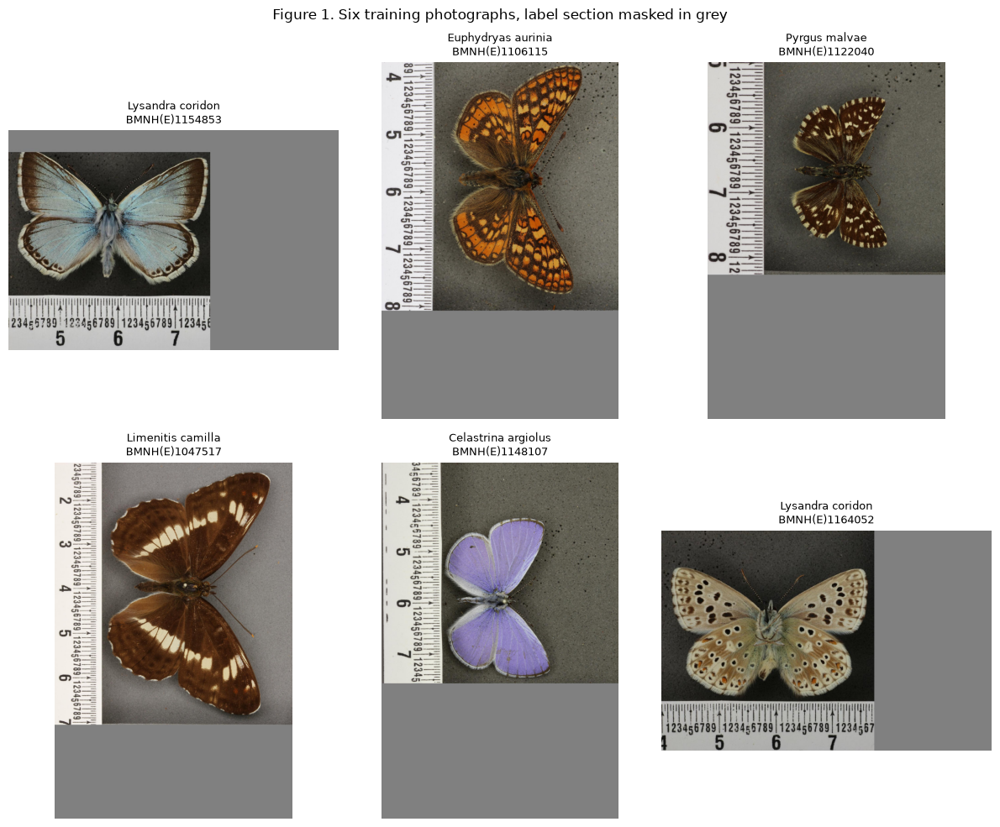

Natural History Museum. (n.d.). Lysandra coridon, BMNH(E)1154853 (from Collection specimens) [Photograph]. Natural History Museum. Licensed under CC-BY-4.0 (https://creativecommons.org/licenses/by/4.0). https://data.nhm.ac.uk/object/caa64824-9f1f-4278-836f-ad1fc943e857
Natural History Museum. (n.d.). Euphydryas aurinia, BMNH(E)1106115 (from Collection specimens) [Photograph]. Natural History Museum. Licensed under CC-BY-4.0 (https://creativecommons.org/licenses/by/4.0). https://data.nhm.ac.uk/object/20cef50d-fba5-466e-987f-002ce6b0b81c
Natural History Museum. (n.d.). Pyrgus malvae, BMNH(E)1122040 (from Collection specimens) [Photograph]. Natural History Museum. Licensed under CC-BY-4.0 (https://creativecommons.org/licenses/by/4.0). https://data.nhm.ac.uk/object/6e2e53fd-5bec-4bcb-a6c8-fea20957001c
Natural History Museum. (n.d.). Limenitis camilla, BMNH(E)1047517 (from Collection specimens) [Photograph]. Natural History Museum. Licensed under CC-BY-4.0 (https://creativecommons.org/licen

In [6]:
def save_figure(fig, number, name, folder="outputs/figures"):
    """Save fig as figure_NN_name.png in folder, made if missing, and return
    its path."""
    path = Path(folder) / f"figure_{number:02d}_{name}.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path


def attribution(row):
    """The Museum's attribution line for one manifest row, as a string.

    The title is the specimen's name and catalogue number, and the year is
    n.d., because the manifest keeps no update year."""
    name = " ".join(p for p in (row["genus"], row["species"]) if p)
    return (
        f"Natural History Museum. (n.d.). {name}, {row['catalog_number']} "
        "(from Collection specimens) [Photograph]. Natural History Museum. "
        "Licensed under CC-BY-4.0 "
        "(https://creativecommons.org/licenses/by/4.0). "
        f"https://data.nhm.ac.uk/object/{row['occurrence_id']}"
    )


# The ten photographs Figures 1 and 2 read ship in the repository with their
# label section painted grey already, so both figures redraw without the full
# set of photographs and no label is published.
PHOTOS = Path("data/figure_photos")
passed = rows[(rows["part"] == "training") & (rows["flagged"] == 0)]
shown = passed.sample(6, random_state=SEED_TRAIN)["row"].to_list()
fig, axes = plt.subplots(2, 3, figsize=(12, 10))
for ax, k in zip(axes.flat, shown):
    record = manifest.iloc[k]
    photo = bws.load_photograph(PHOTOS / record["file_name"])
    ax.imshow(photo)
    ax.set_title(
        f"{record['genus']} {record['species']}\n{record['catalog_number']}",
        fontsize=9,
    )
    ax.axis("off")
fig.suptitle(
    "Figure 1. Six training photographs, label section masked in grey"
)
plt.tight_layout()
save_figure(fig, 1, "training_photographs")
plt.show()
for k in shown:
    print(attribution(manifest.iloc[k]))

**What Figure 1 shows.** Each photograph holds one pinned butterfly on a grey tray, with a ruler along one edge and the label section painted grey. The lines below the figure credit the Museum for each photograph, in the form it asks for.

**The crop rule and the crop flag (Figure 2).** The rule finds the ruler and the labels, marks what differs from the tray's grey, and boxes the specimen with a small margin. Each crop is padded to a square with the tray's colour and resized to 64 by 64 with Pillow's bilinear filter. Figure 2 shows the box in red on four more training photographs, their 64 by 64 crops, and 16 crops the flag marked. The four photographs' attribution lines follow it, in the Museum's form.

Before training, 600 crops were scored by eye on contact sheets (grids of crops with their boxes drawn), with an AI assistant doing the scoring. I reviewed the results. A failure is a crop where a wing, the body or a label crosses the box edge. The verdicts ship in `data/crop_audit_600.csv`, one row per crop: its image, its audit sample, its verdict (pass, doubtful or fail), the kind of failure and who scored it. A doubtful crop is a borderline one, and the 63 doubtful crops count with the passes, so they are not in the failure rate. The 600 were drawn from the whole set, so they include both training and held-out photographs, and the cell prints how many of each. The audit is a different selection from the held-out split. The rule's own signals then give the crop flag, an automatic check set once on the 200 development images. It flags a crop when no specimen was found, or when the specimen is under 5 or over 60 per cent of the tray. It also flags a crop with marks across more than a third of a side of the box, or with white paper along more than 5 per cent of a side. The cell counts the failures and the flag's agreement with them from the audit file, below the figure, with the totals the flag marks in the fixed set.

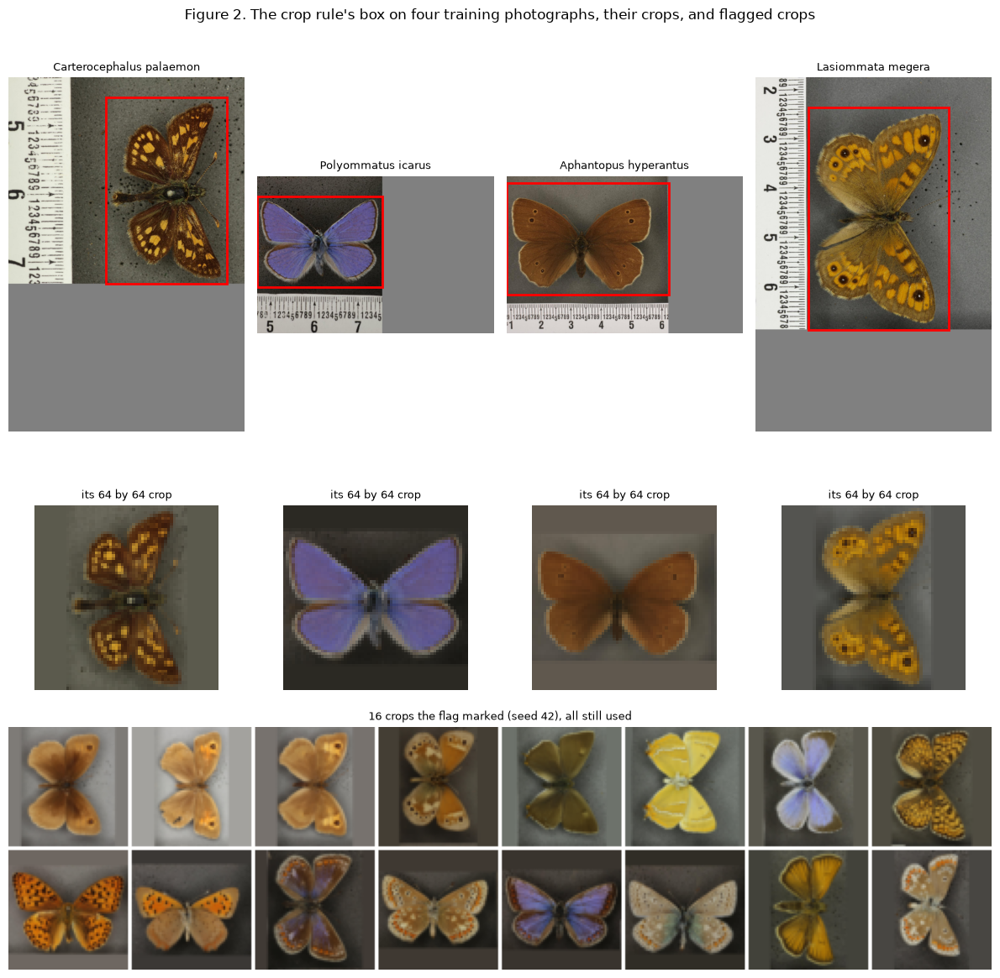

Natural History Museum. (n.d.). Carterocephalus palaemon, BMNH(E)502316 (from Collection specimens) [Photograph]. Natural History Museum. Licensed under CC-BY-4.0 (https://creativecommons.org/licenses/by/4.0). https://data.nhm.ac.uk/object/cca4346f-1534-4db8-8ea7-5a673b9e4e98
Natural History Museum. (n.d.). Polyommatus icarus, BMNH(E)1300427 (from Collection specimens) [Photograph]. Natural History Museum. Licensed under CC-BY-4.0 (https://creativecommons.org/licenses/by/4.0). https://data.nhm.ac.uk/object/8adac3fb-808f-4ce3-801c-f855a8cb5acc
Natural History Museum. (n.d.). Aphantopus hyperantus, BMNH(E)1045605 (from Collection specimens) [Photograph]. Natural History Museum. Licensed under CC-BY-4.0 (https://creativecommons.org/licenses/by/4.0). https://data.nhm.ac.uk/object/d6e83fa9-0115-4aa2-a855-6973185aa3f6
Natural History Museum. (n.d.). Lasiommata megera, BMNH(E)1068134 (from Collection specimens) [Photograph]. Natural History Museum. Licensed under CC-BY-4.0 (https://creativeco

In [7]:
def tile(images, cols, pad=2, fill=255):
    """The images laid out in rows of cols, with pad pixels of fill between
    them, as a new uint8 array."""
    n, h, w, c = images.shape
    rows_needed = math.ceil(n / cols)
    out = np.full(
        (
            rows_needed * h + (rows_needed - 1) * pad,
            cols * w + (cols - 1) * pad,
            c,
        ),
        fill,
        dtype=np.uint8,
    )
    for k in range(n):
        r, q = divmod(k, cols)
        y, x = r * (h + pad), q * (w + pad)
        bottom, right = y + h, x + w
        out[y:bottom, x:right] = images[k]
    return out


def audit_counts(audit, rows):
    """The crop flag against the audit's verdicts, one row per audit
    partition in the order met, as a new frame: images, failures, caught,
    false alarms, missed and cleared.

    audit has one row per scored crop, with its image_id, audit_partition
    and verdict. A failure is a "fail" verdict, and a doubtful crop counts
    with the passes. rows is the split's row table, which gives each image's
    flag. An audited image the table does not hold raises ValueError."""
    flags = dict(zip(rows["file_name"], rows["flagged"]))
    unknown = set(audit["image_id"]) - set(flags)
    if unknown:
        raise ValueError(f"{len(unknown)} audited images are not in the table")
    failed = (audit["verdict"] == "fail").to_numpy()
    flagged = audit["image_id"].map(flags).astype(bool).to_numpy()
    table = pd.DataFrame(
        {
            "partition": audit["audit_partition"].to_numpy(),
            "images": 1,
            "failures": failed.astype(int),
            "caught": (failed & flagged).astype(int),
            "false alarms": (~failed & flagged).astype(int),
            "missed": (failed & ~flagged).astype(int),
            "cleared": (~failed & ~flagged).astype(int),
        }
    )
    return table.groupby("partition", sort=False).sum()


others = passed[~passed["row"].isin(shown)]
crop_rows = others.sample(4, random_state=SEED_TRAIN)
# The box the crop rule found on each original photograph, kept when its labels
# were masked, because the rule reads a masked photograph differently.
masks = pd.read_csv(PHOTOS / "masks.csv", keep_default_na=False)
boxes = {
    m["file_name"]: (m["left"], m["top"], m["right"], m["bottom"])
    for m in masks.to_dict("records")
}
flag_draw = np.random.default_rng(SEED_TRAIN).choice(
    len(arrays["flagged"]), 16, replace=False
)
fig = plt.figure(figsize=(12, 12))
grid = fig.add_gridspec(3, 4, height_ratios=[3.2, 1.3, 1.9])
for col, (_, r) in enumerate(crop_rows.iterrows()):
    record = manifest.iloc[r["row"]]
    photo = bws.load_photograph(PHOTOS / record["file_name"])
    left, top, right, bottom = boxes[record["file_name"]]
    ax = fig.add_subplot(grid[0, col])
    ax.imshow(photo)
    ax.add_patch(
        plt.Rectangle(
            (left, top),
            right - left,
            bottom - top,
            fill=False,
            edgecolor="red",
            linewidth=2,
        )
    )
    ax.set_title(f"{record['genus']} {record['species']}", fontsize=9)
    ax.axis("off")
    ax = fig.add_subplot(grid[1, col])
    ax.imshow(arrays["training"][int(r["array_row"])])
    ax.set_title("its 64 by 64 crop", fontsize=9)
    ax.axis("off")
ax = fig.add_subplot(grid[2, :])
ax.imshow(tile(arrays["flagged"][np.sort(flag_draw)], cols=8))
ax.set_title("16 crops the flag marked (seed 42), all still used", fontsize=9)
ax.axis("off")
fig.suptitle(
    "Figure 2. The crop rule's box on four training photographs, "
    "their crops, and flagged crops"
)
plt.tight_layout()
save_figure(fig, 2, "crop_rule")
plt.show()
for _, r in crop_rows.iterrows():
    print(attribution(manifest.iloc[r["row"]]))

# The verdicts from the contact sheets, one row per scored crop, made before
# any training: an AI assistant scored them, and I reviewed the results.
audit = pd.read_csv("data/crop_audit_600.csv", keep_default_na=False)
for sample, n in audit_counts(audit, rows).iterrows():
    print(
        f"{sample.capitalize()} sample: {n['failures']} failures by eye of "
        f"{n['images']} ({100 * n['failures'] / n['images']:.1f} per cent). "
        f"Flag: {n['caught']} caught, {n['false alarms']} false alarms, "
        f"{n['missed']} missed, {n['cleared']} cleared; precision "
        f"{n['caught'] / (n['caught'] + n['false alarms']):.3f}, recall "
        f"{n['caught'] / (n['caught'] + n['missed']):.3f}"
    )
doubtful = int((audit["verdict"] == "doubtful").sum())
print(
    f"Doubtful by eye: {doubtful} of {len(audit)}, counted with the passes, "
    "so not in the failure rate"
)
kinds = audit.loc[audit["verdict"] == "fail", "failure_type"].value_counts()
print(
    f"Of the {kinds.sum()} failures, {kinds['label or card kept']} kept part "
    f"of a label or card and {kinds['specimen cut']} cut the specimen"
)
sides = audit["image_id"].map(dict(zip(rows["file_name"], rows["part"])))
print(
    f"The {len(audit)} audited crops were drawn from the whole set, a "
    "different selection from the held-out split: "
    f"{(sides == 'training').sum()} are training crops and "
    f"{(sides == 'held_out').sum()} held-out ones"
)
# The crop rule was set on the development sample, so I count the held-out
# photographs among them.
development = audit["audit_partition"] == "development"
print(
    f"Of the {development.sum()} development images the crop rule was set "
    f"on, {(sides[development] == 'held_out').sum()} are held-out photographs"
)
print(
    f"Flagged in the fixed set: {rows['flagged'].sum():,} of {len(rows):,} "
    f"({100 * rows['flagged'].mean():.1f} per cent), by reason:"
)
print(rows["flag_reasons"][rows["flagged"] == 1].value_counts().to_string())

**What the crop check shows.** By eye, the rule fails on about 6 per cent of crops, 34 of the 600 scored on the contact sheets. The flag catches most failures on the development images it was set on, but on the 400 provisional images it misses most of them and many of the crops it marks would pass by eye. Filtering by it would leave out about one photograph in five, most of them good, and still keep 15 of the 24 failures on the 400 it was not set on. So I use all crops, and I report the flag as a finding about the data preparation. Of the 34 failures, 21 kept part of a label or card and 13 cut the specimen, and Task 4 watches the samples for those artefacts. Most marked crops have marks across an edge of the box: a wing that runs to the edge, the platform's edge, or the top of a label.

**The working arrays (Figure 3).** The split stores the 64 by 64 red, green and blue (RGB) crops as uint8 arrays in manifest order. The training and held-out crops the flag passed each have their own array, and the crops it marked from both parts share a third. Task 3 rejoins them, so training uses every training crop and the evaluation every held-out crop. The cell prints the two parts' arrays' shape, type, size and pixel range, and Figure 3 shows 64 of the training crops the flag passed, drawn with seed 42.

training: shape (16000, 64, 64, 3), dtype uint8, 187.5 MiB, pixel values 0 to 255
held_out: shape (1767, 64, 64, 3), dtype uint8, 20.7 MiB, pixel values 0 to 251


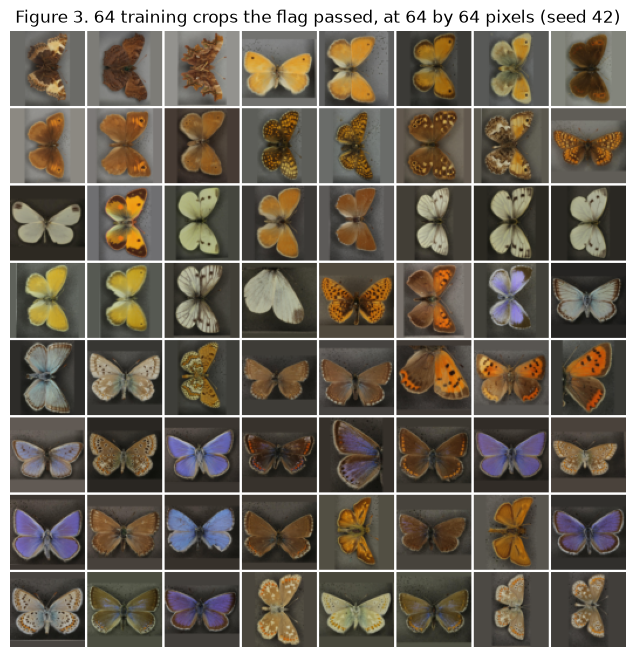

In [8]:
for part in ("training", "held_out"):
    a = arrays[part]
    print(
        f"{part}: shape {a.shape}, dtype {a.dtype}, "
        f"{a.nbytes / 2**20:.1f} MiB, pixel values {a.min()} to {a.max()}"
    )
train64 = np.sort(
    np.random.default_rng(SEED_TRAIN).choice(
        len(arrays["training"]), 64, replace=False
    )
)
plt.figure(figsize=(8, 8))
plt.imshow(tile(arrays["training"][train64], cols=8))
plt.title(
    "Figure 3. 64 training crops the flag passed, at 64 by 64 pixels (seed 42)"
)
plt.axis("off")
save_figure(plt.gcf(), 3, "training_crops")
plt.show()

**What the arrays show.** The training array holds the 16,000 crops the flag passed and the held-out array 1,767, each a 64 by 64 colour image stored as uint8. In Figure 3 each crop shows one butterfly on its tray, with the ruler and the labels cut away.

**The held-out split.** A seeded 10 per cent of the specimens is held out: the first tenth of NumPy's `default_rng(2026)` permutation over the manifest's rows, which the manifest keeps sorted by file name. With one photograph per specimen, a split by photograph is a split by specimen. The cell prints each part's size with and without the flagged crops, then the families on each side and how often the flag marks each family and each rendition.

In [9]:
print(
    f"Seed {bws.SEED}: {bws.HELD_OUT_FRACTION * 100:.0f} per cent held out, "
    f"{bws.held_out_count(len(rows)):,} of {len(rows):,} specimens"
)
for part, label in (("training", "Training"), ("held_out", "Held out")):
    p = rows[rows["part"] == part]
    flagged = int(p["flagged"].sum())
    print(
        f"{label}: {len(p):,} photographs with the flagged crops, "
        f"{len(p) - flagged:,} without them ({flagged:,} flagged)"
    )
with_family = rows.assign(family=manifest["family"].to_numpy())
kept = with_family[with_family["flagged"] == 0]
families = (
    pd.DataFrame(
        {
            "training": with_family.loc[
                with_family["part"] == "training", "family"
            ].value_counts(),
            "training kept": kept.loc[
                kept["part"] == "training", "family"
            ].value_counts(),
            "held out": with_family.loc[
                with_family["part"] == "held_out", "family"
            ].value_counts(),
            "held out kept": kept.loc[
                kept["part"] == "held_out", "family"
            ].value_counts(),
        }
    )
    .fillna(0)
    .astype(int)
    .sort_values("training", ascending=False)
)
families["training per cent"] = (
    100 * families["training"] / families["training"].sum()
).round(1)
families["kept per cent"] = (
    100 * families["training kept"] / families["training kept"].sum()
).round(1)
families["flagged per cent"] = (
    100 * with_family.groupby("family")["flagged"].mean()
).round(1)
display(families)
by_rendition = (
    100 * rows.groupby(manifest["rendition"].to_numpy())["flagged"].mean()
).round(1)
print("Flagged per cent by rendition:")
print(by_rendition.to_string())

Seed 2026: 10 per cent held out, 2,200 of 22,000 specimens
Training: 19,800 photographs with the flagged crops, 16,000 without them (3,800 flagged)
Held out: 2,200 photographs with the flagged crops, 1,767 without them (433 flagged)


,training,training kept,held out,held out kept,training per cent,kept per cent,flagged per cent
family,,,,,,,
Lycaenidae,8453,6704,944,737,42.7,41.9,20.8
Nymphalidae,7672,6160,848,675,38.7,38.5,19.8
Pieridae,2459,2083,254,215,12.4,13.0,15.3
Hesperiidae,941,856,115,107,4.8,5.4,8.8
Riodinidae,181,142,32,29,0.9,0.9,19.7
Papilionidae,94,55,7,4,0.5,0.3,41.6


Flagged per cent by rendition:
full/!512,512/0/default.jpg    19.4
original                       19.2


**Preprocessing considerations.**
- **The crop is fixed.** It is set once, before training, and used for every run. It is a function of the photograph alone, with no learned part. Goodfellow et al. (2016, sec. 20.14, p. 714) warn that "changes in preprocessing, even very small and subtle ones, are completely unacceptable" when generative models are compared.
- **Square, then resize.** Each crop is padded to a square with the tray's own colour, so the specimen keeps its shape, then resized to 64 by 64 with Pillow's bilinear filter and stored as uint8.
- **Scaling for the generator.** Task 3 scales the pixels to the range -1 to 1, for the generator's Tanh output, on the GPU one batch at a time. Radford et al. (2016, sec. 4, p. 3) did the same: "No pre-processing was applied to training images besides scaling to the range of the tanh activation function [-1, 1]." Training adds one step of its own, a random horizontal flip of each image. The flip is a step from my coursework, kept as my own choice. Somepalli et al. (2023, sec. 5, p. 6052) also "train all models with random horizontal flip and random crop augmentations", in a study of diffusion models.
- **Two resolutions.** 165 photographs are the Museum's 512-pixel rendition. Every crop is shrunk far below that size, and the flag marks the renditions at about the same rate as the originals.
- **Flagged crops.** All crops are used. The flagged ones sit in their own array, and Task 3 rejoins them, so training uses all 19,800 training crops and the evaluation all 2,200 held-out crops. The flag is a finding, not a filter. It marks some families more often than others, the swallowtails most, at 41.6 per cent, and the skippers least, at 8.8 per cent, so filtering by it would have shifted the family shares.
- **The held-out images.** They never train the model or choose a model setting: the architecture, the training settings or the checkpoint rule. The crop is a data-preparation step, applied to every photograph alike. It was set on the 200 development images, drawn from the whole set, and 21 of them are held out. Task 2 checks the held-out file's hash and prints its shape and pixel range, and Task 4 uses the held-out images in the evaluation.

**The anomaly list.** Before any model sees the data, I list each kind of anomaly set out before the data was read, and three more that the data showed. Every row of the fixed set is kept and only marked. The table counts each kind in the fixed set, in each part, and among the rows the crop flag kept. Records left out when the candidates were listed are counted from the download script's own list of them, `data/candidates_skipped.csv`, which ships here. The treatments follow the three options Van den Broeck et al. (2005, p. 968) give for a problem value: "The options are limited to correcting, deleting, or leaving unchanged."

In [10]:
def anomaly_flags(manifest, rows):
    """A True or False column per kind of anomaly, one row per manifest row,
    as a new frame. Every row is kept and only marked.

    rows is the split's row table, which must be in the manifest's order."""
    if list(rows["file_name"]) != list(manifest["file_name"]):
        raise ValueError("the row table is not in the manifest's order")
    species = manifest["species"]
    return pd.DataFrame(
        {
            "file_name": manifest["file_name"].to_numpy(),
            "part": rows["part"].to_numpy(),
            "crop flagged": rows["flagged"].astype(bool).to_numpy(),
            "duplicate file": manifest["sha256"]
            .duplicated(keep=False)
            .to_numpy(),
            "duplicate occurrence": manifest["occurrence_id"]
            .duplicated(keep=False)
            .to_numpy(),
            "no country": (manifest["country"] == "").to_numpy(),
            "outside the UK": (
                ~manifest["country"].isin(["", "United Kingdom"])
            ).to_numpy(),
            "aberrant form named": species.str.contains(
                r"\bab\.|aberr", regex=True
            ).to_numpy(),
            "hybrid name": species.str.contains(" x ", regex=False).to_numpy(),
            "no species": (species == "").to_numpy(),
            "512-pixel rendition": (
                manifest["rendition"] != "original"
            ).to_numpy(),
        }
    )


def anomaly_counts(flags):
    """How many rows each kind of anomaly marks, as a new frame: in the
    fixed set, in each part, and among the rows the crop flag kept."""
    kept = ~flags["crop flagged"]
    out = []
    for kind in [c for c in flags.columns if c not in ("file_name", "part")]:
        marked = flags[kind]
        out.append(
            {
                "anomaly": kind,
                "fixed set": int(marked.sum()),
                "training": int(
                    (marked & (flags["part"] == "training")).sum()
                ),
                "held out": int(
                    (marked & (flags["part"] == "held_out")).sum()
                ),
                "not crop flagged": int((marked & kept).sum()),
            }
        )
    return pd.DataFrame(out)


TREATMENT = {
    "crop flagged": "kept and used; reported as a finding",
    "duplicate file": "none found",
    "duplicate occurrence": "none found",
    "no country": "kept and marked; the model never reads country",
    "outside the UK": "kept and marked; never called UK only",
    "aberrant form named": "no kept field names one; none marked",
    "hybrid name": "kept and marked; the model reads no names",
    "no species": "kept and marked; the model reads no names",
    "512-pixel rendition": "kept and marked; cropped in proportions",
}
skipped_path = Path("data/candidates_skipped.csv")
if skipped_path.exists():
    skipped = len(pd.read_csv(skipped_path))
    print(
        f"more than one specimen photograph: {skipped:,} records, left out "
        "when the candidates were listed, so none is in the fixed set"
    )
else:
    print(
        "more than one specimen photograph: the download's list of skipped "
        "records is not on disk"
    )
anomaly_marks = anomaly_flags(manifest, rows)
anomalies = anomaly_counts(anomaly_marks)
anomalies["treatment"] = anomalies["anomaly"].map(TREATMENT)
with pd.option_context("display.max_colwidth", 60, "display.width", 160):
    display(anomalies)

more than one specimen photograph: 2,635 records, left out when the candidates were listed, so none is in the fixed set


,anomaly,fixed set,training,held out,not crop flagged,treatment
0,crop flagged,4233,3800,433,0,kept and used; reported as a finding
1,duplicate file,0,0,0,0,none found
2,duplicate occurrence,0,0,0,0,none found
3,no country,2064,1864,200,1714,kept and marked; the model never reads country
4,outside the UK,992,891,101,776,kept and marked; never called UK only
5,aberrant form named,0,0,0,0,no kept field names one; none marked
6,hybrid name,196,176,20,167,kept and marked; the model reads no names
7,no species,15,14,1,13,kept and marked; the model reads no names
8,512-pixel rendition,165,154,11,133,kept and marked; cropped in proportions


**The treatments.** Nothing was corrected and no row was deleted. Every row of the fixed set stays in the row table, and every crop is used in training or in the evaluation. The crop-flagged ones are only stored in their own array. No file and no specimen appears twice. Records with a second specimen photograph never entered the fixed set, because the selection took only records with a single specimen photograph. No kept field marks an aberrant form, though collectors sought them (Paterson et al., 2016, p. 12), so some may be in the photographs unmarked. Three kinds fall outside the categories set before the data was read: the hybrid name *Aricia agestis x artaxerxes*, records with a genus but no species, and the 512-pixel renditions. I keep all three. An unconditional model takes no names as input, but the photographs behind those names still train it, as every photograph does, and the crop works in proportions.

## Task 3: Implement and Train a Generative Model

**Design choices.** The model is an unconditional deep convolutional GAN (DCGAN) at 64 by 64 pixels, the pair of networks from my coursework DCGAN on the CelebA faces. Goodfellow et al. (2014, abstract, p. 1) train two models at once. One is "a generative model G that captures the data distribution", and the other "a discriminative model D that estimates the probability that a sample came from the training data rather than G." Each choice below names its source and the output that shows how it played out.

- **Why a GAN.** The brief pairs a GAN with image generation. Goodfellow et al. (2016, sec. 20.10.3, p. 694) note that "samples from variational autoencoders trained on images tend to be somewhat blurry", and blur would hide the failure cases Task 4 has to name. The only peer-reviewed GAN study on museum specimen photographs I found, I could read only as a preprint, so the choice rests on the architecture papers.
- **Generator.** A noise vector of 100 numbers passes through five transposed convolutions, from 1 by 1 to 64 by 64 pixels, with 64 base channels. The first four are each followed by batch normalisation (BatchNorm) and a rectified linear unit (ReLU), and the last by Tanh. Radford et al. (2016, sec. 3, p. 3): "Use ReLU activation in generator for all layers except for the output, which uses Tanh." The network and its parameter count are printed below.
- **Discriminator.** Four strided convolutions and a final 4 by 4 convolution take the image from 64 by 64 pixels to one value. They use leaky ReLU (LeakyReLU) at slope 0.2, BatchNorm on the three middle layers, and a Sigmoid output. That output is a score from 0 to 1, which I call the discriminator's score. With the smoothed targets below, it is not a calibrated probability that an image is real. Radford et al. (2016, sec. 3, p. 3): "Replace any pooling layers with strided convolutions (discriminator) and fractional-strided convolutions (generator)." In sec. 4, p. 3: "In the LeakyReLU, the slope of the leak was set to 0.2 in all models."
- **Initialisation.** Convolution weights come from a normal distribution with mean 0 and standard deviation 0.02, BatchNorm weights from mean 1 and 0.02, and biases are 0. Radford et al. (2016, sec. 4, p. 3): "All weights were initialized from a zero-centered Normal distribution with standard deviation 0.02." Figure 4 shows what these weights make before training.
- **Loss.** Binary cross-entropy (BCE) on the Sigmoid outputs. The discriminator's loss is the sum of its real and generated terms, with real targets of 0.9 and generated targets of 0. Salimans et al. (2016, sec. 3.4, p. 4) "smooth only the positive labels to" a value below 1. The generator's target is 1, the non-saturating objective of Goodfellow et al. (2014, sec. 3, p. 3), which "provides much stronger gradients early in learning". The loss check below and Figure 5 show the losses against the constant-0.5 reference, the loss of a discriminator that gives every image 0.5.
- **Optimiser.** Adam for each network at a learning rate of 0.0002, with betas (0.5, 0.999). Radford et al. (2016, sec. 4, pp. 3 to 4): "We found the suggested learning rate of 0.001, to be too high, using 0.0002 instead." and "reducing it to 0.5 helped stabilize training."
- **Batch and epochs.** Batches of 128 images, full batches only. Radford et al. (2016, sec. 4, p. 3): "All models were trained with mini-batch stochastic gradient descent (SGD) with a mini-batch size of 128." The 100 epochs are my assumption, not a source's. The checkpoints and the rule written below guard them.
- **Precision.** 32-bit floating point throughout, with TensorFloat-32 off and deterministic GPU kernels, so a rerun repeats its numbers. In my timing runs on this rig, bfloat16 was no faster, and my coursework notebook notes that "BCE + Sigmoid is sensitive to low-precision arithmetic".
- **EMA.** An exponential moving average (EMA) of the generator's weights, with decay 0.999, is updated after each generator step, with BatchNorm's running statistics copied across. It renders every sample, as my coursework DCGAN's did. No source I hold covers it, so it rests on the coursework alone and is my choice. It starts as a copy of the untrained generator, with no warm-up, so early in training it still carries much of its random start (end of Task 3). Figure 7 shows it at every checkpoint.
- **Data size.** Every one of the 19,800 training crops. Feng et al. (2021, Fig. 2 caption, p. 6704): "This results show that when the dataset size is small, GANs can generate almost exact replication of training data." Karras et al. (2020, p. 12104): "Training generative adversarial networks (GAN) using too little data typically leads to discriminator overfitting, causing training to diverge." The generator's 3.6 million parameters still far outnumber the training images, so Task 4's memorisation check is the evidence on copying.

**Where I leave my coursework DCGAN,** one line each, saying whether the difference is from its code or its saved run:
- Run 1 trains both networks at 0.0002, as the saved run did. The code now sets the discriminator to 0.00005, but no saved output shows that version, so run 1 adds only what the logged losses call for.
- Generated targets are 0, where both the code and the saved run used 0.1. Salimans et al. (2016, sec. 3.4, p. 3) explain why a non-zero target for generated samples harms the optimal discriminator: "The presence of p_model in the numerator is problematic".
- The final model is the last epoch unless a written flag fires, where the code picked the epoch whose discriminator loss sat nearest 1.386. An untrained discriminator also sits near that line, and the saved run's pick was epoch 1.
- The generator's target is 1, where the code uses 0.9.
- No torchvision, where the code used it: Pillow and plain PyTorch crop, resize, flip and scale.
- The training set sits on the GPU as one uint8 tensor, where the code decoded the images every epoch. By my timing, decoding would make a run about 15 times slower.

**The training images.** Training uses every training crop, 19,800 in all: the 16,000 the crop flag kept and the 3,800 it marked, rejoined in the manifest's order. On the 400 crops scored by eye in Task 2, 62 of the 71 crops the flag marked had not failed, and it missed 15 of the 24 that had. Filtering by it would cost far more good crops than failed ones. About 6 per cent of crops fail by eye, mostly at a label edge or a clipped wing, so Task 4 watches the samples for those artefacts. The images go to the GPU once, as one uint8 tensor.

In [11]:
def part_images(arrays, rows, part):
    """Every crop in part, flagged or not, in the manifest's order, as a new
    uint8 array.

    rows is the split's row table. A crop the flag kept comes from the
    part's own array and a flagged one from the flagged array, each at the
    row the table gives it. A table out of step with the arrays raises
    ValueError."""
    p = rows[rows["part"] == part]
    kept = (p["flagged"] == 0).to_numpy()
    if kept.sum() != len(arrays[part]):
        raise ValueError(f"the row table and the {part} array disagree")
    out = np.empty((len(p), *arrays[part].shape[1:]), dtype=np.uint8)
    out[kept] = arrays[part][p.loc[kept, "array_row"].astype(int).to_numpy()]
    out[~kept] = arrays["flagged"][
        p.loc[~kept, "flagged_row"].astype(int).to_numpy()
    ]
    return out


training_images = part_images(arrays, rows, "training")
n_flagged = int(rows.loc[rows["part"] == "training", "flagged"].sum())
print(
    f"Training images: {len(training_images):,}, the "
    f"{len(arrays['training']):,} crops the flag kept and the "
    f"{n_flagged:,} it marked, in the manifest's order"
)
# One uint8 tensor on the device for the whole run, channels first. Each
# batch is scaled to -1 to 1 only when it is drawn.
train_u8 = (
    torch.from_numpy(training_images)
    .permute(0, 3, 1, 2)
    .contiguous()
    .to(device)
)
print(
    f"On {device}: shape {tuple(train_u8.shape)}, {train_u8.dtype}, "
    f"{train_u8.numel() / 2**20:.1f} MiB"
)
# The 64 training images drawn with seed 42 that the loss check, F4 and
# Task 4's colour measure read.
reference_index = np.sort(
    np.random.default_rng(SEED_TRAIN).choice(
        len(training_images), 64, replace=False
    )
)

Training images: 19,800, the 16,000 crops the flag kept and the 3,800 it marked, in the manifest's order


On cuda: shape (19800, 3, 64, 64), torch.uint8, 232.0 MiB


**What the training set shows.** Training reads all 19,800 training crops, the 3,800 the flag marked among them. They sit on the GPU as one uint8 tensor of 232.0 MiB, loaded once for all the runs.

**The networks.** `Generator` and `Discriminator` follow the design above, and `make_models` builds a fresh pair from a seed with the initialisation above, leaving the global random state alone. The cell prints both networks layer by layer and counts their parameters. The counts are those of my coursework DCGAN.

In [12]:
import copy  # noqa: E402
import gc  # noqa: E402
import shutil  # noqa: E402

import torch.nn as nn  # noqa: E402
from torch.nn.utils.parametrizations import spectral_norm  # noqa: E402

NZ = 100  # the noise vector's length
NGF = 64  # the generator's base channel count
NDF = 64  # the discriminator's base channel count


class Generator(nn.Module):
    """The DCGAN generator: a noise vector to a 64 by 64 colour image."""

    def __init__(self, nz=100, ngf=64, nc=3):
        """Five transposed convolutions from 1 by 1 to 64 by 64 pixels, the
        first four followed by BatchNorm and ReLU, and Tanh on the last."""
        super().__init__()
        self.main = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 8, 4, 1, 0, bias=False),  # 4 by 4
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),  # 8
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),  # 16
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),  # 32
            nn.BatchNorm2d(ngf),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(ngf, nc, 4, 2, 1, bias=False),  # 64
            nn.Tanh(),
        )

    def forward(self, z):
        """Images in -1 to 1, shaped (batch, 3, 64, 64), for noise shaped
        (batch, nz, 1, 1)."""
        return self.main(z)


class Discriminator(nn.Module):
    """The DCGAN discriminator: a 64 by 64 colour image to a score from 0
    to 1, higher for an image it takes as a real photograph."""

    def __init__(self, nc=3, ndf=64):
        """Four strided convolutions and a final 4 by 4 convolution from 64
        by 64 pixels to one value, with LeakyReLU at slope 0.2, BatchNorm on
        the three middle layers, and a Sigmoid on the output."""
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),  # 32 by 32
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),  # 16
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),  # 8
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 4, ndf * 8, 4, 2, 1, bias=False),  # 4
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False),  # 1 by 1
            nn.Sigmoid(),
        )

    def forward(self, x):
        """One score per image, shaped (batch,), for images in -1 to 1
        shaped (batch, 3, 64, 64)."""
        return self.main(x).view(-1)


def make_models(seed, spectral=False, nz=100, ngf=64, ndf=64):
    """A new generator and discriminator on the CPU, initialised from seed,
    as (generator, discriminator).

    Every convolution's weights are drawn from a normal distribution with
    mean 0 and standard deviation 0.02, and every BatchNorm weight from mean
    1 and 0.02, with its bias at 0. With spectral, every discriminator
    convolution is spectrally normalised. The global random state is left
    as it was."""
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        generator, discriminator = Generator(nz, ngf), Discriminator(ndf=ndf)
        for net in (generator, discriminator):
            for m in net.modules():
                if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                    nn.init.normal_(m.weight, 0.0, 0.02)
                elif isinstance(m, nn.BatchNorm2d):
                    nn.init.normal_(m.weight, 1.0, 0.02)
                    nn.init.zeros_(m.bias)
        if spectral:
            for k, m in enumerate(discriminator.main):
                if isinstance(m, nn.Conv2d):
                    discriminator.main[k] = spectral_norm(m)
    return generator, discriminator


def count_parameters(model):
    """The number of trainable weights in model."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


generator, discriminator = (
    net.to(device) for net in make_models(SEED_TRAIN, nz=NZ, ngf=NGF, ndf=NDF)
)
print(generator)
print(discriminator)
print(f"Generator: {count_parameters(generator):,} parameters")
print(f"Discriminator: {count_parameters(discriminator):,} parameters")

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding

**What the networks show.** The generator has 3,576,704 parameters and ends in Tanh, and the discriminator has 2,765,568 and ends in a Sigmoid. Both match the design above, layer by layer.

**Before training (Figure 4).** One fixed batch of 64 noise vectors, drawn once with seed 42, is rendered here by the untrained generator and at every checkpoint by the EMA generator (Figure 7). Rendering runs in evaluation mode, so BatchNorm uses its running statistics. This is the baseline the trained samples are read against. Before training the generator gives a near-flat grey, with pixel values from 125 to 130. With BatchNorm on its starting statistics and weights this small, every output sits near the middle of Tanh's range.

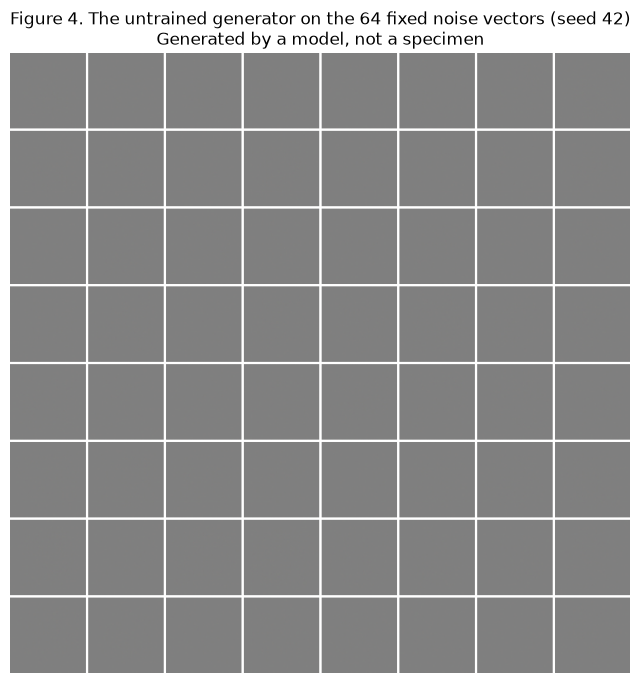

Pixel values 125 to 130, mean 127.5


In [13]:
def noise_batch(n, seed, nz=100):
    """n noise vectors of length nz from a standard normal distribution,
    drawn by a CPU generator seeded with seed, as a new tensor shaped
    (n, nz, 1, 1), so every device starts from the same batch."""
    rng = torch.Generator().manual_seed(seed)
    return torch.randn(n, nz, 1, 1, generator=rng)


def render(model, z, device, chunk=256):
    """The images model makes from the noise z, as a new uint8 array shaped
    (n, 64, 64, 3).

    The model runs in evaluation mode, so BatchNorm uses its running
    statistics, under no_grad and chunk vectors at a time, then goes back
    to the mode it came in. Pixels from -1 to 1 map to 0 to 255."""
    was_training = model.training
    model.eval()
    out = []
    with torch.no_grad():
        for start in range(0, len(z), chunk):
            stop = start + chunk
            x = model(z[start:stop].to(device))
            x = ((x + 1) * 127.5).round().clamp(0, 255).to(torch.uint8)
            out.append(x.permute(0, 2, 3, 1).cpu())
    model.train(was_training)
    return torch.cat(out).numpy()


fixed_z = noise_batch(64, SEED_TRAIN, NZ)
before = render(generator, fixed_z, device)
plt.figure(figsize=(8, 8.4))
plt.imshow(tile(before, cols=8))
plt.title(
    "Figure 4. The untrained generator on the 64 fixed noise vectors "
    f"(seed {SEED_TRAIN})\nGenerated by a model, not a specimen"
)
plt.axis("off")
save_figure(plt.gcf(), 4, "before_training")
plt.show()
print(
    f"Pixel values {before.min()} to {before.max()}, mean {before.mean():.1f}"
)

**What Figure 4 shows.** Before training, the generator turns every noise vector into a near-flat grey, with pixel values from 125 to 130. That grey is the baseline the trained samples are read against.

**The loss convention.** The discriminator's loss is the sum of its two BCE terms, not their mean. A discriminator that gives 0.5 to every image has a summed loss of 2 ln 2 = 1.386 against any targets, because the BCE of an output of 0.5 is ln 2 whatever the target. I draw that as the constant-0.5 reference on Figure 5. With real targets of 0.9 and generated targets of 0, a discriminator that cannot tell the two apart does best by giving every image a score of half the two targets' sum. The balance point is that score, 0.45, at which the summed loss is about 1.376. That loss is only 0.01 below the reference, so Figure 5 draws only the constant-0.5 reference. The check runs the untrained discriminator on 64 training images and the 64 images of Figure 4, first in evaluation mode, then in training mode, as at the first training step. In evaluation mode the untrained discriminator gives 0.500 on both batches and the sum is 1.386, on the reference. In training mode BatchNorm's batch statistics spread its scores, and the sum moves to 1.467.

In [14]:
def summed_bce(
    discriminator, real, fake, real_target, fake_target, training=False
):
    """The discriminator's loss on one real and one generated batch, as a
    new dict: each BCE term, their sum, and mean D(x) and mean D(G(z)).

    A copy scores both batches under no_grad, in evaluation mode, or in
    training mode as at the first training step when training is True, so
    the discriminator passed in is unchanged."""
    probe = copy.deepcopy(discriminator).train(training)
    bce = nn.BCELoss()
    with torch.no_grad():
        on_real, on_fake = probe(real), probe(fake)
        real_term = bce(on_real, torch.full_like(on_real, real_target))
        fake_term = bce(on_fake, torch.full_like(on_fake, fake_target))
    return {
        "mean D(x)": on_real.mean().item(),
        "mean D(G(z))": on_fake.mean().item(),
        "real term": real_term.item(),
        "generated term": fake_term.item(),
        "sum": real_term.item() + fake_term.item(),
    }


def balance_point(real_target, fake_target):
    """The constant score that gives the lowest summed loss when real and
    generated images cannot be told apart, with that loss, as (score, loss).

    The summed BCE of one constant score c against both targets is lowest
    where c is half the two targets' sum."""
    c = (real_target + fake_target) / 2
    targets = real_target + fake_target
    return c, -(targets * math.log(c) + (2 - targets) * math.log(1 - c))


def to_batch(images, device):
    """uint8 images shaped (n, 64, 64, 3) as a new float tensor on device,
    channels first and scaled to -1 to 1."""
    x = torch.from_numpy(images).permute(0, 3, 1, 2).to(device).float()
    return x / 127.5 - 1


real_64 = to_batch(training_images[reference_index], device)
fake_64 = to_batch(before, device)
print(
    "The untrained discriminator on the 64 training images (seed 42) and "
    "the 64 untrained samples of Figure 4, real targets 0.9 and generated "
    "targets 0:"
)
for mode, training in (("evaluation", False), ("training", True)):
    check = summed_bce(discriminator, real_64, fake_64, 0.9, 0.0, training)
    print(
        f"  in {mode} mode: mean D(x) {check['mean D(x)']:.4f}, mean D(G(z)) "
        f"{check['mean D(G(z))']:.4f}, real term {check['real term']:.4f}, "
        f"generated term {check['generated term']:.4f}, sum {check['sum']:.4f}"
    )
score, loss = balance_point(0.9, 0.0)
print(f"The constant-0.5 reference, 2 ln 2: {2 * math.log(2):.4f}")
print(
    "With these targets, a discriminator that cannot tell the two apart "
    f"does best at one constant score: balance point {score:.2f}, summed "
    f"loss {loss:.4f}"
)

The untrained discriminator on the 64 training images (seed 42) and the 64 untrained samples of Figure 4, real targets 0.9 and generated targets 0:


  in evaluation mode: mean D(x) 0.5004, mean D(G(z)) 0.5000, real term 0.6926, generated term 0.6931, sum 1.3857
  in training mode: mean D(x) 0.5466, mean D(G(z)) 0.4606, real term 0.7015, generated term 0.7651, sum 1.4666
The constant-0.5 reference, 2 ln 2: 1.3863
With these targets, a discriminator that cannot tell the two apart does best at one constant score: balance point 0.45, summed loss 1.3763


**What the loss check shows.** In evaluation mode the untrained discriminator scores both batches at about 0.5, so its summed loss, 1.3857, sits on the constant-0.5 reference. In training mode BatchNorm's batch statistics move the sum to 1.4666.

**Settings.** Every setting is fixed here, before any run, with its reason beside it. Runs 2 and 3 change only what the checkpoint rule below says.

In [15]:
hyper_rows = [
    ("batch", 128, "Radford et al. (2016, sec. 4); full batches only"),
    ("epochs", 100, "my assumption, guarded by the checkpoint rule"),
    ("lr_g", 0.0002, "Radford et al. (2016, sec. 4)"),
    ("lr_d", 0.0002, "the same rate for both networks in run 1"),
    ("betas", (0.5, 0.999), "Radford et al. (2016, sec. 4)"),
    ("real_target", 0.9, "one-sided smoothing (Salimans et al., 2016)"),
    ("fake_target", 0.0, "unsmoothed, so the smoothing is one-sided"),
    ("gen_target", 1.0, "the non-saturating loss (Goodfellow et al., 2014)"),
    ("ema_decay", 0.999, "the EMA generator of my coursework DCGAN"),
    ("seed", SEED_TRAIN, "weights, batch order, flips and noise"),
]
CHECKPOINTS = (0, 1, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100)
# Run 3's discriminator rate under TTUR, the rate my coursework code sets.
LR_D_TTUR = 0.00005
RUN1 = {name: value for name, value, _ in hyper_rows}
RUN1.update(
    run=1, nz=NZ, spectral=False, checkpoints=CHECKPOINTS, max_steps=None
)
print(
    pd.DataFrame(
        hyper_rows, columns=["setting", "value", "why"], dtype=object
    ).to_string(index=False)
)
steps = len(training_images) // RUN1["batch"]
print(
    f"\n{steps} full batches of {RUN1['batch']} an epoch, leaving "
    f"{len(training_images) - steps * RUN1['batch']} images out of each "
    f"epoch's shuffle, so {steps * RUN1['epochs']:,} generator updates in "
    f"{RUN1['epochs']} epochs"
)
print(f"Checkpoints at epochs {', '.join(map(str, CHECKPOINTS))}")

    setting        value                                               why
      batch          128  Radford et al. (2016, sec. 4); full batches only
     epochs          100     my assumption, guarded by the checkpoint rule
       lr_g       0.0002                     Radford et al. (2016, sec. 4)
       lr_d       0.0002          the same rate for both networks in run 1
      betas (0.5, 0.999)                     Radford et al. (2016, sec. 4)
real_target          0.9       one-sided smoothing (Salimans et al., 2016)
fake_target          0.0         unsmoothed, so the smoothing is one-sided
 gen_target          1.0 the non-saturating loss (Goodfellow et al., 2014)
  ema_decay        0.999          the EMA generator of my coursework DCGAN
       seed           42             weights, batch order, flips and noise

154 full batches of 128 an epoch, leaving 88 images out of each epoch's shuffle, so 15,400 generator updates in 100 epochs
Checkpoints at epochs 0, 1, 5, 10, 20, 30, 40, 50, 

**What the settings show.** Every setting is fixed before the first run, with its reason beside it. An epoch is 154 full batches, so 100 epochs make 15,400 generator updates, and the networks are saved at each checkpoint listed.

**The checkpoint rule, written before training.** A GAN has no validation loss, so a rule fixed now chooses the final model. Salimans et al. (2016, sec. 4, p. 4): "Generative adversarial networks lack an objective function, which makes it difficult to compare performance of different models." **The final model is the EMA generator at the last epoch, unless a failure flag fires.** The flags read training-side quantities only, never a held-out image.

| Flag | Name | Fires when |
|---|---|---|
| F1 | Discriminator domination | The epoch-mean discriminator loss is below 0.425, its floor plus 0.10, for 5 epochs in a row |
| F2 | Discriminator failure | The epoch-mean discriminator loss is above 1.5 for 5 epochs in a row, after epoch 5 |
| F3 | Unstable generator | From epoch 10 on, the standard deviation of the per-batch generator loss over the last 10 epochs is above 1.0 |
| F4 | Mode collapse | At a checkpoint from epoch 10 on, the mean pairwise Euclidean distance among the EMA generator's 64 fixed-noise images is below 0.5 times the same measure on the 64 training images drawn with seed 42. That ratio is the diversity ratio, 1.0 when the images are as varied as real ones |
| F5 | Non-finite loss | Any loss is not a finite number, which also stops the run |

- **Grounds.** With generated targets of 0, the summed loss cannot fall below the BCE of a real target of 0.9 against itself, 0.325, so F1's line follows the loss convention. F1, F2 and F3 take their thresholds from the checks in my coursework GAN exercise, which read the last third of training. Their epoch windows and F4's 0.5 are my assumptions. Karras et al. (2020, p. 12104) find that with too little data the discriminator overfits and training diverges. Radford et al. (2016, sec. 7, p. 9), on F3: "we noticed as models are trained longer they sometimes collapse a subset of filters to a single oscillating mode." Heusel et al. (2017, sec. 2, p. 4), on F4, describe collapse as when "only few prototype samples are generated".
- **Fallback.** If a flag fires, the final model is the EMA generator at the last checkpoint from epoch 5 on before that flag's window began. If there is none, the run has failed. If several flags fire, the earliest window decides. Every line is strict, so a value on it does not fire.
- **Runs 2 and 3.** F1, F3, F4 or F5 in run 1 call run 2, which adds spectral normalisation to every discriminator convolution. Miyato et al. (2018, abstract, p. 1): "we propose a novel weight normalization technique called spectral normalization to stabilize the training of the discriminator." The same flags in run 2 call run 3, which keeps it and lowers the discriminator's learning rate to 0.00005 against the generator's 0.0002, the two time-scale update rule (TTUR). Heusel et al. (2017, abstract, p. 1): "TTUR has an individual learning rate for both the discriminator and the generator." There is no fourth run, and the final model comes from the last run made.
- **F2 calls no run.** The discriminator is losing, and both fixes restrain it further, so the notebook reports the failure and keeps that run's fallback model.
- **Watchdog stops.** On this rig, a stop for memory, the 30-minute budget or a slow epoch is not a training failure. It stops the notebook, with no further run. On any other machine those only warn. A score, loss or gradient that is not finite is flag F5: the run stops at that batch, and its flags are read as usual.

In [16]:
def mean_pairwise_distance(images):
    """The mean Euclidean distance over every pair of images, each
    flattened, as a float. Fewer than two images raise ValueError."""
    if len(images) < 2:
        raise ValueError("a pairwise distance needs two images or more")
    x = np.asarray(images, dtype=np.float64).reshape(len(images), -1)
    squares = (x * x).sum(axis=1)
    d2 = squares[:, None] + squares[None, :] - 2 * (x @ x.T)
    upper = np.triu_indices(len(x), k=1)
    return float(np.sqrt(np.maximum(d2[upper], 0)).mean())


def run_of(held, length, start=1):
    """The first epoch that ends length epochs in a row on which held is
    True, counting from epoch start, with the epoch that run began, as
    (epoch, first epoch), or None. held[k] is for epoch k + 1."""
    count = 0
    for epoch, holds in enumerate(held, 1):
        count = count + 1 if (holds and epoch >= start) else 0
        if count == length:
            return epoch, epoch - length + 1
    return None


def read_flags(
    log,
    ratios,
    nonfinite_epoch,
    lines,
    length=5,
    after=5,
    window=10,
    first_checkpoint=10,
    first_epoch=1,
):
    """Each failure flag's first firing as (epoch, first epoch of its
    window), or None, in a new dict keyed F1 to F5.

    log is shaped (epochs, batches, 4): the summed discriminator loss, the
    generator loss, mean D(x) and mean D(G(z)) of every batch. ratios maps
    each checkpoint epoch to its fixed-noise diversity ratio. Every line is
    strict, so a value on a line does not fire. No window takes in an epoch
    before first_epoch, which is epoch 1 in the rule as written."""
    d_means = log[:, :, 0].mean(axis=1)
    g = log[:, :, 1]
    flags = {
        "F1": run_of(d_means < lines["F1"], length, start=first_epoch),
        "F2": run_of(
            d_means > lines["F2"], length, start=max(after + 1, first_epoch)
        ),
        "F3": None,
        "F4": None,
        "F5": None,
    }
    for epoch in range(window + first_epoch - 1, len(log) + 1):
        start = epoch - window
        if g[start:epoch].std() > lines["F3"]:
            flags["F3"] = (epoch, epoch - window + 1)
            break
    for epoch in sorted(ratios):
        late = epoch >= max(first_checkpoint, first_epoch)
        if late and ratios[epoch] < lines["F4"]:
            flags["F4"] = (epoch, epoch)
            break
    if nonfinite_epoch is not None:
        flags["F5"] = (nonfinite_epoch, nonfinite_epoch)
    return flags


# With generated targets of 0, the summed loss can fall no lower than the
# BCE of the real target against itself.
real_target = RUN1["real_target"]
D_FLOOR = -(
    real_target * math.log(real_target)
    + (1 - real_target) * math.log(1 - real_target)
)
LINES = {"F1": D_FLOOR + 0.10, "F2": 1.5, "F3": 1.0, "F4": 0.5}
FLAG_NAMES = {
    "F1": "Discriminator domination",
    "F2": "Discriminator failure",
    "F3": "Unstable generator",
    "F4": "Mode collapse",
    "F5": "Non-finite loss",
}
f4_reference = mean_pairwise_distance(training_images[reference_index])
print(
    f"The summed discriminator loss's floor: {D_FLOOR:.3f}, so F1's line is "
    f"{LINES['F1']:.3f}"
)
print(
    f"F2 above {LINES['F2']}, F3 above a standard deviation of "
    f"{LINES['F3']}, F4 below {LINES['F4']} of the reference"
)
print(
    "F4's reference, the mean pairwise distance among the 64 training "
    f"images (seed {SEED_TRAIN}): {f4_reference:,.1f} on the 0 to 255 "
    "pixel scale"
)

The summed discriminator loss's floor: 0.325, so F1's line is 0.425
F2 above 1.5, F3 above a standard deviation of 1.0, F4 below 0.5 of the reference
F4's reference, the mean pairwise distance among the 64 training images (seed 42): 5,022.0 on the 0 to 255 pixel scale


**What the flag lines show.** Each line is set in code before any training: 0.425 for F1, 1.5 for F2, 1.0 for F3 and half the reference for F4. F4's reference, the mean pairwise distance among 64 training images, is 5,022.0 on the 0 to 255 scale.

In [17]:
def choose_checkpoint(flags, saved, first=5):
    """The epoch of the checkpoint the written rule picks, or None when the
    run failed.

    With no flag fired it is the last checkpoint saved. Otherwise it is the
    last checkpoint from epoch first on that came before the earliest
    window of any flag that fired."""
    windows = [found[1] for found in flags.values() if found]
    if not windows:
        return max(saved)
    before = [epoch for epoch in saved if first <= epoch < min(windows)]
    return max(before) if before else None


def next_run(flags, run):
    """The run that run's flags call next, or None, with the reason, as
    (run, reason).

    F2 calls no run. F1, F3, F4 or F5 call run 2 after run 1 and run 3
    after run 2, and no run follows run 3."""
    fired = [key for key, found in flags.items() if found]
    if "F2" in fired:
        return None, (
            f"F2 fired in run {run}: the discriminator is losing, and both "
            "fixes would weaken it further, so no further run is made"
        )
    if not fired:
        return None, f"No flag fired in run {run}, so no further run is made"
    if run >= 3:
        return None, (
            f"{', '.join(fired)} fired in run 3, and there is no fourth run"
        )
    return run + 1, (
        f"{', '.join(fired)} fired in run {run}, so run {run + 1} is made"
    )


def run_settings(base, run, lr_d_ttur):
    """Run 1, 2 or 3's settings from run 1's base, as a new dict. Run 2
    adds spectral normalisation to the discriminator, and run 3 keeps it
    and lowers the discriminator's learning rate to lr_d_ttur (TTUR)."""
    settings = dict(base, run=run)
    if run >= 2:
        settings["spectral"] = True
    if run >= 3:
        settings["lr_d"] = lr_d_ttur
    return settings


def flag_table(flags, names):
    """One row per flag in key order, with its name, pass or fired, the
    epoch it fired and the epoch its window began, as a new frame."""
    return pd.DataFrame(
        [
            {
                "flag": key,
                "name": names[key],
                "result": "fired" if flags[key] else "pass",
                "fired at epoch": str(flags[key][0]) if flags[key] else "",
                "window from epoch": str(flags[key][1]) if flags[key] else "",
            }
            for key in sorted(flags)
        ]
    )


for later in (2, 3):
    changed = {
        key: value
        for key, value in run_settings(RUN1, later, LR_D_TTUR).items()
        if RUN1[key] != value and key != "run"
    }
    print(f"Run {later}, made only if a flag calls it, changes {changed}")

Run 2, made only if a flag calls it, changes {'spectral': True}
Run 3, made only if a flag calls it, changes {'lr_d': 5e-05, 'spectral': True}


**What the run plan shows.** Run 2 adds spectral normalisation and changes nothing else, and run 3 keeps it and lowers the discriminator's learning rate to 0.00005. Neither run is made unless a flag calls it.

**The training loop.** `train_run` trains one run from freshly seeded networks. Each step takes a discriminator step on a real and a generated batch, then a generator step, then updates the EMA generator, as my coursework loop did. Each real batch is scaled to -1 to 1, and each image is flipped left to right at random, seeded through the run's own random generator. Every batch logs the summed discriminator loss, the generator loss, and mean D(x) and mean D(G(z)) from before the discriminator step. D(x) is the discriminator's score for a real image, and D(G(z)) its score for a generated one. Goodfellow et al. (2014, abstract, p. 1) describe D as one that "estimates the probability that a sample came from the training data", but with smoothed targets I call its output a score. Before each loss and each optimiser step, the loop checks the scores and every gradient for a value that is not finite. If one appears, the run stops at that batch, with its epoch and batch recorded and the rest of that epoch's log left as not a number (NaN), which is flag F5. So a NaN never reaches PyTorch's BCE loss, which halts the process on the GPU, and no step trains on one. At each checkpoint all three networks are saved to `outputs/`, each under its own name, and after each epoch the setup cell's watchdog rules on stopping.

In [18]:
def bce_value(p, target):
    """The binary cross-entropy of the probabilities p against target, as
    nn.BCELoss computes it with each log floored at -100, as a new scalar
    tensor. Where nn.BCELoss refuses a NaN probability, and on the GPU halts
    the process, this gives a NaN loss."""
    log_p = torch.log(p).clamp(min=-100)
    log_q = torch.log(1 - p).clamp(min=-100)
    return -(target * log_p + (1 - target) * log_q).mean()


def finite(*tensors):
    """True when every value in tensors is a finite number, as a bool.

    Each value is tested on its own, so a large but finite tensor whose sum
    would overflow still reads as finite. The tests come back as one
    reading, and on the GPU that reading waits for the work before it."""
    checks = [torch.isfinite(t.detach()).all() for t in tensors]
    return bool(torch.stack(checks).all())


def train_run(
    images,
    settings,
    fixed_z,
    reference,
    device,
    on_rig,
    out_dir,
    watch,
    read_memory,
    say=print,
):
    """Train one run from freshly seeded networks and return it as a new
    dict.

    images is the training set as one uint8 tensor shaped (N, 3, 64, 64)
    on device, and is not changed. Each step scales a shuffled batch to -1
    to 1 and flips each image left to right at random, then takes a
    discriminator step, a generator step and an EMA update. Every batch
    logs the summed discriminator loss, the generator loss, mean D(x) and
    mean D(G(z)), the last two from before the discriminator step. At each
    checkpoint epoch the EMA generator renders fixed_z, its diversity ratio
    against reference is measured, and the three networks are saved to
    out_dir. After each epoch, watch rules on stopping from the summed
    losses, the epoch times, the seconds so far and read_memory's MiB. A
    score or gradient that is not finite stops the run at that batch,
    before any loss or step uses it: the rest of that epoch's log is NaN,
    and the stop names the epoch and the batch."""
    started = time.perf_counter()
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    g, d = (
        net.to(device)
        for net in make_models(
            settings["seed"], settings["spectral"], settings["nz"]
        )
    )
    g_ema = copy.deepcopy(g).requires_grad_(False)
    opt_g = torch.optim.Adam(
        g.parameters(), lr=settings["lr_g"], betas=settings["betas"]
    )
    opt_d = torch.optim.Adam(
        d.parameters(), lr=settings["lr_d"], betas=settings["betas"]
    )
    bce = nn.BCELoss()
    rng = torch.Generator(device=device).manual_seed(settings["seed"])
    n, batch, nz = len(images), settings["batch"], settings["nz"]
    steps = n // batch
    if settings["max_steps"] is not None:
        steps = min(steps, settings["max_steps"])
    target = {
        name: torch.full((batch,), float(settings[name]), device=device)
        for name in ("real_target", "fake_target", "gen_target")
    }
    decay = settings["ema_decay"]
    result = {
        "run": settings["run"],
        "settings": dict(settings),
        "log": [],
        "epoch_seconds": [],
        "checkpoints": {},
        "stop": None,
        "nonfinite_epoch": None,
        "warnings": [],
        "peak_used_mib": None,
        "peak_allocated_mib": None,
        "peak_reserved_mib": None,
    }

    def save_checkpoint(epoch):
        """Save the three networks for epoch, render fixed_z with the EMA
        and the live generator, and measure the EMA render's diversity."""
        files = {}
        for name, net in (
            ("generator", g),
            ("generator_ema", g_ema),
            ("discriminator", d),
        ):
            path = out_dir / f"epoch_{epoch:03d}_{name}.pt"
            torch.save(net.state_dict(), path)
            files[name] = str(path)
        images_now = render(g_ema, fixed_z, device)
        result["checkpoints"][epoch] = {
            "images": images_now,
            "live_images": render(g, fixed_z, device),
            "ratio": mean_pairwise_distance(images_now) / reference,
            "files": files,
        }

    def grads(net):
        """The gradients net holds, as a new list."""
        return [p.grad for p in net.parameters() if p.grad is not None]

    def train_step(real, z):
        """One discriminator step, one generator step and an EMA update on
        real and the noise z, as (the batch's four logged values, None), or
        as (None, what was not finite) when a check stops it first."""
        fake = g(z)
        opt_d.zero_grad(set_to_none=True)
        on_real = d(real)
        on_fake = d(fake.detach())
        if not finite(on_real, on_fake):
            return None, "the discriminator's scores"
        d_loss = bce(on_real, target["real_target"]) + bce(
            on_fake, target["fake_target"]
        )
        d_loss.backward()
        if not finite(*grads(d)):
            return None, "the discriminator's gradients"
        opt_d.step()

        opt_g.zero_grad(set_to_none=True)
        on_gen = d(fake)
        if not finite(on_gen):
            return None, "the discriminator's scores for the generator step"
        g_loss = bce(on_gen, target["gen_target"])
        g_loss.backward()
        if not finite(*grads(g)):
            return None, "the generator's gradients"
        opt_g.step()

        with torch.no_grad():
            for p_ema, p in zip(g_ema.parameters(), g.parameters()):
                p_ema.mul_(decay).add_(p, alpha=1 - decay)
            for b_ema, b in zip(g_ema.buffers(), g.buffers()):
                b_ema.copy_(b)
            d_logged = bce_value(on_real, target["real_target"])
            d_logged = d_logged + bce_value(on_fake, target["fake_target"])
            g_logged = bce_value(on_gen, target["gen_target"])
            return (
                torch.stack(
                    [d_logged, g_logged, on_real.mean(), on_fake.mean()]
                ),
                None,
            )

    save_checkpoint(0)
    log = torch.empty(steps, 4, device=device)
    for epoch in range(1, settings["epochs"] + 1):
        epoch_started = time.perf_counter()
        order = torch.randperm(n, generator=rng, device=device)
        problem = None
        for step in range(steps):
            first, last = step * batch, (step + 1) * batch
            real = images[order[first:last]].float()
            real = real / 127.5 - 1
            flip = torch.rand(batch, generator=rng, device=device) < 0.5
            real = torch.where(flip[:, None, None, None], real.flip(3), real)
            z = torch.randn(batch, nz, 1, 1, generator=rng, device=device)
            logged, problem = train_step(real, z)
            if problem:
                # The rest of the epoch's log is NaN, so the log shows where
                # the run stopped and F5 reads that epoch.
                log[step:] = float("nan")
                break
            log[step] = logged
        # Moving the log to the CPU waits for the GPU, so the epoch's time
        # covers its work.
        epoch_log = log.cpu().numpy().copy()
        result["epoch_seconds"].append(time.perf_counter() - epoch_started)
        result["log"].append(epoch_log)
        losses = epoch_log[:, :2]
        if not np.isfinite(losses).all() and result["nonfinite_epoch"] is None:
            result["nonfinite_epoch"] = epoch
        if problem:
            result["stop"] = (
                f"epoch {epoch}, batch {step + 1}: {problem} are not finite, "
                "so the run stops before any loss or step uses them"
            )
            say(f"Run {settings['run']} stopped: {result['stop']}")
            break
        used = read_memory()
        if used is not None:
            result["peak_used_mib"] = max(used, result["peak_used_mib"] or 0)
        elapsed = time.perf_counter() - started
        stop, warning = watch(
            float(losses.sum()), result["epoch_seconds"], elapsed, used, on_rig
        )
        if warning and warning not in result["warnings"]:
            result["warnings"].append(warning)
            say(f"Warning: {warning}")
        if stop:
            result["stop"] = stop
            say(f"Run {settings['run']} stopped at epoch {epoch}: {stop}")
            break
        if epoch in settings["checkpoints"]:
            save_checkpoint(epoch)
            m = epoch_log.mean(axis=0)
            memory = f", {used:,} MiB in use" if used is not None else ""
            say(
                f"Run {settings['run']} epoch {epoch:3d}: D loss {m[0]:.3f}, "
                f"G loss {m[1]:.3f}, D(x) {m[2]:.3f}, D(G(z)) {m[3]:.3f}, "
                f"{result['epoch_seconds'][-1]:.1f} s for the epoch, "
                f"{elapsed / 60:.1f} min so far{memory}"
            )
    result["log"] = (
        np.stack(result["log"]) if result["log"] else np.empty((0, steps, 4))
    )
    result["seconds"] = time.perf_counter() - started
    if device == "cuda":
        mib = 2**20
        result["peak_allocated_mib"] = torch.cuda.max_memory_allocated() / mib
        result["peak_reserved_mib"] = torch.cuda.max_memory_reserved() / mib
    return result

**Pre-flight.** Five training steps on seed 42 before the full run. Every loss must be finite and the generator's output on the fixed noise must change, or the cell stops the notebook. It proves the loop runs, and nothing it shows changes a setting.

In [19]:
preflight = train_run(
    train_u8,
    dict(RUN1, epochs=1, max_steps=5, checkpoints=(0, 1)),
    fixed_z,
    f4_reference,
    device,
    on_rig,
    Path("outputs/preflight"),
    watchdog,
    used_mib,
    say=lambda text: None,
)
pre_log = preflight["log"][0]
all_finite = bool(np.isfinite(pre_log).all())
moved = not np.array_equal(
    preflight["checkpoints"][0]["live_images"],
    preflight["checkpoints"][1]["live_images"],
)
print(
    f"Pre-flight, seed {SEED_TRAIN}, {len(pre_log)} steps. D loss by step: "
    f"{', '.join(f'{v:.3f}' for v in pre_log[:, 0])}. G loss by step: "
    f"{', '.join(f'{v:.3f}' for v in pre_log[:, 1])}"
)
print(
    f"Every loss finite: {all_finite}. The generator's output on the fixed "
    f"noise changed: {moved}"
)
if preflight["stop"] or not (all_finite and moved):
    raise RuntimeError(
        "the pre-flight failed, so no training run starts: "
        f"{preflight['stop'] or 'a loss is not finite or nothing moved'}"
    )
print(
    f"The {len(pre_log)} steps took {preflight['epoch_seconds'][0]:.1f} s, "
    "most of it the GPU's start-up, so run 1's first epoch below gives the "
    "real pace. The watchdog checks the "
    f"{BUDGET_SECONDS / 60:g}-minute budget after every epoch."
)

Pre-flight, seed 42, 5 steps. D loss by step: 1.287, 1.628, 0.772, 0.798, 1.109. G loss by step: 5.208, 6.602, 6.958, 5.495, 7.284
Every loss finite: True. The generator's output on the fixed noise changed: True
The 5 steps took 1.0 s, most of it the GPU's start-up, so run 1's first epoch below gives the real pace. The watchdog checks the 30-minute budget after every epoch.


**What the pre-flight shows.** All five steps gave finite losses and changed the generator's output on the fixed noise, so the training loop runs. The 1.0 seconds they took are mostly the GPU's start-up, so run 1 below gives the real pace.

**Run 1.** The settings above, with one-sided label smoothing as the only stabiliser, for 100 epochs. The run prints one line at each checkpoint, then its wall time and memory peaks.

In [20]:
def describe_run(run):
    """One paragraph on a finished run, as a new string: its epochs, wall
    time, memory peaks and any stop or warning."""
    parts = [
        f"Run {run['run']}: {len(run['log'])} epochs in "
        f"{run['seconds'] / 60:.1f} minutes"
    ]
    if run["peak_allocated_mib"] is not None:
        parts.append(
            f"PyTorch's peak {run['peak_allocated_mib']:,.0f} MiB allocated "
            f"and {run['peak_reserved_mib']:,.0f} MiB reserved"
        )
    if run["peak_used_mib"] is not None:
        parts.append(
            f"the watchdog's highest reading {run['peak_used_mib']:,} MiB in "
            "use on the GPU"
        )
    if run["stop"]:
        parts.append(f"stopped by the watchdog: {run['stop']}")
    for warning in run["warnings"]:
        parts.append(f"warning: {warning}")
    return ", ".join(parts) + "."


runs = {
    1: train_run(
        train_u8,
        RUN1,
        fixed_z,
        f4_reference,
        device,
        on_rig,
        Path("outputs/run1"),
        watchdog,
        used_mib,
    )
}
print(describe_run(runs[1]))
# A value that is not finite is flag F5 and is read with the other flags.
# Any other watchdog stop is not a training failure, and it stops the
# notebook here.
if runs[1]["stop"] and runs[1]["nonfinite_epoch"] is None:
    raise RuntimeError(
        f"the watchdog stopped run 1 ({runs[1]['stop']}), so no further run "
        "is made"
    )

Run 1 epoch   1: D loss 0.740, G loss 8.106, D(x) 0.797, D(G(z)) 0.117, 3.9 s for the epoch, 0.1 min so far, 6,714 MiB in use


Run 1 epoch   5: D loss 0.764, G loss 3.542, D(x) 0.738, D(G(z)) 0.162, 3.9 s for the epoch, 0.3 min so far, 6,714 MiB in use


Run 1 epoch  10: D loss 0.697, G loss 3.325, D(x) 0.752, D(G(z)) 0.147, 4.0 s for the epoch, 0.7 min so far, 6,714 MiB in use


Run 1 epoch  20: D loss 0.643, G loss 3.071, D(x) 0.760, D(G(z)) 0.139, 4.0 s for the epoch, 1.3 min so far, 6,714 MiB in use


Run 1 epoch  30: D loss 0.698, G loss 3.211, D(x) 0.758, D(G(z)) 0.141, 3.9 s for the epoch, 2.0 min so far, 6,714 MiB in use


...

Run 1 epoch  60: D loss 0.475, G loss 3.727, D(x) 0.834, D(G(z)) 0.066, 3.9 s for the epoch, 4.0 min so far, 6,714 MiB in use


Run 1 epoch  70: D loss 0.453, G loss 3.980, D(x) 0.846, D(G(z)) 0.054, 3.9 s for the epoch, 4.7 min so far, 6,714 MiB in use


Run 1 epoch  80: D loss 0.448, G loss 4.166, D(x) 0.852, D(G(z)) 0.049, 4.0 s for the epoch, 5.4 min so far, 6,714 MiB in use


Run 1 epoch  90: D loss 0.465, G loss 4.199, D(x) 0.849, D(G(z)) 0.052, 4.0 s for the epoch, 6.0 min so far, 6,715 MiB in use


Run 1 epoch 100: D loss 0.559, G loss 3.979, D(x) 0.827, D(G(z)) 0.073, 4.0 s for the epoch, 6.7 min so far, 6,715 MiB in use
Run 1: 100 epochs in 6.7 minutes, PyTorch's peak 951 MiB allocated and 1,108 MiB reserved, the watchdog's highest reading 6,715 MiB in use on the GPU.


**What run 1's log shows.** Run 1 finished all 100 epochs in 6.7 minutes, with PyTorch's peak at 951 MiB allocated. At every checkpoint the discriminator scored the real batches well above the generated ones, so it led throughout.

**Loss curves (Figure 5).** Every batch's discriminator and generator loss, raw and faint, with a moving average over a window of the batch count divided by 50. The dashed line on the discriminator's panel is the constant-0.5 reference, 2 ln 2 = 1.386, the summed loss of a discriminator that gives every image 0.5. With this project's targets, the summed loss at the balance point is 0.01 below it, at about 1.376. The table then sets the first third of the batches against the last third.

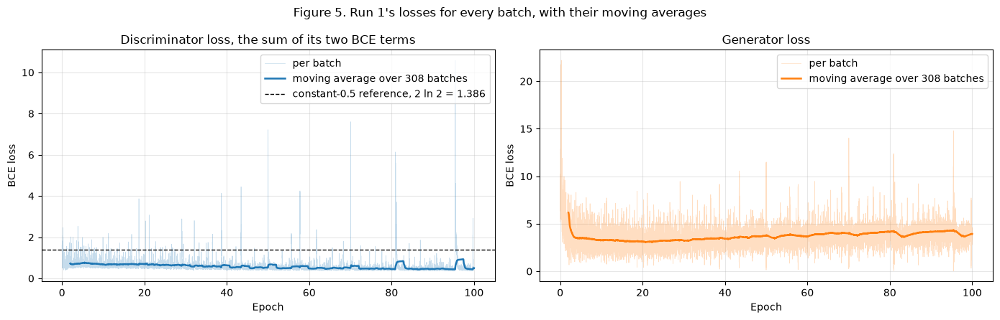

Run 1, the first third of its batches against the last third:
           measure  first third  last third
discriminator loss        0.676       0.527
    generator loss        3.443       4.018
         mean D(x)        0.760       0.833
      mean D(G(z))        0.140       0.067


In [21]:
def moving_average(values, window):
    """The trailing mean over each window values in a row, as a new array
    one value per full window. A window below 1 or longer than values
    raises ValueError."""
    v = np.asarray(values, dtype=float)
    if not 1 <= window <= len(v):
        raise ValueError(f"the window must be 1 to {len(v)}, not {window}")
    sums = np.cumsum(np.insert(v, 0, 0.0))
    return (sums[window:] - sums[:-window]) / window


def thirds(values):
    """The means of the first and the last third of values, as
    (early, late)."""
    v = np.asarray(values, dtype=float)
    k = len(v) // 3
    return float(v[:k].mean()), float(v[-k:].mean())


def plot_losses(log, title):
    """A new figure of the per-batch discriminator and generator losses in
    log, raw and faint, each with a moving average over a window of the
    batch count over 50, and the constant-0.5 reference on the
    discriminator's panel."""
    steps = log.shape[1]
    window = max(1, log.shape[0] * steps // 50)
    full = window - 1  # the first batch with a whole window behind it
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    panels = (
        (
            axes[0],
            0,
            "Discriminator loss, the sum of its two BCE terms",
            "tab:blue",
        ),
        (axes[1], 1, "Generator loss", "tab:orange"),
    )
    for ax, k, name, colour in panels:
        values = log[:, :, k].ravel()
        x = np.arange(1, len(values) + 1) / steps
        ax.plot(
            x,
            values,
            color=colour,
            alpha=0.25,
            linewidth=0.5,
            label="per batch",
        )
        ax.plot(
            x[full:],
            moving_average(values, window),
            color=colour,
            linewidth=1.8,
            label=f"moving average over {window} batches",
        )
        ax.set_title(name)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("BCE loss")
        ax.grid(alpha=0.3)
    axes[0].axhline(
        2 * math.log(2),
        color="black",
        linestyle="--",
        linewidth=1,
        label="constant-0.5 reference, 2 ln 2 = 1.386",
    )
    for ax in axes:
        ax.legend(loc="upper right")
    fig.suptitle(title)
    fig.tight_layout()
    return fig


fig = plot_losses(
    runs[1]["log"],
    "Figure 5. Run 1's losses for every batch, with their moving averages",
)
save_figure(fig, 5, "loss_curves")
plt.show()
names = ("discriminator loss", "generator loss", "mean D(x)", "mean D(G(z))")
early_late = pd.DataFrame(
    [
        (name, *thirds(runs[1]["log"][:, :, k].ravel()))
        for k, name in enumerate(names)
    ],
    columns=["measure", "first third", "last third"],
).round(3)
print("Run 1, the first third of its batches against the last third:")
print(early_late.to_string(index=False))

**What Figure 5 shows.** From the first third of the batches to the last, the discriminator's loss falls from 0.676 to 0.527 and the generator's rises from 3.443 to 4.018. The discriminator stays under the dashed constant-0.5 reference almost throughout, while single generator batches spike far above their average.

**D(x) and D(G(z)) (Figure 6).** The epoch means of the discriminator's score on the real batches, D(x), and on the generated batches, D(G(z)), with the constant-0.5 reference marked. With real targets of 0.9 and generated targets of 0, a discriminator that cannot tell the two apart does best at the balance point, 0.45, on both (the loss check above).

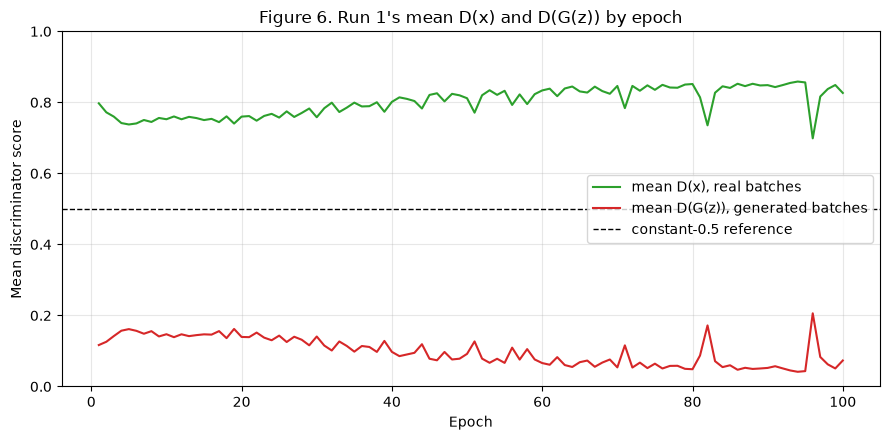

Epoch 1: mean D(x) 0.797, mean D(G(z)) 0.117
Epoch 10: mean D(x) 0.752, mean D(G(z)) 0.147
Epoch 50: mean D(x) 0.812, mean D(G(z)) 0.092
Epoch 100: mean D(x) 0.827, mean D(G(z)) 0.073


In [22]:
def plot_probabilities(log, title):
    """A new figure of the epoch means of D(x) on the real batches and of
    D(G(z)) on the generated ones in log, with the constant-0.5 reference
    marked."""
    epochs = np.arange(1, len(log) + 1)
    means = log.mean(axis=1)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(
        epochs, means[:, 2], color="tab:green", label="mean D(x), real batches"
    )
    ax.plot(
        epochs,
        means[:, 3],
        color="tab:red",
        label="mean D(G(z)), generated batches",
    )
    ax.axhline(
        0.5,
        color="black",
        linestyle="--",
        linewidth=1,
        label="constant-0.5 reference",
    )
    ax.set_ylim(0, 1)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean discriminator score")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(loc="center right")
    fig.tight_layout()
    return fig


fig = plot_probabilities(
    runs[1]["log"],
    "Figure 6. Run 1's mean D(x) and D(G(z)) by epoch",
)
save_figure(fig, 6, "probabilities")
plt.show()
by_epoch = runs[1]["log"].mean(axis=1)
epochs_shown = {e for e in (1, 10, 50) if e < len(by_epoch)} | {len(by_epoch)}
for epoch in sorted(epochs_shown):
    print(
        f"Epoch {epoch}: mean D(x) {by_epoch[epoch - 1, 2]:.3f}, "
        f"mean D(G(z)) {by_epoch[epoch - 1, 3]:.3f}"
    )

**What Figure 6 shows.** The discriminator's mean score on real batches stays well above its score on generated ones, from 0.797 against 0.117 at epoch 1 to 0.827 against 0.073 at epoch 100. The two lines stay either side of the constant-0.5 reference all run, so the discriminator leads throughout.

**The fixed noise at every checkpoint (Figure 7).** One row a checkpoint, from before training at the top to epoch 100 at the bottom. Each row shows the EMA generator on the first 16 of the 64 fixed noise vectors, so the same vectors can be followed down the rows. Each label gives F4's diversity ratio at that checkpoint, measured on all 64.

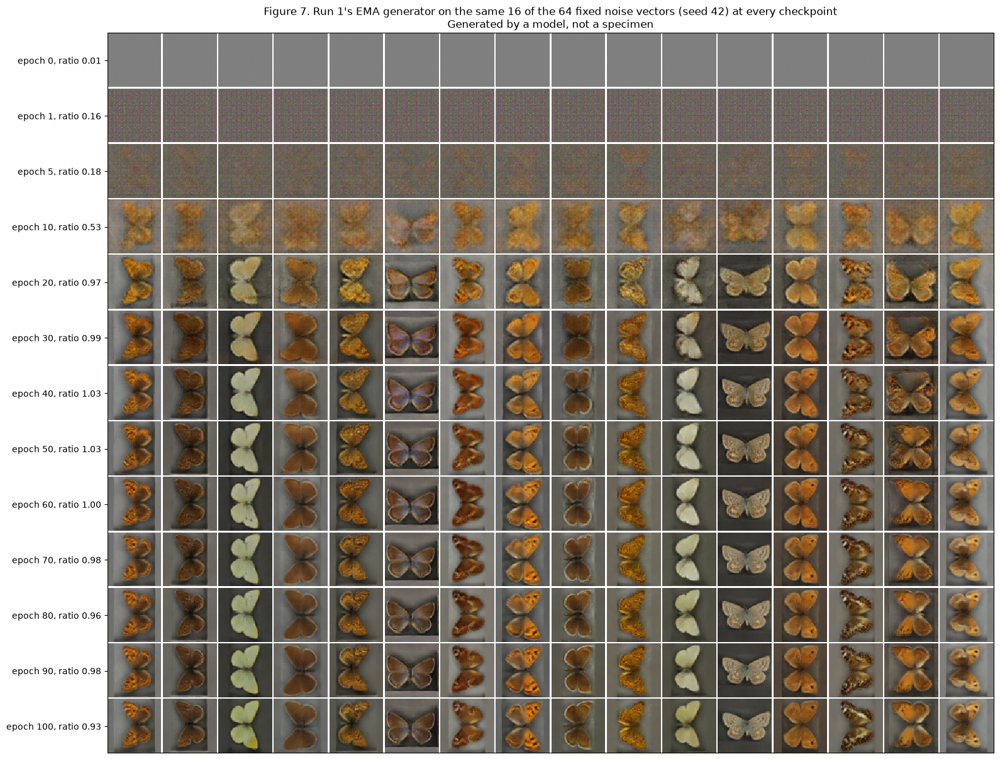

In [23]:
def progression(checkpoints, columns=16):
    """The first columns images of each checkpoint's fixed-noise render,
    one checkpoint a row in epoch order, tiled as one new uint8 array."""
    epochs = sorted(checkpoints)
    return tile(
        np.concatenate([checkpoints[e]["images"][:columns] for e in epochs]),
        cols=columns,
    )


def plot_progression(checkpoints, title, columns=16):
    """A new figure of the progression grid, each row labelled with its
    epoch and the EMA render's diversity ratio."""
    grid = progression(checkpoints, columns)
    epochs = sorted(checkpoints)
    size = checkpoints[epochs[0]]["images"].shape[1]
    fig, ax = plt.subplots(figsize=(16, 1.0 * len(epochs) + 1.2))
    ax.imshow(grid, interpolation="nearest")
    ax.set_yticks([k * (size + 2) + size / 2 for k in range(len(epochs))])
    ax.set_yticklabels(
        [f"epoch {e}, ratio {checkpoints[e]['ratio']:.2f}" for e in epochs]
    )
    ax.set_xticks([])
    ax.set_title(title)
    fig.tight_layout()
    return fig


fig = plot_progression(
    runs[1]["checkpoints"],
    "Figure 7. Run 1's EMA generator on the same 16 of the 64 fixed noise "
    f"vectors (seed {SEED_TRAIN}) at every checkpoint\n"
    "Generated by a model, not a specimen",
)
save_figure(fig, 7, "fixed_noise_progression")
plt.show()

**What Figure 7 shows.** The same 16 noise vectors go from grey before training to blurred shapes at epoch 10, and to recognisable pinned butterflies from epoch 20. Each row's label gives F4's diversity ratio at that checkpoint.

**Run 1's flags.** Each flag, pass or fired, with the epoch it fired and the epoch its window began, then the numbers the flags read.

In [24]:
def ratios_of(run):
    """Each checkpoint epoch's fixed-noise diversity ratio in run, as a new
    dict."""
    return {epoch: c["ratio"] for epoch, c in run["checkpoints"].items()}


flags = {
    1: read_flags(
        runs[1]["log"], ratios_of(runs[1]), runs[1]["nonfinite_epoch"], LINES
    )
}
display(flag_table(flags[1], FLAG_NAMES))
d_means = runs[1]["log"][:, :, 0].mean(axis=1)
g_late = runs[1]["log"][-10:, :, 1].std()
print(
    f"Run 1's epoch-mean discriminator loss ran from {d_means.min():.3f} "
    f"to {d_means.max():.3f} (F1 below {LINES['F1']:.3f}, F2 above "
    f"{LINES['F2']})"
)
print(
    "The generator loss's standard deviation over the last 10 epochs: "
    f"{g_late:.3f} (F3 above {LINES['F3']})"
)
print(
    "Fixed-noise diversity ratio by checkpoint (F4 below "
    f"{LINES['F4']} from epoch 10): "
    + ", ".join(f"{e}: {r:.2f}" for e, r in sorted(ratios_of(runs[1]).items()))
)

,flag,name,result,fired at epoch,window from epoch
0,F1,Discriminator domination,pass,,
1,F2,Discriminator failure,pass,,
2,F3,Unstable generator,fired,10,1
3,F4,Mode collapse,pass,,
4,F5,Non-finite loss,pass,,


Run 1's epoch-mean discriminator loss ran from 0.437 to 1.334 (F1 below 0.425, F2 above 1.5)
The generator loss's standard deviation over the last 10 epochs: 1.032 (F3 above 1.0)
Fixed-noise diversity ratio by checkpoint (F4 below 0.5 from epoch 10): 0: 0.01, 1: 0.16, 5: 0.18, 10: 0.53, 20: 0.97, 30: 0.99, 40: 1.03, 50: 1.03, 60: 1.00, 70: 0.98, 80: 0.96, 90: 0.98, 100: 0.93


**What run 1 shows.**
- **The discriminator leads from the start and keeps leading.** Its loss sits under the constant-0.5 reference almost throughout, falling from 0.676 in the first third of the batches to 0.527 in the last. Over the same thirds mean D(x) rises from 0.760 to 0.833 and mean D(G(z)) falls from 0.140 to 0.067 (Figures 5 and 6). Its epoch mean never fell under F1's line of 0.425, and its lowest was 0.437.
- **The generator loss climbs and spikes.** It rises from 3.443 to 4.018 between the same thirds. Its highest single batch, above 20, came in the first epoch, and later single batches spike up to about 15, well above the moving average (Figure 5). Near epochs 82 and 96 the discriminator slips, with mean D(x) dipping to about 0.7, and recovers within about two epochs (Figure 6).
- **F3 fired at epoch 10, its first chance, with its window from epoch 1.** The first epoch's generator loss averaged 8.106 before settling near 3.5, so the spread over epochs 1 to 10 passed F3's line of 1.0. The spread stayed near the line all run: 1.032 over the last 10 epochs, and at or under 1.0 in 46 of the 91 ten-epoch windows.
- **The fixed noise (Figure 7).** Grey before training, a fine noise texture at epoch 1, a faint butterfly outline at epoch 5 and blurred orange shapes at epoch 10. From epoch 20 each vector gives a recognisable pinned specimen on its tray, and from epoch 40 each keeps much the same specimen. F4's ratio was 0.53 at epoch 10 and between 0.93 and 1.03 from epoch 20 on.
- **The rule.** F3's window began at epoch 1, so no checkpoint from epoch 5 on came before it. By the written rule run 1 failed, and F3 called run 2.

**Runs 2 and 3, only if a flag calls them.** The cell reads run 1's flags and makes run 2, then run 3, only as the rule above says. Each run made shows its curves, its progression grid and its flags.

F3 fired in run 1, so run 2 is made.


Run 2 epoch   1: D loss 0.600, G loss 6.318, D(x) 0.807, D(G(z)) 0.102, 5.1 s for the epoch, 0.1 min so far, 6,747 MiB in use


Run 2 epoch   5: D loss 0.687, G loss 3.239, D(x) 0.742, D(G(z)) 0.155, 4.5 s for the epoch, 0.4 min so far, 6,749 MiB in use


Run 2 epoch  10: D loss 0.633, G loss 3.000, D(x) 0.755, D(G(z)) 0.144, 4.5 s for the epoch, 0.8 min so far, 6,749 MiB in use


Run 2 epoch  20: D loss 0.650, G loss 2.702, D(x) 0.745, D(G(z)) 0.154, 4.5 s for the epoch, 1.5 min so far, 6,808 MiB in use


...

Run 2 epoch  60: D loss 0.643, G loss 2.831, D(x) 0.767, D(G(z)) 0.132, 4.6 s for the epoch, 4.6 min so far, 6,808 MiB in use


Run 2 epoch  70: D loss 0.617, G loss 2.962, D(x) 0.783, D(G(z)) 0.117, 4.6 s for the epoch, 5.4 min so far, 6,808 MiB in use


Run 2 epoch  80: D loss 0.659, G loss 2.964, D(x) 0.776, D(G(z)) 0.125, 4.5 s for the epoch, 6.1 min so far, 6,808 MiB in use


Run 2 epoch  90: D loss 0.646, G loss 2.969, D(x) 0.775, D(G(z)) 0.124, 4.5 s for the epoch, 6.9 min so far, 6,808 MiB in use


Run 2 epoch 100: D loss 0.448, G loss 3.358, D(x) 0.833, D(G(z)) 0.067, 4.5 s for the epoch, 7.7 min so far, 6,808 MiB in use
Run 2: 100 epochs in 7.7 minutes, PyTorch's peak 1,004 MiB allocated and 1,110 MiB reserved, the watchdog's highest reading 6,821 MiB in use on the GPU.


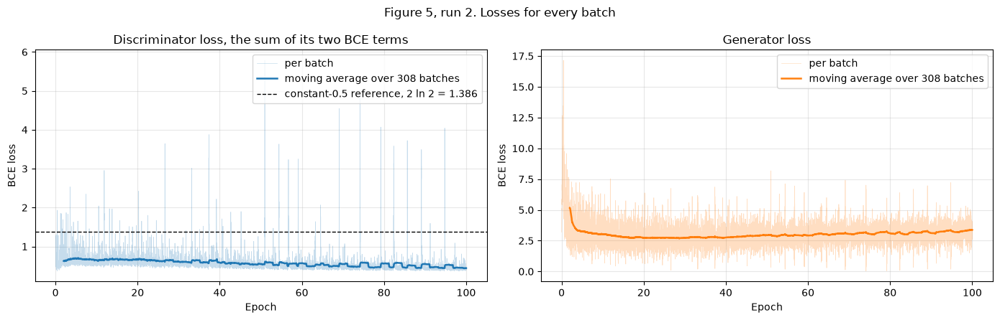

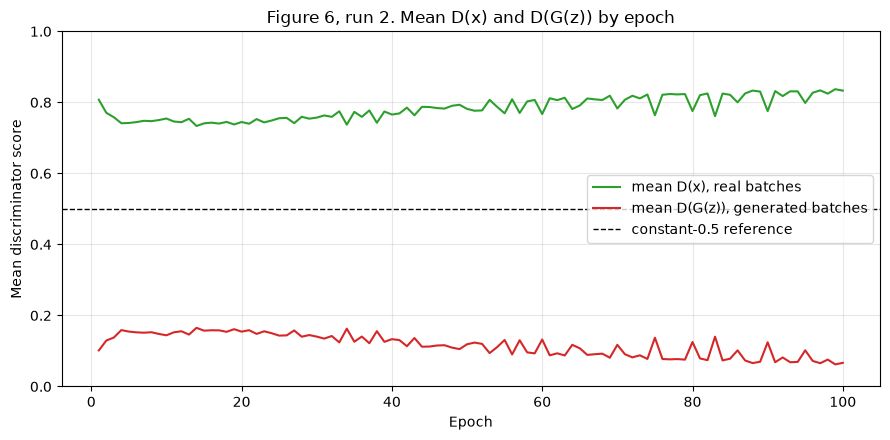

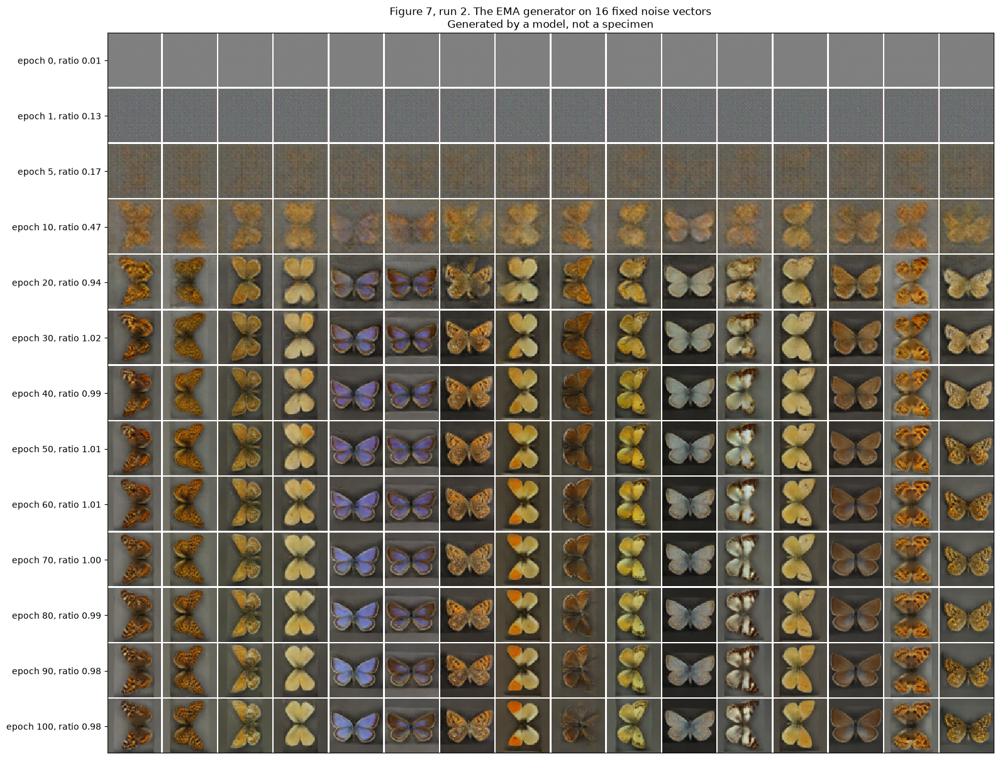

,flag,name,result,fired at epoch,window from epoch
0,F1,Discriminator domination,pass,,
1,F2,Discriminator failure,pass,,
2,F3,Unstable generator,fired,10,1
3,F4,Mode collapse,fired,10,10
4,F5,Non-finite loss,pass,,


F3, F4 fired in run 2, so run 3 is made.


Run 3 epoch   1: D loss 2.436, G loss 2.101, D(x) 0.444, D(G(z)) 0.695, 4.5 s for the epoch, 0.1 min so far, 6,809 MiB in use


Run 3 epoch   5: D loss 1.101, G loss 1.495, D(x) 0.562, D(G(z)) 0.330, 4.6 s for the epoch, 0.4 min so far, 6,808 MiB in use


Run 3 epoch  10: D loss 1.218, G loss 1.120, D(x) 0.506, D(G(z)) 0.389, 4.5 s for the epoch, 0.8 min so far, 6,808 MiB in use


...

Run 3 epoch  60: D loss 1.029, G loss 1.374, D(x) 0.575, D(G(z)) 0.325, 4.4 s for the epoch, 4.6 min so far, 6,808 MiB in use


Run 3 epoch  70: D loss 0.966, G loss 1.453, D(x) 0.597, D(G(z)) 0.303, 4.6 s for the epoch, 5.4 min so far, 6,808 MiB in use


Run 3 epoch  80: D loss 0.913, G loss 1.541, D(x) 0.616, D(G(z)) 0.283, 4.5 s for the epoch, 6.2 min so far, 6,808 MiB in use


Run 3 epoch  90: D loss 0.863, G loss 1.620, D(x) 0.634, D(G(z)) 0.265, 4.6 s for the epoch, 6.9 min so far, 6,808 MiB in use


Run 3 epoch 100: D loss 0.812, G loss 1.702, D(x) 0.653, D(G(z)) 0.246, 4.6 s for the epoch, 7.7 min so far, 6,808 MiB in use
Run 3: 100 epochs in 7.7 minutes, PyTorch's peak 1,004 MiB allocated and 1,110 MiB reserved, the watchdog's highest reading 6,809 MiB in use on the GPU.


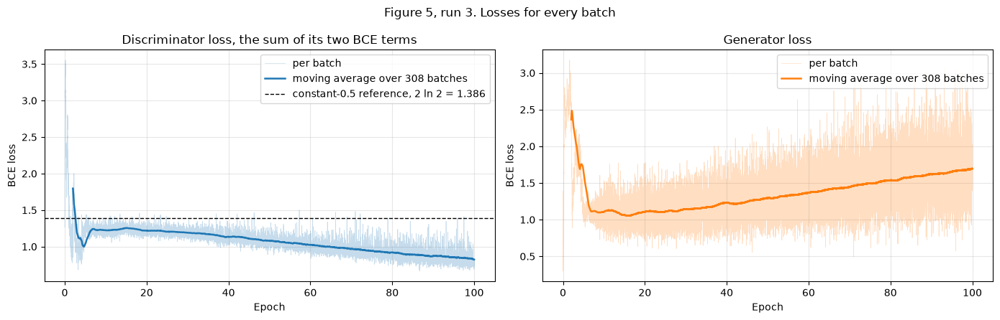

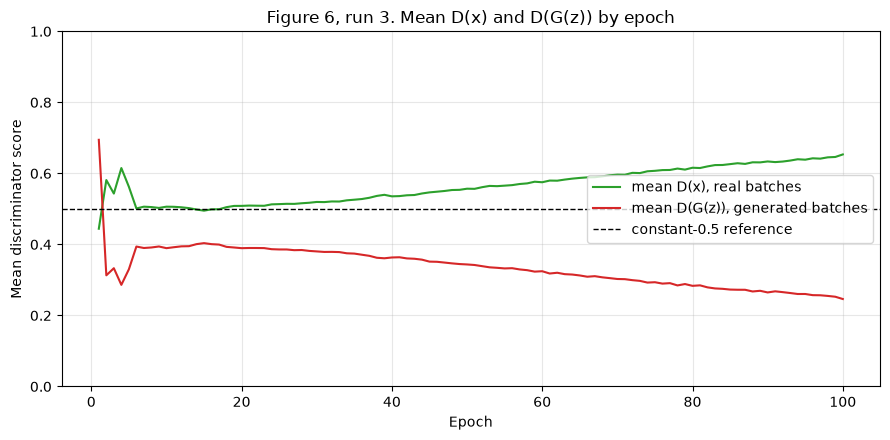

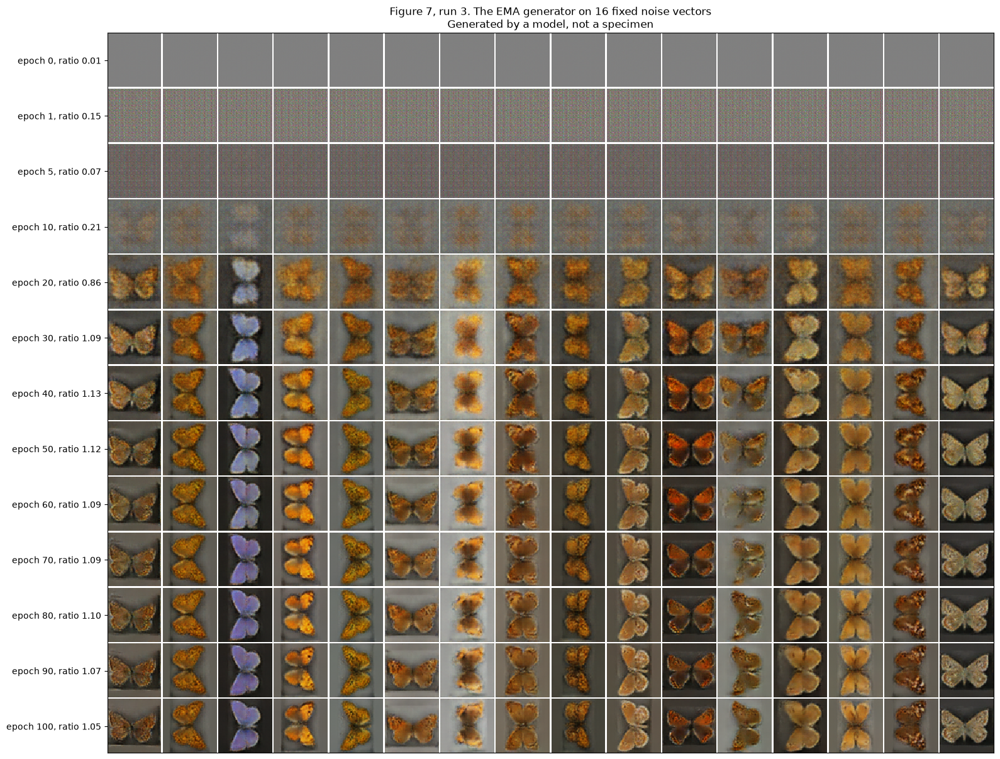

,flag,name,result,fired at epoch,window from epoch
0,F1,Discriminator domination,pass,,
1,F2,Discriminator failure,pass,,
2,F3,Unstable generator,pass,,
3,F4,Mode collapse,fired,10,10
4,F5,Non-finite loss,pass,,


F4 fired in run 3, and there is no fourth run.


In [25]:
following, reason = next_run(flags[1], 1)
print(f"{reason}.")
while following is not None:
    k = following
    runs[k] = train_run(
        train_u8,
        run_settings(RUN1, k, LR_D_TTUR),
        fixed_z,
        f4_reference,
        device,
        on_rig,
        Path(f"outputs/run{k}"),
        watchdog,
        used_mib,
    )
    print(describe_run(runs[k]))
    if runs[k]["stop"] and runs[k]["nonfinite_epoch"] is None:
        raise RuntimeError(
            f"the watchdog stopped run {k} ({runs[k]['stop']}), so no "
            "further run is made"
        )
    plot_losses(runs[k]["log"], f"Figure 5, run {k}. Losses for every batch")
    plt.show()
    plot_probabilities(
        runs[k]["log"], f"Figure 6, run {k}. Mean D(x) and D(G(z)) by epoch"
    )
    plt.show()
    plot_progression(
        runs[k]["checkpoints"],
        f"Figure 7, run {k}. The EMA generator on 16 fixed noise vectors\n"
        "Generated by a model, not a specimen",
    )
    plt.show()
    flags[k] = read_flags(
        runs[k]["log"], ratios_of(runs[k]), runs[k]["nonfinite_epoch"], LINES
    )
    display(flag_table(flags[k], FLAG_NAMES))
    following, reason = next_run(flags[k], k)
    print(f"{reason}.")

**What runs 2 and 3 show.**
- **Run 2, with spectral normalisation,** still let the discriminator lead: at epoch 100 mean D(x) was 0.833 and mean D(G(z)) 0.067. Its generator loss settled more than run 1's: after the first few epochs its single batches spike to about 8, against about 15 in run 1 (Figure 5). But its first epoch averaged 6.318, and F3 fired at epoch 10 again, with its window from epoch 1. F4 fired at the same checkpoint, with a ratio of 0.47, which was between 0.94 and 1.02 from epoch 20 on.
- **Run 3 kept spectral normalisation and slowed the discriminator to 0.00005,** the two time-scale update rule. It is the most even of the three runs. Its discriminator's epoch-mean loss began above the constant-0.5 reference, at 2.436 in epoch 1, then fell under it within a few epochs and eased to 0.812 by epoch 100 (Figure 5, run 3). Mean D(x) and D(G(z)) parted slowly, to 0.653 and 0.246. Its single-batch generator loss peaked near 3 (Figure 5, run 3), and F3 stayed quiet.
- **But run 3 learnt slowly.** At epoch 5 its live generator, the one being trained, had a diversity ratio of 0.65, against 1.01 and 0.99 in runs 1 and 2 (printed at the end of Task 3). F4 reads the EMA generator, and at epoch 10 its fixed noise still gave blurred, near-identical shapes, with a ratio of 0.21, so F4 fired there. From epoch 30 its ratio stayed between 1.05 and 1.13, and each vector gives a recognisable pinned specimen (Figure 7, run 3).
- F4 in run 3 ends the runs, as there is no fourth.

**The checkpoint rule applied.** The rule picks the checkpoint from the last run made. Its EMA generator and its discriminator are kept in `models/rule_as_written/`, labelled with the run and the epoch, apart from the submitted checkpoints that Task 4 saves to `models/`. Then the training set and the untrained networks are freed from the GPU.

In [26]:
def copy_checkpoint(files, folder, prefix=""):
    """Copy the EMA generator and the discriminator at files into folder,
    made if missing, named prefix plus generator_ema.pt and discriminator.pt,
    and return the copies' paths as a new dict. The files are not changed."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    copies = {}
    for name in ("generator_ema", "discriminator"):
        copies[name] = folder / f"{prefix}{name}.pt"
        shutil.copyfile(files[name], copies[name])
    return copies


last = max(runs)
saved = sorted(runs[last]["checkpoints"])
chosen = choose_checkpoint(flags[last], saved)
fired = [key for key, found in flags[last].items() if found]
print(
    f"The final model comes from run {last}, the last run made. Flags fired "
    f"in it: {', '.join(fired) if fired else 'none'}."
)
if chosen is None:
    raise RuntimeError(
        f"run {last} has no checkpoint the rule can pick, so the run failed"
    )
print(
    f"The checkpoint rule picks the EMA generator at epoch {chosen} of run "
    f"{last}, the {'last epoch' if not fired else 'fallback checkpoint'}."
)
if "F2" in fired:
    print("F2 fired, so this model stands as a failed run's fallback.")
# The rule's pick is kept in its own folder, labelled with its run and
# epoch, apart from the submitted checkpoints Task 4 saves to models/.
files = runs[last]["checkpoints"][chosen]["files"]
rule_copies = copy_checkpoint(
    files, Path("models/rule_as_written"), f"run{last}_epoch{chosen:03d}_"
)
for name, path in rule_copies.items():
    print(
        f"{path}: {path.stat().st_size / 2**20:.1f} MiB, "
        f"SHA-256 {bws.file_sha256(path)}, from {files[name]}"
    )
chosen_d = runs[last]["log"][chosen - 1].mean(axis=0)
print(
    f"Epoch {chosen}'s means: D loss {chosen_d[0]:.3f}, G loss "
    f"{chosen_d[1]:.3f}, D(x) {chosen_d[2]:.3f}, D(G(z)) {chosen_d[3]:.3f}"
)
# Task 4 loads the networks it evaluates from models/, so I free the
# training set and the untrained networks from the GPU here.
del train_u8, generator, discriminator, real_64, fake_64
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()
    print(
        "GPU memory held by PyTorch after freeing the training run: "
        f"{torch.cuda.memory_allocated() / 2**20:.0f} MiB allocated, "
        f"{torch.cuda.memory_reserved() / 2**20:.0f} MiB reserved"
    )

The final model comes from run 3, the last run made. Flags fired in it: F4.
The checkpoint rule picks the EMA generator at epoch 5 of run 3, the fallback checkpoint.
models/rule_as_written/run3_epoch005_generator_ema.pt: 13.7 MiB, SHA-256 e9238503a204a20db670406cb8eecff4638c861c68f8ec15cb0afcaff44df6d7, from outputs/run3/epoch_005_generator_ema.pt
models/rule_as_written/run3_epoch005_discriminator.pt: 10.6 MiB, SHA-256 bad22c428521b5cf88dc9b18d07439600494e08b1d00223c9131077fecc86dd2, from outputs/run3/epoch_005_discriminator.pt
Epoch 5's means: D loss 1.101, G loss 1.495, D(x) 0.562, D(G(z)) 0.330
GPU memory held by PyTorch after freeing the training run: 32 MiB allocated, 74 MiB reserved


**The model the rule chose, and the failure it reports.** Applied as written, the rule picks run 3's EMA generator at epoch 5. F4 fired at epoch 10, and epoch 5 is the last checkpoint from epoch 5 on before that. At epoch 5 run 3's EMA generator still makes a fine noise texture, with a diversity ratio of 0.07, lower than the 0.21 that fired F4 (Figure 7, run 3). So the chosen model is close to untrained, and this result stands in the notebook as a failure of the rule. At epoch 5 the EMA still holds about half of its random start, whatever the generator has learnt by then (below).
- In all three runs a flag fired at its first chance, at epoch 10. F3's first window took in the first epoch's start-up spike, and its line of 1.0 sits close to this generator's normal spread, so leaving out epoch 1 does not clear it (below). F4 read the EMA generator, not the live one. The EMA starts as a copy of the untrained generator and moves 0.1 per cent of the way to the live weights each step. So at epoch 10 it still holds about a fifth of its random start. The live generators already varied then, with ratios near 1.0 (below). So F4 caught the EMA's warm-up lag, not a collapse.
- Every run's later checkpoints show varied, recognisable specimens, with ratios near 1.0. The rule was fixed before training, and I have not changed it after seeing these results.
- The 32 MiB still allocated after freeing is the workspace the CUDA Basic Linear Algebra Subprograms library (cuBLAS) keeps for the deterministic setting. No tensor is left on the GPU.

**The rule as written, a minimal correction, and the model I evaluate.** The rule above picks run 3's EMA generator at epoch 5. The next cell shows what that model makes, on the first 16 of the noise vectors Task 4 uses. It then applies one correction to the rule and changes nothing else: no flag window takes in epoch 1, the start-up transient. It prints each run's flags as written and as corrected, then run 1's ten-epoch spreads of the generator loss against F3's line, and F4's diversity ratios. Last, it prints the same ratio on the live generator at epochs 5 and 10, and the share of its random start the EMA generator still holds, because F4 reads the EMA.

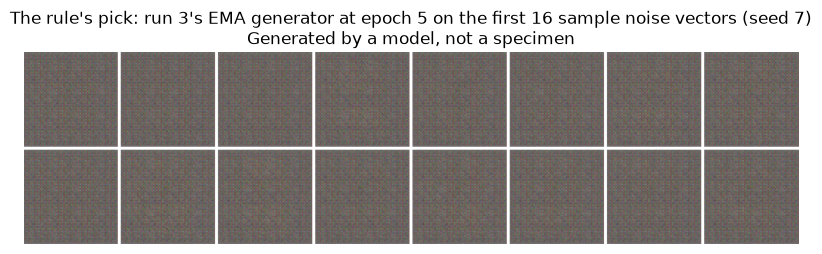

Run 3 at epoch 5: diversity ratio 0.07 on the fixed noise


,run 1 as written,"run 1, windows from epoch 2",run 2 as written,"run 2, windows from epoch 2",run 3 as written,"run 3, windows from epoch 2"
F1,pass,pass,pass,pass,pass,pass
F2,pass,pass,pass,pass,pass,pass
F3,"fired at epoch 10, window from 1","fired at epoch 11, window from 2","fired at epoch 10, window from 1","fired at epoch 11, window from 2",pass,pass
F4,pass,pass,"fired at epoch 10, window from 10","fired at epoch 10, window from 10","fired at epoch 10, window from 10","fired at epoch 10, window from 10"
F5,pass,pass,pass,pass,pass,pass


With windows from epoch 2: F3 fired in run 1, so run 2 is made.
With windows from epoch 2: F3, F4 fired in run 2, so run 3 is made.
With windows from epoch 2: F4 fired in run 3, and there is no fourth run.
So the corrected rule still ends on run 3 and picks epoch 5.
Run 1's ten-epoch generator loss spreads: 46 of 91 windows at or under F3's line of 1.0. Leaving out every window that takes in epoch 1, 44 of 90 are above it. The last, epochs 91 to 100, is 1.032
F4's diversity ratio at epoch 10, the first checkpoint it reads: run 1 0.53, run 2 0.47, run 3 0.21; from epoch 20 on, the lowest in any run is 0.86
F4's ratio on the live generator, epochs 5 and 10: run 1 1.01, 1.04; run 2 0.99, 0.95; run 3 0.65, 0.90
The EMA's share of its random start: 0.46 at epoch 5, 0.21 at epoch 10, 0.05 at epoch 20


In [27]:
def checkpoint_files(run, epoch, root="outputs"):
    """The EMA generator and the discriminator saved for run at epoch, as a
    new dict of paths."""
    folder = Path(root) / f"run{run}"
    return {
        name: folder / f"epoch_{epoch:03d}_{name}.pt"
        for name in ("generator_ema", "discriminator")
    }


def load_networks(files, spectral, device):
    """The EMA generator and the discriminator saved at files, a dict with
    the keys generator_ema and discriminator, in new networks on device in
    evaluation mode, as (generator, discriminator). spectral says whether
    the discriminator was spectrally normalised."""
    generator, discriminator = make_models(0, spectral=spectral)
    for net, name in (
        (generator, "generator_ema"),
        (discriminator, "discriminator"),
    ):
        state = torch.load(files[name], map_location="cpu", weights_only=True)
        net.load_state_dict(state)
    return generator.to(device).eval(), discriminator.to(device).eval()


def load_checkpoint(run, epoch, spectral, device, root="outputs"):
    """The EMA generator and the discriminator saved for run at epoch, in
    new networks on device in evaluation mode, as (generator,
    discriminator). spectral says whether the run's discriminator was
    spectrally normalised."""
    return load_networks(checkpoint_files(run, epoch, root), spectral, device)


def trailing_spreads(log, window=10):
    """The standard deviation of the per-batch generator loss over each run
    of window epochs, keyed by the epoch that ends it, from epoch window on,
    as a new dict. F3 reads these against its line."""
    g = log[:, :, 1]
    spreads = {}
    for epoch in range(window, len(log) + 1):
        start = epoch - window
        spreads[epoch] = float(g[start:epoch].std())
    return spreads


def flag_summary(flags):
    """Each flag as "pass" or where it fired, in a new dict keyed F1 to F5."""
    return {
        key: (
            f"fired at epoch {found[0]}, window from {found[1]}"
            if found
            else "pass"
        )
        for key, found in flags.items()
    }


def live_ratios(run, reference, epochs):
    """F4's diversity ratio on the live generator's fixed-noise images at
    each of epochs in run, against reference, as a new dict."""
    return {
        epoch: mean_pairwise_distance(run["checkpoints"][epoch]["live_images"])
        / reference
        for epoch in epochs
    }


# The rule as written picked this checkpoint (the cell above). Its
# samples on the first 16 of Task 4's noise vectors show what it makes.
picked_g, _ = load_checkpoint(
    last, chosen, runs[last]["settings"]["spectral"], device
)
picked = render(picked_g, noise_batch(16, SEED_SAMPLES, NZ), device)
del picked_g
plt.figure(figsize=(10, 3.2))
plt.imshow(tile(picked, cols=8))
plt.title(
    f"The rule's pick: run {last}'s EMA generator at epoch {chosen} on the "
    f"first 16 sample noise vectors (seed {SEED_SAMPLES})\n"
    "Generated by a model, not a specimen"
)
plt.axis("off")
plt.show()
print(
    f"Run {last} at epoch {chosen}: diversity ratio "
    f"{runs[last]['checkpoints'][chosen]['ratio']:.2f} on the fixed noise"
)

# The one-line correction: no flag window takes in epoch 1, the start-up
# transient. Everything else in the rule stays as written.
corrected = {
    k: read_flags(
        runs[k]["log"],
        ratios_of(runs[k]),
        runs[k]["nonfinite_epoch"],
        LINES,
        first_epoch=2,
    )
    for k in runs
}
columns = {}
for k in runs:
    columns[f"run {k} as written"] = flag_summary(flags[k])
    columns[f"run {k}, windows from epoch 2"] = flag_summary(corrected[k])
with pd.option_context("display.max_colwidth", 40, "display.width", 200):
    display(pd.DataFrame(columns))
for k in runs:
    print(f"With windows from epoch 2: {next_run(corrected[k], k)[1]}.")
again = choose_checkpoint(corrected[last], saved)
print(
    f"So the corrected rule still ends on run {last} and picks epoch "
    f"{again}."
)

spreads = trailing_spreads(runs[1]["log"])
on_or_under = sum(s <= LINES["F3"] for s in spreads.values())
late = {e: s for e, s in spreads.items() if e > 10}
print(
    f"Run 1's ten-epoch generator loss spreads: {on_or_under} of "
    f"{len(spreads)} windows at or under F3's line of {LINES['F3']}. "
    f"Leaving out every window that takes in epoch 1, "
    f"{sum(s > LINES['F3'] for s in late.values())} of {len(late)} are "
    f"above it. The last, epochs {max(spreads) - 9} to {max(spreads)}, is "
    f"{spreads[max(spreads)]:.3f}"
)
late_low = min(
    r for k in runs for e, r in ratios_of(runs[k]).items() if e >= 20
)
print(
    "F4's diversity ratio at epoch 10, the first checkpoint it reads: "
    + ", ".join(
        f"run {k} {runs[k]['checkpoints'][10]['ratio']:.2f}" for k in runs
    )
    + f"; from epoch 20 on, the lowest in any run is {late_low:.2f}"
)
# F4 reads the EMA generator, which starts as the untrained generator and
# keeps decay to the power of the steps taken of that start. The live
# generator's ratio shows what the generator itself had learnt by then.
live = {k: live_ratios(runs[k], f4_reference, (5, 10)) for k in runs}
print(
    "F4's ratio on the live generator, epochs 5 and 10: "
    + "; ".join(f"run {k} {r[5]:.2f}, {r[10]:.2f}" for k, r in live.items())
)
ema_decay = RUN1["ema_decay"]
print(
    "The EMA's share of its random start: "
    f"{ema_decay ** (5 * steps):.2f} at epoch 5, "
    f"{ema_decay ** (10 * steps):.2f} at epoch 10, "
    f"{ema_decay ** (20 * steps):.2f} at epoch 20"
)

**What the correction shows, and the model I evaluate.**
- **The rule as written** picks run 3's EMA generator at epoch 5. Its samples above are fine noise textures with no specimen in them, and its diversity ratio of 0.07 is lower than the 0.21 that fired F4. Applied as written, the rule chooses a model close to untrained.
- **The defect.** F3's first window reached back to epoch 1, so a normal start-up transient, the first epoch's generator loss, read as instability. F4 read the EMA generator, which starts as a copy of the untrained generator and has no warm-up. At epoch 10 the EMA still held about a fifth of its random start, a share of 0.21, while the live generators' ratios were already 0.90 to 1.04. So the EMA's lag read as collapse. The fallback then pointed backwards in training, to a checkpoint before either window began, where the EMA still held about half of its random start, a share of 0.46.
- **The minimal correction** starts every flag window at epoch 2 and changes nothing else. It does not clear run 1: F3 now fires at epoch 11, with its window from epoch 2, so no checkpoint from epoch 5 on comes before it. Run 1's generator loss spread sits near F3's line of 1.0 all through training. 46 of its 91 ten-epoch windows are at or under the line, and 44 of the 90 that leave out epoch 1 are above it. The last, epochs 91 to 100, is 1.032. F4 still fires for runs 2 and 3 at epoch 10, because it still reads the EMA there, so the corrected rule still ends on run 3 at epoch 5.
- **A finding about the failure flags.** F3's line of 1.0 came from my coursework's check on a different GAN, and this generator's loss spreads that much while its samples stay recognisable from epoch 20 on (Figure 7). F4 read the EMA's warm-up lag, not the generator. From epoch 20 on, no run's ratio fell below 0.86. So F3's line was set too tight for this model, and F4 read the EMA before it had warmed up. The generator itself trained well. I did not re-tune the rule after seeing the results, because that would fit the rule to the answer. A future version would read F4 on the live generator, or warm the EMA up, and would set F3's line from a trial run before training.
- **The model I evaluate.** Run 1's EMA generator at epoch 100. It is the plain recipe set before training, from the first run made, at its last epoch, so it takes the least choosing after seeing the outputs. It was chosen after seeing the outputs of all three runs, and confirmed by me, so the choice is not blind. Runs 2 and 3 stay above as evidence on stability.

## Task 4: Generate and Evaluate Outputs

**Goal.** Generate samples from the trained generator and set them beside real held-out images. Then judge them: each numbered sample scored against written scoring criteria, then strengths, limitations and failure cases tied to those numbers. Last come a check for memorised training images, with a positive control on known near-copies, two supplementary measures and one optional test of the discriminator as a quality flag. The held-out images are used here, for evaluation only.

The model evaluated is run 1's EMA generator at epoch 100, chosen after seeing the outputs and confirmed by me (end of Task 3). The next cell names it in one variable, `EVALUATED`, saves its EMA generator and discriminator to `models/` as the submitted checkpoints, and loads them from there.

In [28]:
# Run 1's EMA generator at its last epoch, chosen after seeing the outputs
# and confirmed by me (end of Task 3). Every cell below reads this one name.
EVALUATED = {"run": 1, "epoch": 100}

ev_run, ev_epoch = EVALUATED["run"], EVALUATED["epoch"]
ev_spectral = run_settings(RUN1, ev_run, LR_D_TTUR)["spectral"]
# The submitted checkpoints: the EMA generator and its discriminator, saved
# to models/ under fixed names, and loaded from there for the evaluation.
sources = checkpoint_files(ev_run, ev_epoch)
submitted = copy_checkpoint(sources, Path("models"))
generator_eval, discriminator_eval = load_networks(
    submitted, ev_spectral, device
)
print(
    f"Evaluating run {ev_run}'s EMA generator at epoch {ev_epoch}, with its "
    f"discriminator. The written rule picked run {last} at epoch {chosen}."
)
for name, path in submitted.items():
    print(
        f"{path}: {path.stat().st_size / 2**20:.1f} MiB, "
        f"SHA-256 {bws.file_sha256(path)}, from {sources[name]}"
    )
held_out_images = part_images(arrays, rows, "held_out")
print(
    f"Held-out images: {len(held_out_images):,}, every held-out crop, "
    "used here for evaluation only"
)

Evaluating run 1's EMA generator at epoch 100, with its discriminator. The written rule picked run 3 at epoch 5.
models/generator_ema.pt: 13.7 MiB, SHA-256 14cc876e779c9cd012ee132ae12cec1c708173b695f2df9929815f9dc9dba36d, from outputs/run1/epoch_100_generator_ema.pt
models/discriminator.pt: 10.6 MiB, SHA-256 f1f72269883f2b6e68916abfb016859f4abd8143e5acc3613f467fbd58562a52, from outputs/run1/epoch_100_discriminator.pt
Held-out images: 2,200, every held-out crop, used here for evaluation only


**What the checkpoint cell shows.** Task 4 evaluates the submitted checkpoints in `models/`, run 1's EMA generator and discriminator at epoch 100, each printed with its hash. All 2,200 held-out crops are loaded for the evaluation.

**The samples (Figure 8).** 64 samples from the evaluated generator, from 64 noise vectors drawn with seed 7, numbered 1 to 64 in rows of eight, left to right. I cite each by its number, as #22. Beside them, as the real standard, are 64 held-out crops drawn with seed 7, in the same layout. Like many of the photographs, many samples show the specimen turned on its side, as a portrait tray holds it, so its two halves lie above and below the body.

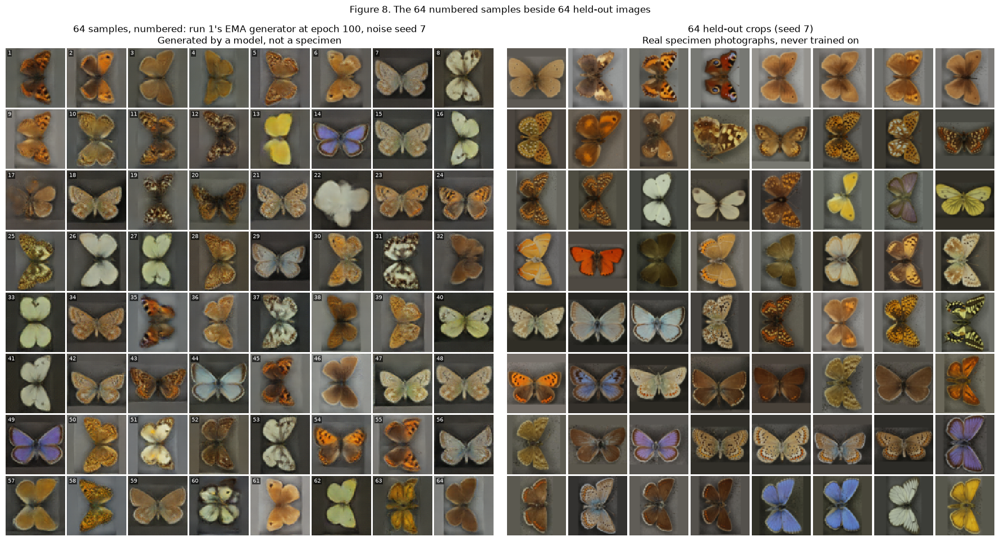

Samples: (64, 64, 64, 3), uint8, pixel values 4 to 239, SHA-256 of the pixels 3f6cd1920e9337ba824de45d47819418cd89276e4ade6cdeeb72e64eeb6ffb8c


In [29]:
import hashlib  # noqa: E402


def pixel_sha256(images):
    """The SHA-256 of the images' uint8 pixels, as a hex string."""
    return hashlib.sha256(
        np.ascontiguousarray(images, dtype=np.uint8).tobytes()
    ).hexdigest()


def plot_numbered(ax, images, cols=8, first=1):
    """Draw images on ax in rows of cols, each with its number in its top
    left corner, counting from first."""
    size = images.shape[1]
    ax.imshow(tile(images, cols=cols), interpolation="nearest")
    for k in range(len(images)):
        row, col = divmod(k, cols)
        ax.text(
            col * (size + 2) + 2,
            row * (size + 2) + 2,
            str(first + k),
            color="white",
            fontsize=7,
            va="top",
            ha="left",
            bbox={"facecolor": "black", "alpha": 0.6, "pad": 1, "lw": 0},
        )
    ax.axis("off")


sample_z = noise_batch(64, SEED_SAMPLES, NZ)
samples = render(generator_eval, sample_z, device)
held_64 = np.sort(
    np.random.default_rng(SEED_SAMPLES).choice(
        len(held_out_images), 64, replace=False
    )
)
fig, axes = plt.subplots(1, 2, figsize=(18, 9.8))
plot_numbered(axes[0], samples)
axes[0].set_title(
    f"64 samples, numbered: run {ev_run}'s EMA generator at epoch "
    f"{ev_epoch}, noise seed {SEED_SAMPLES}\n"
    "Generated by a model, not a specimen"
)
axes[1].imshow(tile(held_out_images[held_64], cols=8), interpolation="nearest")
axes[1].set_title(
    f"64 held-out crops (seed {SEED_SAMPLES})\n"
    "Real specimen photographs, never trained on"
)
axes[1].axis("off")
fig.suptitle("Figure 8. The 64 numbered samples beside 64 held-out images")
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_figure(fig, 8, "samples_and_held_out")
plt.show()
sample_digest = pixel_sha256(samples)
print(
    f"Samples: {samples.shape}, {samples.dtype}, pixel values "
    f"{samples.min()} to {samples.max()}, SHA-256 of the pixels "
    f"{sample_digest}"
)

**What Figure 8 shows.** Most of the 64 numbered samples read as single butterflies on a grey tray, in the browns, oranges, blues and whites of the held-out crops beside them. A few fail outright, such as #22, and the written scoring criteria below score each one.

**The written scoring criteria.** Five criteria, written into the plan before training, each scored 0, 0.5 or 1 for every numbered sample, with one reason per sample:

| Criterion | 1 | 0.5 | 0 |
|---|---|---|---|
| Wing symmetry | the two halves match in shape and size | visibly uneven | a half missing, merged or misshapen |
| Pattern coherence | the markings are consistent and mirror across the halves | smeared, noisy or partly unmatched | no coherent pattern |
| Body and antennae | a clear body down the middle, with antennae where this size shows them | faint or broken | none |
| Background or label artefacts | a clean tray, as in the photographs | a faint mark or stain | a label-like block or strong artefact |
| Species plausibility | a plausible British butterfly of a family in the real grid | the family shows but details are off | not plausibly a butterfly |

Theis et al. (2016, sec. 4, p. 8): "A subjective evaluation based on visual fidelity of samples is still clearly appropriate when the goal is image synthesis." Goodfellow et al. (2016, sec. 20.14, p. 714) say the best case is raters "who do not know the source of the samples". An AI assistant drafted a score and a reason for each of the 64 samples against the written scoring criteria. I checked and confirmed them, so the judgement is mine, as one lay rater, me, who knew the samples were generated. So the scores carry my bias, and species plausibility is a lay judgement. The cell also measures the border of every sample for near-white pixels, the mark a white label left at the crop's edge would make. It runs the same measure on the 21 audited crops known to keep part of a label or card (Task 2), to show what it can detect.

The scores were written for the 64 samples whose pixels have the SHA-256 hash `3f6cd1920e93...` that the cell above prints (Figure 8, run 1 at epoch 100). This cell checks that hash first. On a rerun that draws other samples, for example on other hardware, it prints a warning and shows no scores or reasons, because they would describe other images. The findings below would not describe them either.

In [30]:
def score_table(scores, criteria):
    """The scores as a new frame indexed by sample number, one column
    per criterion, then each sample's total and its reason.

    scores holds one tuple per sample: its number, a score per criterion and
    a reason. The numbers must run 1, 2, 3 and so on, each score must be 0,
    0.5 or 1, and each reason must be written, or ValueError is raised."""
    table = pd.DataFrame(scores, columns=["sample", *criteria, "reason"])
    if list(table["sample"]) != list(range(1, len(table) + 1)):
        raise ValueError("the samples must be numbered 1, 2, 3 in order")
    if not table[criteria].isin([0, 0.5, 1]).all().all():
        raise ValueError("every score must be 0, 0.5 or 1")
    if not table["reason"].str.strip().astype(bool).all():
        raise ValueError("every sample needs a reason")
    table = table.set_index("sample")
    table.insert(len(criteria), "total", table[criteria].sum(axis=1))
    return table


def border_white_share(images, width=3, level=170):
    """The share of each image's border pixels, width pixels deep, whose
    three channels are all above level, as a new array. A white paper label
    left at the crop's edge would show here."""
    edge = np.zeros(images.shape[1:3], dtype=bool)
    edge[:width] = edge[-width:] = True
    edge[:, :width] = edge[:, -width:] = True
    near_white = (images[:, edge] > level).all(axis=2)
    return near_white.mean(axis=1)


def scores_guard(images, scored_sha256):
    """None when images are the samples the scores were written for, by the
    SHA-256 of their pixels, otherwise the warning to print, as a string."""
    found = pixel_sha256(images)
    if found == scored_sha256:
        return None
    return (
        f"Warning: these samples hash to {found[:12]}..., not the samples "
        f"the scores were written for, {scored_sha256[:12]}.... The scores, "
        "reasons and findings describe the submitted samples, not these, so "
        "they are not shown"
    )


def all_crops(arrays, rows):
    """Every crop of the fixed set in the manifest's order, flagged or not,
    as a new uint8 array."""
    out = np.empty((len(rows), *arrays["flagged"].shape[1:]), dtype=np.uint8)
    for part in ("training", "held_out"):
        out[(rows["part"] == part).to_numpy()] = part_images(
            arrays, rows, part
        )
    return out


def rows_for(rows, prefixes):
    """The row of the one file whose name starts with each prefix and an
    underscore, in the order given, as a new array. A prefix that matches
    no row, or more than one, raises ValueError."""
    stems = rows["file_name"].str.split("_").str[0].to_numpy()
    found = []
    for prefix in prefixes:
        hits = np.flatnonzero(stems == prefix)
        if len(hits) != 1:
            raise ValueError(f"{prefix} matches {len(hits)} rows, not one")
        found.append(int(hits[0]))
    return np.array(found)


CRITERIA = [
    "wing symmetry",
    "pattern coherence",
    "body and antennae",
    "background or label artefacts",
    "species plausibility",
]
# The scores, drafted with an AI assistant and confirmed by me: one row per
# numbered sample, with its five scores in the order above, then one reason
# per sample, in the same order. SCORED_SHA256 is the hash of the pixels of
# the 64 samples they were written for, run 1 at epoch 100.
SCORED_SHA256 = (
    "3f6cd1920e9337ba824de45d47819418cd89276e4ade6cdeeb72e64eeb6ffb8c"
)
SAMPLE_SCORES = [
    [0.5, 0.5, 0.5, 1, 1],  # 1
    [1, 1, 0.5, 1, 1],  # 2
    [1, 1, 0.5, 1, 1],  # 3
    [0.5, 0.5, 0.5, 1, 0.5],  # 4
    [1, 1, 0.5, 1, 1],  # 5
    [1, 1, 0.5, 1, 1],  # 6
    [1, 1, 1, 1, 1],  # 7
    [1, 0.5, 1, 1, 1],  # 8
    [1, 1, 0.5, 1, 1],  # 9
    [1, 1, 1, 1, 1],  # 10
    [1, 0.5, 0.5, 1, 1],  # 11
    [0.5, 0.5, 0.5, 1, 0.5],  # 12
    [0.5, 1, 0, 1, 1],  # 13
    [1, 1, 1, 1, 1],  # 14
    [1, 1, 1, 1, 1],  # 15
    [1, 0.5, 0.5, 1, 1],  # 16
    [0, 0.5, 0.5, 1, 0.5],  # 17
    [1, 1, 1, 1, 1],  # 18
    [1, 0.5, 0.5, 1, 0.5],  # 19
    [1, 0.5, 0.5, 1, 0.5],  # 20
    [1, 1, 1, 1, 1],  # 21
    [0, 0, 0, 1, 0],  # 22
    [1, 0.5, 1, 1, 1],  # 23
    [1, 1, 1, 1, 1],  # 24
    [0.5, 0.5, 0.5, 1, 0.5],  # 25
    [1, 1, 1, 1, 1],  # 26
    [1, 1, 1, 1, 1],  # 27
    [1, 1, 1, 1, 1],  # 28
    [1, 1, 1, 1, 1],  # 29
    [1, 0.5, 1, 1, 1],  # 30
    [1, 0.5, 0.5, 1, 1],  # 31
    [1, 1, 0.5, 1, 0.5],  # 32
    [1, 1, 0, 1, 0.5],  # 33
    [1, 1, 1, 1, 1],  # 34
    [0.5, 0.5, 0.5, 1, 1],  # 35
    [1, 0.5, 0.5, 1, 1],  # 36
    [1, 0.5, 1, 1, 1],  # 37
    [1, 1, 1, 1, 1],  # 38
    [1, 1, 0.5, 1, 1],  # 39
    [1, 0.5, 1, 1, 1],  # 40
    [1, 1, 1, 1, 1],  # 41
    [1, 1, 1, 1, 1],  # 42
    [1, 1, 1, 1, 1],  # 43
    [1, 1, 1, 1, 1],  # 44
    [1, 0.5, 0.5, 1, 1],  # 45
    [1, 1, 1, 1, 1],  # 46
    [1, 1, 1, 1, 1],  # 47
    [1, 1, 1, 1, 1],  # 48
    [1, 1, 1, 1, 1],  # 49
    [1, 1, 0.5, 1, 1],  # 50
    [1, 0.5, 0.5, 1, 0.5],  # 51
    [1, 1, 1, 1, 1],  # 52
    [1, 0.5, 0.5, 1, 1],  # 53
    [1, 1, 0, 1, 1],  # 54
    [1, 1, 0.5, 1, 1],  # 55
    [1, 1, 1, 1, 1],  # 56
    [1, 1, 0.5, 1, 1],  # 57
    [1, 1, 0.5, 1, 1],  # 58
    [1, 1, 1, 1, 1],  # 59
    [0, 0, 0, 0.5, 0],  # 60
    [1, 1, 0.5, 1, 1],  # 61
    [1, 1, 0.5, 1, 1],  # 62
    [0.5, 0.5, 0.5, 1, 0.5],  # 63
    [1, 1, 0.5, 1, 1],  # 64
]
SAMPLE_REASONS = [
    "Tortoiseshell-like orange with dark patches; the top half "
    "is wider than the bottom and the marks blur",  # 1
    "Gatekeeper-like orange and brown with a forewing eyespot; "
    "the halves match; the body is faint",  # 2
    "Plain brown with a pale fringe; the halves match; the body "
    "is a faint line",  # 3
    "Dull yellow-brown and blurred; the top half is larger than "
    "the bottom",  # 4
    "Mottled brown underside like a wall or speckled wood; the "
    "halves match; the body is faint",  # 5
    "Meadow brown-like orange with an eyespot on each half; the "
    "body is faint",  # 6
    "Grey-blue underside of a blue, spotted, symmetrical and "
    "with a clear body",  # 7
    "A white with dark blotches and a clear body; the blotches "
    "do not mirror cleanly",  # 8
    "Orange-brown with dark forewing tips on both halves; the "
    "body is faint",  # 9
    "Brown underside with eyespots; the halves match, with the "
    "body and legs visible",  # 10
    "Fritillary-like mottled orange and brown; the mottling is "
    "noisy and the body a dark smudge",  # 11
    "Dark speckled wings pinched into an hourglass, the top "
    "larger than the bottom",  # 12
    "Brimstone-like plain yellow with no body between the "
    "halves; the lower half smears to the left",  # 13
    "A bright blue like a common or Adonis blue, with dark "
    "borders and a clear body",  # 14
    "Spotted grey-brown underside of a blue, symmetrical and "
    "with a clear body",  # 15
    "A small white; the spots differ between the halves and the "
    "body is faint",  # 16
    "The left wings fade into a dark ghost while the right wings "
    "are clear and brown",  # 17
    "Spotted underside like a brown argus, symmetrical and with "
    "a clear body",  # 18
    "Chequered dark and white halves like a skipper, small and split "
    "apart, with only a faint dark smudge for a body",  # 19
    "Dark mottled orange-brown with ragged wing edges and no clear body",  # 20
    "Brown argus-like underside with orange spots, symmetrical "
    "and with a clear body",  # 21
    "A white blob with no wings, no body and no pattern",  # 22
    "Wall-like orange-brown with a clear body; an orange streak "
    "on the right hindwing has no partner",  # 23
    "Wall brown-like orange with dark forewing marks, "
    "symmetrical and with a clear body",  # 24
    "Golden-green mottling like a fritillary underside; the top "
    "half is wider than the bottom",  # 25
    "A large white with dark marks by the body; the halves match "
    "and the body is clear",  # 26
    "Pale green-white like a female brimstone; the halves match "
    "and the body is clear",  # 27
    "Mottled orange-brown underside; the halves match, with the "
    "body and antennae visible",  # 28
    "Pale blue like a chalkhill blue, symmetrical and with a clear body",  # 29
    "Orange like a female meadow brown; the eyespot shows on the "
    "top half only",  # 30
    "Marbled white-like chequer; the blocks are coarse and there "
    "is no clear body",  # 31
    "Plain brown and blurred, with no markings to place it",  # 32
    "Pale green-white heart shapes with no body between them",  # 33
    "Brown argus-like underside, symmetrical and with a clear body",  # 34
    "Small tortoiseshell-like orange with blue edge spots; the "
    "halves differ in shape and the edges are ragged",  # 35
    "Gatekeeper-like orange; an eyespot on the bottom half only "
    "and a faint body",  # 36
    "White with brown marks like a green-veined white underside; "
    "the marks are blotchy",  # 37
    "Plain orange-brown with a dark body; the halves match",  # 38
    "Speckled tan underside; the halves match and the body is faint",  # 39
    "Green-white like a small white; the forewing spots differ "
    "left to right",  # 40
    "A white with small spots and a dark body; the halves match",  # 41
    "Brown argus-like underside, symmetrical and with a clear body",  # 42
    "Speckled orange-brown like a wall underside, symmetrical "
    "and with a dark body",  # 43
    "Pale blue with dark borders and a clear body",  # 44
    "Tortoiseshell-like orange and brown; the dark marks differ "
    "between the halves and the body is faint",  # 45
    "Ringlet-like plain brown with a dark body; the halves match",  # 46
    "Cream underside with small spots, symmetrical and with a "
    "clear body",  # 47
    "Brown underside with spots, symmetrical and with a clear body",  # 48
    "Common blue-like violet with brown borders and a clear body",  # 49
    "Golden speckled underside like a fritillary; the halves "
    "match and the body is faint",  # 50
    "Cream with yellow smudges and dark tips; the smudges look "
    "painted on",  # 51
    "Dark brown like a ringlet, with the body and an antenna visible",  # 52
    "White with irregular brown vein marks and a faint body",  # 53
    "Wall-like orange with eyespots; the two halves stand apart "
    "with no body between them",  # 54
    "Gatekeeper-like orange and brown with eyespots on both "
    "halves; the body is faint",  # 55
    "Pale grey-blue underside, symmetrical and with a clear body",  # 56
    "Plain tan-orange; the halves match and the body is a pale blur",  # 57
    "Orange speckled underside like a fritillary; the halves "
    "match and the body is faint",  # 58
    "Plain brown like a meadow brown, symmetrical and with a clear body",  # 59
    "Pale wings blended into four lobes under a brown diagonal "
    "and a dark wing; a faint dark mark near the bottom right "
    "corner",  # 60
    "Pale orange with an eyespot on each half; the body is a "
    "dark smudge",  # 61
    "Pale yellow-green like a female brimstone; the body is faint",  # 62
    "Golden wings that look folded and stacked, with a dark bar "
    "across the middle",  # 63
    "Plain brown; the halves match and the body is faint",  # 64
]
scored = [
    (k, *marks, reason)
    for k, (marks, reason) in enumerate(zip(SAMPLE_SCORES, SAMPLE_REASONS), 1)
]
scores = score_table(scored, CRITERIA)
warning = scores_guard(samples, SCORED_SHA256)
if warning:
    print(warning)
else:
    print(
        f"Scores for the {len(scores)} samples, each criterion out of "
        f"{len(scores)}:"
    )
    print(scores[CRITERIA].sum().to_string())
    print(
        f"Totals out of 5: mean {scores['total'].mean():.2f}, "
        f"{(scores['total'] == 5).sum()} samples at 5, "
        f"{(scores['total'] < 3).sum()} under 3: "
        + ", ".join(f"#{n}" for n in scores.index[scores["total"] < 3])
    )
    with pd.option_context(
        "display.max_rows",
        70,
        "display.max_colwidth",
        160,
        "display.width",
        200,
    ):
        display(scores)

# The crop audit's 34 failures (Task 2) as crops, for the border measure here
# and for the quality-flag test at the end of Task 4.
failures = audit[audit["verdict"] == "fail"]
every_crop = all_crops(arrays, rows)
odd_rows = rows_for(rows, failures["image_id"].str.split("_").str[0])
odd_crops = every_crop[odd_rows]
del every_crop
odd_kind = failures["failure_type"].to_numpy()
label_kept = odd_kind == "label or card kept"
shares = {
    "64 samples": border_white_share(samples),
    f"64 held-out images (seed {SEED_SAMPLES})": border_white_share(
        held_out_images[held_64]
    ),
    f"{label_kept.sum()} audited crops that kept part of a label or card": (
        border_white_share(odd_crops[label_kept])
    ),
}
print(
    "Near-white pixels on the 3-pixel border, the mark a white label left at "
    "the crop's edge would make:"
)
for name, share in shares.items():
    print(
        f"  {name}: highest share {share.max():.3f}, images over 2 per cent "
        f"{int((share > 0.02).sum())}"
    )

Scores for the 64 samples, each criterion out of 64:
wing symmetry                    57.5
pattern coherence                51.5
body and antennae                44.0
background or label artefacts    63.5
species plausibility             57.0
Totals out of 5: mean 4.27, 24 samples at 5, 3 under 3: #17, #22, #60


,wing symmetry,pattern coherence,body and antennae,background or label artefacts,species plausibility,total,reason
sample,,,,,,,
1,0.5,0.5,0.5,1.0,1.0,3.5,Tortoiseshell-like orange with dark patches; the top half is wider than the bottom and the marks blur
2,1.0,1.0,0.5,1.0,1.0,4.5,Gatekeeper-like orange and brown with a forewing eyespot; the halves match; the body is faint
3,1.0,1.0,0.5,1.0,1.0,4.5,Plain brown with a pale fringe; the halves match; the body is a faint line
4,0.5,0.5,0.5,1.0,0.5,3.0,Dull yellow-brown and blurred; the top half is larger than the bottom
5,1.0,1.0,0.5,1.0,1.0,4.5,Mottled brown underside like a wall or speckled wood; the halves match; the body is faint
6,1.0,1.0,0.5,1.0,1.0,4.5,Meadow brown-like orange with an eyespot on each half; the body is faint
7,1.0,1.0,1.0,1.0,1.0,5.0,"Grey-blue underside of a blue, spotted, symmetrical and with a clear body"
8,1.0,0.5,1.0,1.0,1.0,4.5,A white with dark blotches and a clear body; the blotches do not mirror cleanly
9,1.0,1.0,0.5,1.0,1.0,4.5,Orange-brown with dark forewing tips on both halves; the body is faint


Near-white pixels on the 3-pixel border, the mark a white label left at the crop's edge would make:
  64 samples: highest share 0.000, images over 2 per cent 0
  64 held-out images (seed 7): highest share 0.000, images over 2 per cent 0
  21 audited crops that kept part of a label or card: highest share 0.018, images over 2 per cent 0


**What the samples show.** The numbers are the scores above, and each sample is cited by its number in Figure 8. These findings describe the submitted samples, whose pixel hash the scoring cell checks. If that cell printed a warning, they do not describe the samples on screen.

- **Strength 1.** The blues and browns are the most convincing. #7, #14, #29 and #49 among the blues, and the brown argus-like #18 and #42, are symmetrical with a clear body, and each scores 5 of 5.
- **Strength 2.** The samples cover the kinds of butterfly in the real grid, not just one. They include blues (#14, #49), whites (#26, #41), yellows (#13, #62), plain browns (#59), fritillary-like speckled undersides (#50, #58) and a tortoiseshell-like pattern (#35). This agrees with F4's diversity ratio near 1.0 from epoch 20 in Task 3.
- **Strength 3.** The model reproduces the photography as well as the butterfly. The grey tray and the paler platform under the specimen appear throughout. Every sample but #60 scores 1 for background or label artefacts, a clean tray as in the photographs.
- **Limitation 1.** Bodies and antennae are weak. Body and antennae is the lowest criterion, at 44 of 64. #13, #33 and #54 have no body between the wings, and antennae show on only a few samples, such as #28 and #52. At 64 by 64 pixels a body is two or three pixels wide.
- **Limitation 2.** Fine patterns blur and do not mirror. Pattern coherence scores 51.5 of 64. The marks of #1 blur, the mottling of #11 is noisy and the chequer of #31 is coarse. In #30 and #36 an eyespot shows on one half only, and in #16 the spots differ between the halves.
- **Limitation 3.** The samples are blends, not species. The model has no species label and sometimes mixes traits, such as cream wings with painted-on yellow smudges (#51). Species plausibility, at 57 of 64, is my lay judgement.
- **Failure case 1.** #22 is a white blob with no wings, no body and no pattern, scoring 0 on four criteria.
- **Failure case 2.** #60 blends pale wings into four lobes under a brown diagonal, with a dark wing above them.
- **Failure case 3.** #17 is lopsided: its left wings fade into a dark ghost while its right wings are clear and brown.

**Label and edge artefacts.** The border measure finds no near-white strip on any sample, as on the held-out images. But it finds none over its 2 per cent line on the 21 audited crops known to keep part of a label or card either. So it cannot detect the label traces it looks for, and its clean result on the samples rules nothing out. It looks for white paper, so it would also miss handwriting. The evidence that stands is the by-eye reading: no sample shows a label block. The clearest possible trace is a faint dark mark near #60's bottom right corner, which at this size I cannot tell from a mark on the tray. I name it as a limitation of the data preparation. About 6 per cent of crops failed by eye, and of those 34 failures, 21 kept part of a label or card and 13 cut the specimen. Every crop was used in training (Task 2), so a larger draw of samples could show more traces of labels.

**The memorisation check (Figure 9).** Each numbered sample is shown beside its 3 nearest training images, by Euclidean distance on the pixels scaled to 0 to 1. Feng et al. (2021, sec. 9, p. 6704) measure it the same way: "Given a generated sample, we find its NN in the corresponding training set with Euclidean distance in the original pixel space." The search covers every training image and its mirror image, because training flips images at random. The line comes from the held-out images. Each held-out image's distance to its nearest training image is measured, and the 1st percentile of those distances is the line. Somepalli et al. (2023, sec. 5, p. 6052) set a baseline in the same spirit. They "draw random training images and compute the similarity with their closest match from the remaining training images." A sample nearer a training image than the line would be flagged as possible memorisation. The five closest held-out and training pairs are listed and shown, as a check for near-duplicates across the split. A positive control after the figure tests which near-copies the line catches.

Searched 19,800 training images and their mirror images in 9 s
Held-out baseline: each of the 2,200 held-out images against its nearest training image, distances 3.87 to 17.48, median 7.22. The 1st percentile, the line: 4.495
The 64 samples' nearest training images: distances 5.53 to 16.46, median 7.63. Samples below the line: none
The five samples nearest a training image: #38 at 5.53, #32 at 6.01, #64 at 6.05, #41 at 6.11, #4 at 6.12
The five closest held-out and training pairs, by catalogue number:
  3.87: held-out BMNH(E)1140752 Satyrium w-album, training BMNH(E)1142190 Satyrium w-album
  3.88: held-out BMNH(E)1047102 Aphantopus hyperantus, training BMNH(E)1047112 Aphantopus hyperantus
  4.02: held-out BMNH(E)1091037 Pyronia tithonus, training BMNH(E)1091158 Pyronia tithonus
  4.04: held-out BMNH(E)1045150 Aphantopus hyperantus, training BMNH(E)1045136 Aphantopus hyperantus
  4.07: held-out BMNH(E)1290870 Satyrium w-album, training BMNH(E)1290871 Satyrium w-album


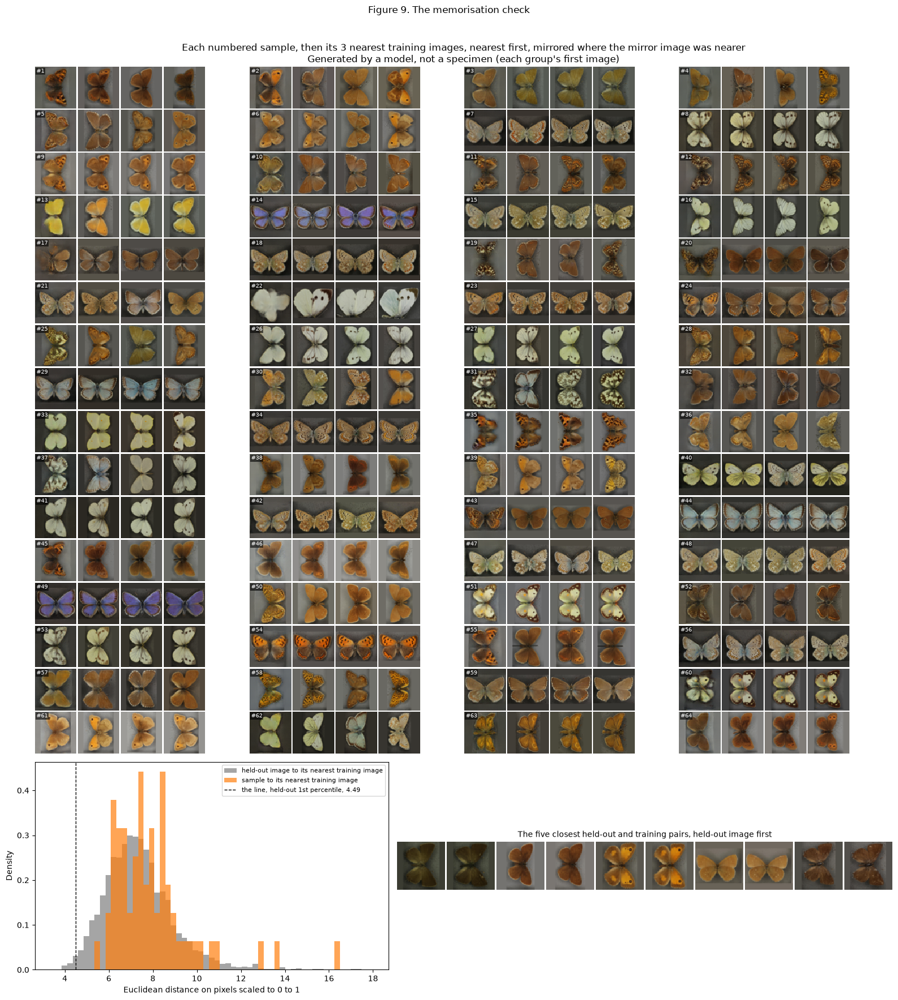

In [31]:
def nearest_training(queries, training, k=3, chunk=256):
    """The k nearest training images to each query, nearest first, as
    (distances, indices, mirrored), each a new array shaped (queries, k).

    Distance is Euclidean on the RGB values scaled to 0 to 1. The search
    takes every training image and its mirror image, and counts each
    training image once, at the nearer of the two; mirrored says which.
    Ties go to the lower training index and to the unmirrored image.
    Queries go chunk at a time."""
    # Squared distances on the 0 to 255 integers stay whole numbers far
    # below 2 to the 53, so float64 holds them exactly and ties are exact.
    t = training.reshape(len(training), -1).astype(np.float64)
    t_sq = (t * t).sum(axis=1)
    found = ([], [], [])
    for start in range(0, len(queries), chunk):
        stop = start + chunk
        q = queries[start:stop]
        views = []
        for view in (q, q[:, :, ::-1]):
            v = view.reshape(len(view), -1).astype(np.float64)
            d2 = (v * v).sum(axis=1)[:, None] + t_sq[None, :] - 2 * (v @ t.T)
            views.append(np.sqrt(np.maximum(d2, 0)) / 255)
        mirrored = views[1] < views[0]
        dist = np.where(mirrored, views[1], views[0])
        order = np.argsort(dist, axis=1, kind="stable")[:, :k]
        found[0].append(np.take_along_axis(dist, order, axis=1))
        found[1].append(order)
        found[2].append(np.take_along_axis(mirrored, order, axis=1))
    return tuple(np.concatenate(part) for part in found)


def matched(training, indices, mirrored):
    """The training images at indices as each was matched, flipped left to
    right where mirrored, as a new array shaped (*indices.shape, 64, 64,
    3)."""
    out = training[indices].copy()
    out[mirrored] = out[mirrored][:, :, ::-1]
    return out


def neighbour_layout(samples, neighbours, groups_per_row=4):
    """Each sample followed by its neighbours and one blank tile, groups in
    rows of groups_per_row, tiled as one new uint8 array."""
    blank = np.full((1, *samples.shape[1:]), 255, dtype=np.uint8)
    groups = [
        np.concatenate([samples[[k]], neighbours[k], blank])
        for k in range(len(samples))
    ]
    per_group = len(groups[0])
    return tile(np.concatenate(groups), cols=groups_per_row * per_group)


started = time.perf_counter()
sample_d, sample_i, sample_m = nearest_training(samples, training_images, k=3)
held_d, held_i, held_m = nearest_training(held_out_images, training_images, 1)
print(
    f"Searched {len(training_images):,} training images and their mirror "
    f"images in {time.perf_counter() - started:.0f} s"
)
line = float(np.percentile(held_d[:, 0], 1))
below = np.flatnonzero(sample_d[:, 0] < line) + 1
print(
    f"Held-out baseline: each of the {len(held_d):,} held-out images "
    f"against its nearest training image, distances {held_d.min():.2f} to "
    f"{held_d.max():.2f}, median {np.median(held_d):.2f}. The 1st "
    f"percentile, the line: {line:.3f}"
)
print(
    f"The 64 samples' nearest training images: distances "
    f"{sample_d[:, 0].min():.2f} to {sample_d[:, 0].max():.2f}, median "
    f"{np.median(sample_d[:, 0]):.2f}. Samples below the line: "
    f"{', '.join(f'#{n}' for n in below) if len(below) else 'none'}"
)
closest = np.argsort(sample_d[:, 0], kind="stable")[:5] + 1
print(
    "The five samples nearest a training image: "
    + ", ".join(f"#{n} at {sample_d[n - 1, 0]:.2f}" for n in closest)
)
pairs = np.argsort(held_d[:, 0], kind="stable")[:5]
held_at = np.flatnonzero((rows["part"] == "held_out").to_numpy())
train_at = np.flatnonzero((rows["part"] == "training").to_numpy())
print("The five closest held-out and training pairs, by catalogue number:")
for k in pairs:
    h = manifest.iloc[held_at[k]]
    t = manifest.iloc[train_at[held_i[k, 0]]]
    print(
        f"  {held_d[k, 0]:.2f}: held-out {h['catalog_number']} "
        f"{h['genus']} {h['species']}, training {t['catalog_number']} "
        f"{t['genus']} {t['species']}{', mirrored' if held_m[k, 0] else ''}"
    )

size = samples.shape[1]
fig = plt.figure(figsize=(16, 18))
grid = fig.add_gridspec(2, 2, height_ratios=[3.3, 1], width_ratios=[1, 1.4])
ax = fig.add_subplot(grid[0, :])
ax.imshow(
    neighbour_layout(samples, matched(training_images, sample_i, sample_m)),
    interpolation="nearest",
)
for k in range(len(samples)):
    row, group = divmod(k, 4)
    ax.text(
        group * 5 * (size + 2) + 2,
        row * (size + 2) + 2,
        f"#{k + 1}",
        color="white",
        fontsize=7,
        va="top",
        ha="left",
        bbox={"facecolor": "black", "alpha": 0.6, "pad": 1, "lw": 0},
    )
ax.set_title(
    "Each numbered sample, then its 3 nearest training images, nearest "
    "first, mirrored where the mirror image was nearer\n"
    "Generated by a model, not a specimen (each group's first image)"
)
ax.axis("off")
ax = fig.add_subplot(grid[1, 0])
low = min(held_d.min(), sample_d.min()) - 0.5
bins = np.linspace(low, max(held_d.max(), sample_d.max()) + 0.5, 60)
ax.hist(
    held_d[:, 0],
    bins=bins,
    density=True,
    color="tab:grey",
    alpha=0.7,
    label="held-out image to its nearest training image",
)
ax.hist(
    sample_d[:, 0],
    bins=bins,
    density=True,
    color="tab:orange",
    alpha=0.7,
    label="sample to its nearest training image",
)
ax.axvline(
    line,
    color="black",
    linestyle="--",
    linewidth=1,
    label=f"the line, held-out 1st percentile, {line:.2f}",
)
ax.set_xlabel("Euclidean distance on pixels scaled to 0 to 1")
ax.set_ylabel("Density")
ax.legend(fontsize=8)
ax = fig.add_subplot(grid[1, 1])
pair_images = np.concatenate(
    [
        np.stack(
            [
                held_out_images[k],
                matched(training_images, held_i[[k]], held_m[[k]])[0, 0],
            ]
        )
        for k in pairs
    ]
)
ax.imshow(tile(pair_images, cols=10), interpolation="nearest")
ax.set_title(
    "The five closest held-out and training pairs, held-out image first",
    fontsize=10,
)
ax.axis("off")
fig.suptitle("Figure 9. The memorisation check")
fig.tight_layout(rect=(0, 0, 1, 0.97))
save_figure(fig, 9, "memorisation_check")
plt.show()

**What the memorisation check shows.** None of the 64 samples is nearer a training image than the line of 4.495, set from the held-out images, and the nearest is #38 at 5.53. Figure 9 sets each sample beside its three nearest training images, and the positive control below tests what the line catches.

**A positive control for the memorisation check.** The check above found no sample below its line, which says nothing unless the line catches copies it should. So I make known near-copies of 16 training images, the first 16 of the 64 drawn with seed 42, and search for each one exactly as for a sample. Each image is copied ten times, and each copy is changed in one way, so there are 160 copies. Gaussian noise has a standard deviation of 2, 5 or 10 on the 0 to 255 scale, and a Gaussian blur a radius of 0.5 or 1 pixel. JPEG recompression is at quality 90, 75 or 50, and a shift moves the image right by 1 or 2 pixels. A copy is caught when its nearest training image is below the line. The table gives, for each change, the copies caught, how many found their own source as the nearest image, and the median distance.

In [32]:
import io  # noqa: E402

from PIL import Image, ImageFilter  # noqa: E402


def perturbed(images, kind, level, seed):
    """A changed copy of the uint8 images, as a new uint8 array.

    kind is "noise", Gaussian noise with standard deviation level on the 0
    to 255 scale, drawn from seed; "blur", a Gaussian blur of radius level
    pixels; "jpeg", JPEG recompression at quality level; or "shift", a shift
    right by level pixels with the left edge repeated. Level 0 changes
    nothing for noise, blur and shift. Another kind raises ValueError."""
    images = np.asarray(images, dtype=np.uint8)
    if kind not in ("noise", "blur", "jpeg", "shift"):
        raise ValueError(f"no change called {kind!r}")
    if kind != "jpeg" and level == 0:
        return images.copy()
    if kind == "noise":
        noise = np.random.default_rng(seed).normal(0, level, images.shape)
        return np.clip(np.round(images + noise), 0, 255).astype(np.uint8)
    if kind == "shift":
        edge = np.repeat(images[:, :, :1], level, axis=2)
        return np.concatenate([edge, images[:, :, :-level]], axis=2)
    out = []
    for image in images:
        picture = Image.fromarray(image)
        if kind == "blur":
            picture = picture.filter(ImageFilter.GaussianBlur(level))
        else:
            buffer = io.BytesIO()
            picture.save(buffer, format="JPEG", quality=level)
            buffer.seek(0)
            picture = Image.open(buffer).convert("RGB")
        out.append(np.asarray(picture))
    return np.stack(out)


def memorisation_control(training, sources, changes, line, seed):
    """How often the memorisation check catches known near-copies of the
    training images at sources, one row per change, as a new frame.

    Each change is a (kind, level) pair for perturbed. Each copy is searched
    against every training image and its mirror image, as a sample is, and
    is caught when its nearest distance is below line. The frame gives the
    copies made, those caught, those whose nearest image is their own
    source, and the median nearest distance."""
    found = []
    for kind, level in changes:
        copies = perturbed(training[sources], kind, level, seed)
        distance, index, _ = nearest_training(copies, training, k=1)
        found.append(
            {
                "change": kind,
                "level": level,
                "copies": len(copies),
                "caught": int((distance[:, 0] < line).sum()),
                "source nearest": int((index[:, 0] == sources).sum()),
                "median distance": float(np.median(distance[:, 0])),
            }
        )
    return pd.DataFrame(found)


CHANGES = [
    ("noise", 2),
    ("noise", 5),
    ("noise", 10),
    ("blur", 0.5),
    ("blur", 1),
    ("jpeg", 90),
    ("jpeg", 75),
    ("jpeg", 50),
    ("shift", 1),
    ("shift", 2),
]
control_sources = reference_index[:16]
control = memorisation_control(
    training_images, control_sources, CHANGES, line, SEED_TRAIN
)
print(
    f"The positive control: {len(control_sources)} training images (seed "
    f"{SEED_TRAIN}), each changed as below and searched as a sample is. "
    f"A copy is caught below the line of {line:.3f}."
)
print(control.round(2).to_string(index=False))
print(
    f"Caught in all: {control['caught'].sum()} of {control['copies'].sum()} "
    "near-copies"
)

The positive control: 16 training images (seed 42), each changed as below and searched as a sample is. A copy is caught below the line of 4.495.
change  level  copies  caught  source nearest  median distance
 noise    2.0      16      16              16             0.88
 noise    5.0      16      16              16             2.18
 noise   10.0      16      16              16             4.36
  blur    0.5      16      16              16             1.12
  blur    1.0      16      16              16             2.93
  jpeg   90.0      16      16              16             2.13
  jpeg   75.0      16      16              16             2.81
  jpeg   50.0      16      15              16             3.33
 shift    1.0      16       6              16             4.86
 shift    2.0      16       0              13             7.17
Caught in all: 133 of 160 near-copies


**What the check shows, and its limits.**
- **None of the 64 samples crossed this heuristic threshold,** the line of 4.495. The nearest is #38, at 5.53 from its nearest training image, and the samples' median, 7.63, sits close to the held-out images' median of 7.22. So by this check no sample is a near pixel-for-pixel copy of a training image or of its mirror image.
- **The positive control shows what the line catches.** It caught every copy with Gaussian noise up to a standard deviation of 10, every blurred copy, and every JPEG copy at quality 90 and 75. At quality 50 it caught 15 of 16. Noise of 10 already sits close to the line, at a median distance of 4.36, so heavier noise would pass. A shift of one pixel was caught in 6 of 16 copies and a shift of two in none, though 13 of those 16 still found their own source as the nearest image. In all, it caught 133 of the 160 copies. So the line catches light pixel-level changes to a whole image and misses small shifts.
- **The neighbours share a sample's family and colour, and often its wing shape, but by this check none is a copy.** #22's nearest training images are large whites, so it reads as a failed white rather than a label.
- **The closest held-out and training pairs are different specimens of one species,** from 3.87, four of the five with close catalogue numbers, such as BMNH(E)1290870 and BMNH(E)1290871. I take it they were photographed in one session, which is my inference from the numbers. If so, the line is set by how alike two real specimens photographed together can be, and splitting by specimen still leaves such near twins on both sides.
- **The limits.** Theis et al. (2016, sec. 3.4, p. 6) "argue that it is unfit to detect any but the starkest forms of overfitting". They suggest "showing more than one nearest neighbor", which is why each sample shows three. Distances on raw pixels are fragile: "a shift by only two pixels already caused a different nearest neighbor" (Theis et al., 2016, p. 6), and the control shows a two-pixel shift passing this line. They also warn that "A model which stores transformed training images can trivially pass the nearest-neighbor overfitting test", which is why the search includes mirror images. The mirror search covers only one such transform. So a shifted copy, or a model that copied parts of training images, could still pass. This check finds only near pixel-for-pixel copies of whole images, or of their mirror images, and cannot rule out memorisation in other forms.

**Supplementary measures, S1 and S2 (Figure 10).** Two simple measures from my own data, labelled supplementary because no source I hold proposes them for this use. The qualitative evaluation above is the core. Goodfellow et al. (2016, sec. 20.14, p. 715) note that "the choice of metric must match the intended use of the model." Neither measure needs a pre-trained network, which this project chose not to use. That is also why there is no Fréchet Inception Distance: Heusel et al. (2017, sec. 3, p. 6) compute it from "the coding layer of an inception model".
- **S1, colour histogram distance.** Per channel, 32 bins on 0 to 255, the total variation distance between the pooled histograms of the 64 samples and of all held-out images. Beside it is the same for 64 real training images (seed 42), as a reference for what a sample of 64 real images scores.
- **S2, sample diversity.** The mean pairwise Euclidean distance among the 64 samples, against the same among the 64 held-out images of Figure 8.

Supplementary measure S1, colour histogram distance against all 2,200 held-out images (total variation, 32 bins a channel; 0 is the same colours, 1 none shared):
                                red  green   blue   mean
64 samples                    0.053  0.058  0.074  0.062
64 training images (seed 42)  0.064  0.088  0.072  0.075

Supplementary measure S2, sample diversity, the mean pairwise Euclidean distance on the 0 to 255 pixel scale:
  64 samples: 4,956.8
  64 held-out images (seed 7): 4,968.2
  samples against held-out: 1.00


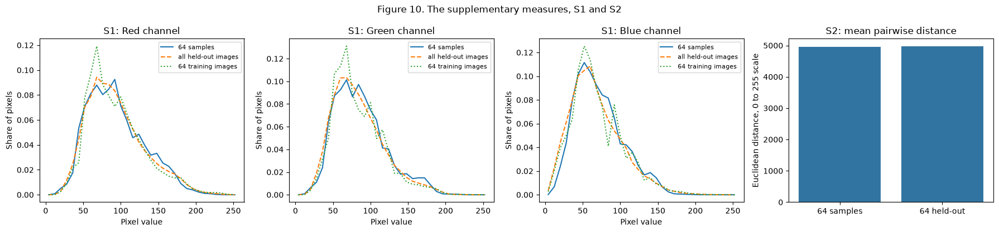

In [33]:
def colour_tv(a, b, bins=32):
    """The total variation distance between the pooled colour histograms of
    the images a and of the images b, one per channel, as a new array of
    three. Each histogram has bins equal bins on 0 to 255."""
    out = []
    for c in range(3):
        ha, _ = np.histogram(a[..., c], bins=bins, range=(0, 256))
        hb, _ = np.histogram(b[..., c], bins=bins, range=(0, 256))
        out.append(0.5 * np.abs(ha / ha.sum() - hb / hb.sum()).sum())
    return np.array(out)


training_64 = training_images[reference_index]
s1 = {
    "64 samples": colour_tv(samples, held_out_images),
    "64 training images (seed 42)": colour_tv(training_64, held_out_images),
}
s1_table = pd.DataFrame(s1, index=["red", "green", "blue"]).T
s1_table["mean"] = s1_table.mean(axis=1)
print(
    "Supplementary measure S1, colour histogram distance against all "
    f"{len(held_out_images):,} held-out images (total variation, 32 bins "
    "a channel; 0 is the same colours, 1 none shared):"
)
print(s1_table.round(3).to_string())
s2 = {
    "64 samples": mean_pairwise_distance(samples),
    f"64 held-out images (seed {SEED_SAMPLES})": mean_pairwise_distance(
        held_out_images[held_64]
    ),
}
ratio = s2["64 samples"] / list(s2.values())[1]
print(
    "\nSupplementary measure S2, sample diversity, the mean pairwise "
    "Euclidean distance on the 0 to 255 pixel scale:"
)
for name, value in s2.items():
    print(f"  {name}: {value:,.1f}")
print(f"  samples against held-out: {ratio:.2f}")

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
edges = np.linspace(0, 256, 33)
centres = (edges[:-1] + edges[1:]) / 2
groups = {
    "64 samples": samples,
    "all held-out images": held_out_images,
    "64 training images": training_64,
}
for c, (ax, name) in enumerate(zip(axes, ("Red", "Green", "Blue"))):
    for (label, images), style in zip(groups.items(), ("-", "--", ":")):
        counts, _ = np.histogram(images[..., c], bins=edges)
        sns.lineplot(
            x=centres,
            y=counts / counts.sum(),
            ax=ax,
            label=label,
            linestyle=style,
        )
    ax.set_title(f"S1: {name} channel")
    ax.set_xlabel("Pixel value")
    ax.set_ylabel("Share of pixels")
    ax.legend(fontsize=8)
sns.barplot(
    x=["64 samples", "64 held-out"],
    y=list(s2.values()),
    ax=axes[3],
    color="tab:blue",
)
axes[3].set_title("S2: mean pairwise distance")
axes[3].set_ylabel("Euclidean distance, 0 to 255 scale")
fig.suptitle("Figure 10. The supplementary measures, S1 and S2")
fig.tight_layout()
save_figure(fig, 10, "supplementary_measures")
plt.show()

**What the supplementary measures show.** S1: the samples' colours sit as close to the held-out images' as 64 real training images do, with a mean distance of 0.062 against 0.075. S2: this draw of samples has a mean pixel-space dispersion like the held-out images', a ratio of 1.00, and Figure 8 shows several kinds of butterfly among them. With F4's ratio in Task 3, that shows no obvious gross collapse in the samples I inspected. It does not show how well the samples cover the species or families, which I did not measure. Both measures read colour and spread only. They cannot tell whether a wing is the right shape, which is what the scoring criteria read.

**Optional extra: an idea I ran and tested, the discriminator as a quality flag.** This test is optional. Task 1 proposes the trained discriminator as a quality flag for museum digitisation, and here I run that idea once, on this project's own discriminator. The evaluated run's discriminator, in evaluation mode, scores the 64 held-out images of Figure 8, 64 training images, the 64 samples and 34 known oddities. The oddities are the crops scored as failures by eye on the crop rule's contact sheets before training, read from the crop audit's file (Task 2). Of them, 21 kept part of a label or card, and 13 cut the specimen. If the idea works, the oddities score lower than the held-out images. The last column gives the share of pairs, one from the group and one held-out image, in which the group's image scores lower, with a tie counted as half. A share of 0.5 means no separation, and 1 means every image in the group scores below every held-out image.

In [34]:
def discriminator_scores(discriminator, images, device, chunk=256):
    """The discriminator's score for each uint8 image, as a new array.
    It runs in evaluation mode under no_grad, chunk images at a time, then
    goes back to the mode it came in."""
    was_training = discriminator.training
    discriminator.eval()
    out = []
    with torch.no_grad():
        for start in range(0, len(images), chunk):
            stop = start + chunk
            out.append(
                discriminator(to_batch(images[start:stop], device)).cpu()
            )
    discriminator.train(was_training)
    return torch.cat(out).numpy().astype(np.float64)


def share_lower(odd, normal):
    """The share of (odd, normal) pairs in which the odd score is lower,
    with a tie counted as half, as a float."""
    odd = np.asarray(odd, dtype=float)[:, None]
    normal = np.asarray(normal, dtype=float)[None, :]
    return float(((odd < normal) + 0.5 * (odd == normal)).mean())


# The audit's 34 failures, as crops, come from the scoring cell above. Most
# are training crops, which the discriminator saw in training.
odd_part = rows["part"].to_numpy()[odd_rows]
odd_scores = discriminator_scores(discriminator_eval, odd_crops, device)
held_scores = discriminator_scores(
    discriminator_eval, held_out_images[held_64], device
)
score_groups = {
    f"64 held-out images (seed {SEED_SAMPLES})": held_scores,
    "64 training images (seed 42)": discriminator_scores(
        discriminator_eval, training_images[reference_index], device
    ),
    "64 samples": discriminator_scores(discriminator_eval, samples, device),
    f"{len(odd_scores)} oddities": odd_scores,
    "oddities, label or card kept": odd_scores[label_kept],
    "oddities, specimen cut": odd_scores[~label_kept],
    "oddities, held-out ones": odd_scores[odd_part == "held_out"],
}
table = pd.DataFrame(
    [
        {
            "group": name,
            "images": len(v),
            "mean": v.mean(),
            "median": np.median(v),
            "lowest": v.min(),
            "highest": v.max(),
            "share scored below a held-out image": share_lower(v, held_scores),
        }
        for name, v in score_groups.items()
    ]
)
print(
    f"Run {ev_run}'s discriminator at epoch {ev_epoch}, in evaluation mode: "
    "its score for each group"
)
with pd.option_context("display.width", 160):
    print(table.round(3).to_string(index=False))
print(
    f"Of the {len(odd_scores)} oddities, {np.sum(odd_part == 'training')} "
    "are training crops the discriminator saw in training and "
    f"{np.sum(odd_part == 'held_out')} are held out. No label-only "
    "photograph is on disk, because the download kept specimen photographs "
    "only, so none is scored."
)

Run 1's discriminator at epoch 100, in evaluation mode: its score for each group
                       group  images  mean  median  lowest  highest  share scored below a held-out image
 64 held-out images (seed 7)      64 0.350   0.333   0.055    0.957                                0.500
64 training images (seed 42)      64 0.457   0.447   0.092    0.891                                0.327
                  64 samples      64 0.056   0.039   0.009    0.332                                0.966
                 34 oddities      34 0.490   0.462   0.146    0.970                                0.303
oddities, label or card kept      21 0.438   0.442   0.146    0.816                                0.362
      oddities, specimen cut      13 0.573   0.561   0.212    0.970                                0.209
     oddities, held-out ones       4 0.339   0.316   0.146    0.576                                0.500
Of the 34 oddities, 30 are training crops the discriminator saw in training and

**What the test shows.** I ran the idea and it failed: in this exploratory comparison, this discriminator showed no useful separation of odd photographs from held-out ones. The oddities score higher than the held-out images, not lower: a mean of 0.490 against 0.350, and an oddity scores below a held-out image in only 30 per cent of pairs. The crops that cut the specimen score highest, at 0.573. The 64 training images score like the oddities, at 0.457, while the samples score 0.056. So this discriminator tells generated images from real ones, and it tends to score the images it trained on above unseen ones. Even against the 64 training images the oddities score a little higher, 0.490 against 0.457. The comparison is weak on both sides. The 64 held-out images are a random draw, not checked as normal. 30 of the 34 oddities were in training, which favours them, and the 4 held out are too few to judge. A firmer answer needs checked normal and odd groups, both kept out of training. A discriminator that favours its own training images fits the discriminator overfitting Karras et al. (2020, p. 12104) describe. I keep this negative result, because it tests Task 1's quality flag on my own model and data, and it shows what that use would need.

**What I would do differently with more or better data.**
- **A dedicated anomaly model.** I would train a model on photographs checked as normal, and on nothing else, as industrial inspection does. Bergmann et al. (2019, p. 9593) describe the set-up: "Defect-free example images of objects or textures are used to train a model that must determine whether an anomaly is present during test time."
- **Labelled oddities to validate against.** I would set aside a larger set of known failures, labelled by eye and kept out of training, to measure any flag against. Here 30 of the 34 oddities were in training, only 4 were held out, and no label-only photograph was on disk.
- **Cleaner crops.** About 6 per cent of crops failed by eye, and every training crop, failed or not, was a real image in training. So this discriminator was taught to call those failures real. A crop rule with fewer failures, or a training set checked by eye, would give a cleaner picture of normal.

**Run summary.** The hardware, the runs, the settings and the evaluated model, then the time. The GPU time is measured. The CPU time is estimated by timing 20 training steps on a CPU copy of the model after 5 warm-up steps, then scaling to the steps run. No CPU training run is made. The cell then frees the evaluation's networks from the GPU and prints the memory still held.

In [35]:
import tempfile  # noqa: E402


def cpu_step_seconds(images, settings, fixed_z, reference, warmup=5, timed=20):
    """Seconds per training step on the CPU, as a float: warmup steps in one
    fresh run of train_run, then timed steps in another, timed as that
    run's epoch. images is a CPU uint8 tensor and is not changed. Too few
    images for timed full batches raises ValueError."""
    if len(images) // settings["batch"] < timed:
        raise ValueError(f"{timed} full batches need more images")
    seconds = None
    for steps in (warmup, timed):
        trial = dict(settings, epochs=1, max_steps=steps, checkpoints=(0,))
        with tempfile.TemporaryDirectory() as folder:
            run = train_run(
                images,
                trial,
                fixed_z,
                reference,
                "cpu",
                False,
                folder,
                lambda *args: (None, None),
                lambda: None,
                say=lambda text: None,
            )
        seconds = run["epoch_seconds"][0] / steps
    return float(seconds)


cpu_images = torch.from_numpy(training_images).permute(0, 3, 1, 2).contiguous()
step_seconds = cpu_step_seconds(cpu_images, RUN1, fixed_z[:8], f4_reference)
del cpu_images
per_epoch = len(training_images) // RUN1["batch"]
cpu_hours = step_seconds * per_epoch * RUN1["epochs"] * len(runs) / 3600
epoch_seconds = np.concatenate([runs[k]["epoch_seconds"] for k in runs])
run_seconds = sum(runs[k]["seconds"] for k in runs)
# The training device names the measured rows, so a CPU run says so.
trained_on = "GPU" if on_gpu else "CPU"
ev_means = runs[ev_run]["log"][ev_epoch - 1].mean(axis=0)
summary = [
    ("hardware", f"{torch.cuda.get_device_name(0) if on_gpu else 'CPU only'}"),
    ("runs made", f"{len(runs)}, as the checkpoint rule called them"),
    ("epochs a run", RUN1["epochs"]),
    ("batch size", f"{RUN1['batch']}, {per_epoch} full batches an epoch"),
    (
        "evaluated model",
        f"{submitted['generator_ema']}, run {ev_run} at epoch {ev_epoch}",
    ),
    ("its epoch's mean losses", f"D {ev_means[0]:.3f}, G {ev_means[1]:.3f}"),
    (
        "its epoch's mean D(x), D(G(z))",
        f"{ev_means[2]:.3f}, {ev_means[3]:.3f}",
    ),
    (
        f"{trained_on} seconds an epoch, median",
        f"{np.median(epoch_seconds):.1f}",
    ),
    (
        f"{trained_on} training time, all runs",
        f"{run_seconds / 60:.1f} minutes",
    ),
    (
        "CPU seconds a step, timed",
        f"{step_seconds:.2f} on " f"{torch.get_num_threads()} threads",
    ),
    ("estimated CPU time, all runs", f"{cpu_hours:.1f} hours"),
]
print("Run summary:")
print(pd.DataFrame(summary, columns=["item", "value"]).to_string(index=False))
print(
    "The estimated CPU time scales the seconds a step, from 20 CPU steps "
    f"timed after 5 warm-up steps, to {RUN1['epochs'] * per_epoch:,} steps "
    f"a run and {len(runs)} runs. It moves with the number of CPU threads."
)

# I free the evaluation's networks and arrays from the GPU last.
del generator_eval, discriminator_eval
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()
    print(
        "GPU memory held by PyTorch after Task 4: "
        f"{torch.cuda.memory_allocated() / 2**20:.0f} MiB allocated, "
        f"{torch.cuda.memory_reserved() / 2**20:.0f} MiB reserved"
    )
else:
    print("No GPU in use, so 0 MiB allocated on one")

Run summary:
                          item                                       value
                      hardware                     NVIDIA GeForce RTX 5090
                     runs made       3, as the checkpoint rule called them
                  epochs a run                                         100
                    batch size              128, 154 full batches an epoch
               evaluated model models/generator_ema.pt, run 1 at epoch 100
       its epoch's mean losses                            D 0.559, G 3.979
its epoch's mean D(x), D(G(z))                                0.827, 0.073
  GPU seconds an epoch, median                                         4.5
   GPU training time, all runs                                22.1 minutes
     CPU seconds a step, timed                          0.38 on 16 threads
  estimated CPU time, all runs                                   4.8 hours
The estimated CPU time scales the seconds a step, from 20 CPU steps timed after 5 warm-

**What the run summary shows.** The three runs took 22.1 minutes of GPU training on the RTX 5090, against an estimated 4.8 hours on this rig's CPU. The model evaluated in Task 4 is run 1's EMA generator at epoch 100, saved as `models/generator_ema.pt`.

## Task 5: Write a Short Notebook Summary

**The task:** I trained a deep convolutional generative adversarial network (DCGAN) from scratch to make new 64 by 64 colour images of pinned butterflies, from 19,800 Natural History Museum specimen photographs.

**The outputs:** Most of the 64 numbered samples read as plausible specimens on a museum tray, the blues and browns most of all.

**The challenge:** My pre-set failure flags fired at epoch 10 in all three runs, on a first-epoch generator-loss spike or unvaried samples, so they picked a near-untrained model and I chose mine after seeing the outputs.

**The limits:** Bodies and fine wing patterns are often faint, blurred or unmatched between the two halves of a sample.

**The failures:** A few samples fail outright, such as a white blob with no wings (#22) and pale wings blended into four lobes (#60).